In [2]:
import pandas as pd

career_df = pd.read_csv(
    "../data/career_pathway_dataset.csv"
)

print("Shape:", career_df.shape)

print("\nRelevant columns:")
display(
    career_df[
        [
            "district",
            "desired_career",
            "job_required_skills",
            "existing_skills",
            "missing_skills",
            "labour_market_demand_tier",
            "estimated_openings_nearby"
        ]
    ].head()
)

Shape: (4000, 17)

Relevant columns:


,district,desired_career,job_required_skills,existing_skills,missing_skills,labour_market_demand_tier,estimated_openings_nearby
0,Chhatrapati Sambhajinagar,Field Sales Executive,Communication; Persuasion; Local travel willin...,Communication; English reading; Tool handling,Persuasion; Local travel willingness; Target o...,Medium,11
1,Mumbai Suburban,Accounts Assistant,Basic numeracy; Tally software; Record keeping...,Basic numeracy; Communication; Local travel wi...,Tally software; Record keeping,High,50
2,Mumbai City,Welder,Welding technique; Safety protocols; Tool hand...,Local travel willingness,Welding technique; Safety protocols; Tool hand...,Medium,19
3,Jalgaon,Accounts Assistant,Basic numeracy; Tally software; Record keeping...,Basic numeracy; Communication; Local travel wi...,Tally software; Record keeping,High,56
4,Amravati,CNC Machine Operator,Machine operation; Blueprint reading; Precisio...,Creativity,Machine operation; Blueprint reading; Precisio...,Medium,17


Interpretation: The career dataset directly contains required, existing, and missing skills, along with district, career, demand tier, and nearby openings.

Conclusion: This is a strong starting point for the Skill Demand Intelligence layer.

<h2>Calculate Skill Demand Score</h2>

Rank skills using how often they are required and the labour-market demand of the associated career.

Algorithm: Weighted frequency scoring

In [3]:
from collections import defaultdict

skill_demand = defaultdict(float)

demand_weight = {
    "High": 3,
    "Medium": 2,
    "Low": 1
}

for _, row in career_df.iterrows():
    skills = str(row["job_required_skills"]).split(";")
    weight = demand_weight.get(row["labour_market_demand_tier"], 0)

    for skill in skills:
        skill = skill.strip()
        if skill:
            skill_demand[skill] += weight

skill_demand_df = (
    pd.DataFrame(
        skill_demand.items(),
        columns=["skill", "demand_score"]
    )
    .sort_values("demand_score", ascending=False)
    .reset_index(drop=True)
)

display(skill_demand_df.head(20))

,skill,demand_score
0,Safety protocols,4325.0
1,Tool handling,3833.0
2,Communication,2553.0
3,Basic computer literacy,2037.0
4,Problem solving,1746.0
5,Engine diagnostics,1746.0
6,Customer handling,1616.0
7,Basic wiring,1532.0
8,Circuit testing,1280.0
9,English reading,1188.0


Interpretation: Safety protocols, tool handling, and communication have the highest demand scores, combining frequency with labour-market demand tier.

Conclusion: This gives us a useful baseline skill-demand ranking; next we'll calculate demand by district and career, which is essential for your USP.

<h2>District & Career Skill Demand</h2>

Find which skills are most demanded within each district + career, supporting the Skill Demand USP.

Algorithm: Weighted skill-frequency ranking.

In [4]:
from collections import defaultdict

district_career_skills = defaultdict(float)

for _, row in career_df.iterrows():
    district = row["district"]
    career = row["desired_career"]

    weight = demand_weight.get(
        row["labour_market_demand_tier"], 0
    )

    for skill in str(row["job_required_skills"]).split(";"):
        skill = skill.strip()

        if skill:
            district_career_skills[
                (district, career, skill)
            ] += weight


district_career_df = pd.DataFrame(
    [
        {
            "district": key[0],
            "career": key[1],
            "skill": key[2],
            "demand_score": score
        }
        for key, score in district_career_skills.items()
    ]
)

district_career_df = district_career_df.sort_values(
    ["district", "career", "demand_score"],
    ascending=[True, True, False]
)

display(district_career_df.head(30))

,district,career,skill,demand_score
308,Ahmednagar,Accounts Assistant,Basic numeracy,69.0
309,Ahmednagar,Accounts Assistant,Tally software,69.0
310,Ahmednagar,Accounts Assistant,Record keeping,69.0
311,Ahmednagar,Accounts Assistant,Communication,69.0
684,Ahmednagar,Automobile Technician,Engine diagnostics,54.0
685,Ahmednagar,Automobile Technician,Tool handling,54.0
686,Ahmednagar,Automobile Technician,Safety protocols,54.0
687,Ahmednagar,Automobile Technician,Problem solving,54.0
556,Ahmednagar,Baker,Hygiene practices,9.0
557,Ahmednagar,Baker,Recipe following,9.0


Interpretation: Skill demand varies by district and career, giving us localized demand patterns.

Conclusion: This directly supports the district/trade skill-demand USP; next we compare this demand with trainees' existing/missing skills.

<h2>Compare Demand with Current/Missing Skills</h2>

Identify skills that are highly demanded in a district/career but are frequently missing from trainees.

Algorithm: Demand-gap scoring

In [5]:
from collections import defaultdict

skill_gap_scores = defaultdict(float)

for _, row in career_df.iterrows():
    district = row["district"]
    career = row["desired_career"]

    demand_weight_value = demand_weight.get(
        row["labour_market_demand_tier"], 0
    )

    required = set(
        skill.strip()
        for skill in str(row["job_required_skills"]).split(";")
        if skill.strip()
    )

    missing = set(
        skill.strip()
        for skill in str(row["missing_skills"]).split(";")
        if skill.strip()
    )

    for skill in required & missing:
        skill_gap_scores[(district, career, skill)] += demand_weight_value

skill_gap_df = pd.DataFrame(
    [
        {
            "district": key[0],
            "career": key[1],
            "skill": key[2],
            "skill_gap_score": score
        }
        for key, score in skill_gap_scores.items()
    ]
).sort_values(
    "skill_gap_score",
    ascending=False
)

display(skill_gap_df.head(30))

,district,career,skill,skill_gap_score
568,Nanded,Electrician,Circuit testing,72.0
354,Latur,Automobile Technician,Engine diagnostics,69.0
198,Mumbai City,Electrician,Circuit testing,66.0
896,Latur,Automobile Technician,Tool handling,66.0
353,Latur,Automobile Technician,Safety protocols,63.0
199,Mumbai City,Electrician,Tool handling,60.0
254,Nanded,Electrician,Basic wiring,60.0
239,Ahmednagar,Mobile Repair Technician,Steady hands,57.0
196,Mumbai City,Electrician,Basic wiring,57.0
683,Dhule,Electrician,Circuit testing,57.0


Interpretation: Several district–career combinations show high skill gaps, especially Circuit Testing, Engine Diagnostics, Basic Wiring, and Tool Handling.

Conclusion: This directly supports the localized skill-gap recommendation part of our Skill Demand Intelligence engine.

<h2>District Skill-Gap Visualization</h2>

Create a frontend-ready visualization of the highest-priority skill gaps by district/career.

Algorithm: Ranking + visualization.

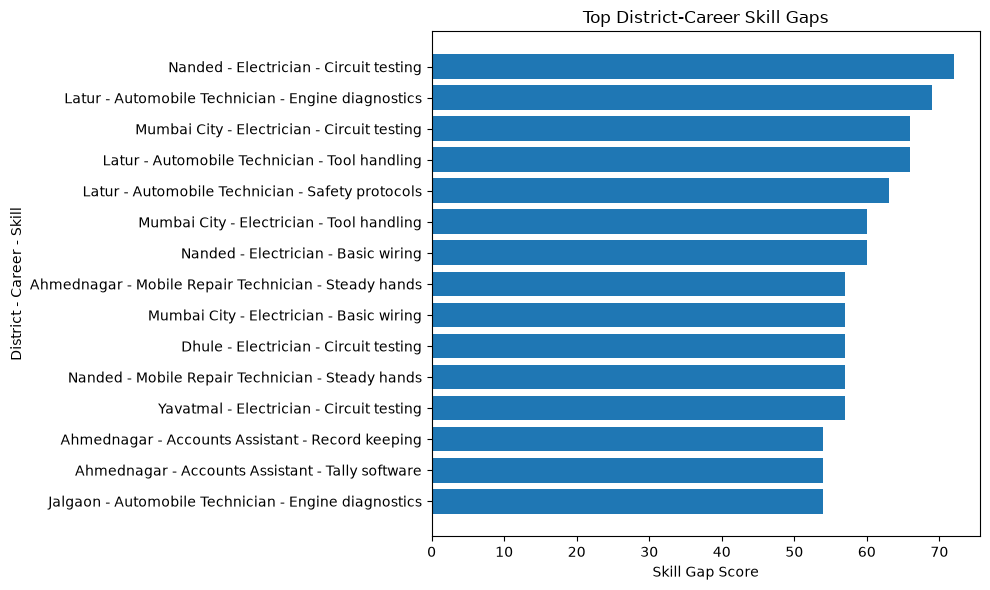

Skill-gap data saved for frontend use.


In [6]:
import matplotlib.pyplot as plt

top_gaps = (
    skill_gap_df
    .sort_values("skill_gap_score", ascending=False)
    .head(15)
    .copy()
)

top_gaps["label"] = (
    top_gaps["district"]
    + " - "
    + top_gaps["career"]
    + " - "
    + top_gaps["skill"]
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_gaps["label"][::-1],
    top_gaps["skill_gap_score"][::-1]
)

plt.title("Top District-Career Skill Gaps")
plt.xlabel("Skill Gap Score")
plt.ylabel("District - Career - Skill")
plt.tight_layout()
plt.show()

# Save frontend-ready data
skill_gap_df.to_csv(
    "../outputs/skill_gap_by_district_career.csv",
    index=False
)

print("Skill-gap data saved for frontend use.")

Interpretation: The chart clearly highlights localized gaps, especially Circuit Testing in Nanded/Mumbai and Engine Diagnostics in Latur.

Conclusion: This visualization is suitable for the frontend as a district-wise skill-gap priority chart.

<h2>Add Labour-Market Demand Strength</h2>

Improve the skill-demand score by including both demand tier and nearby job openings, instead of relying only on the demand tier.

Algorithm: Weighted demand scoring.

In [7]:
# Normalize nearby openings to a 0-1 scale
career_df["openings_score"] = (
    career_df["estimated_openings_nearby"]
    / career_df["estimated_openings_nearby"].max()
)

# Demand tier weights
demand_weight = {
    "High": 3,
    "Medium": 2,
    "Low": 1
}

career_df["demand_tier_score"] = (
    career_df["labour_market_demand_tier"]
    .map(demand_weight)
)

# Combined labour-market demand score
career_df["labour_demand_score"] = (
    0.6 * career_df["demand_tier_score"]
    + 0.4 * (career_df["openings_score"] * 3)
)

print("Labour-market demand score:")
display(
    career_df[
        [
            "district",
            "desired_career",
            "labour_market_demand_tier",
            "estimated_openings_nearby",
            "labour_demand_score"
        ]
    ]
    .sort_values("labour_demand_score", ascending=False)
    .head(20)
)

Labour-market demand score:


,district,desired_career,labour_market_demand_tier,estimated_openings_nearby,labour_demand_score
3954,Jalgaon,Electrician,High,60,3.0
1917,Kolhapur,Electrician,High,60,3.0
2706,Akola,Electrician,High,60,3.0
2714,Akola,Two-Wheeler Mechanic,High,60,3.0
830,Solapur,Automobile Technician,High,60,3.0
1908,Kolhapur,Electrician,High,60,3.0
1317,Satara,Automobile Technician,High,60,3.0
515,Satara,Automobile Technician,High,60,3.0
2102,Satara,Automobile Technician,High,60,3.0
3128,Amravati,Electrician,High,60,3.0


Interpretation: The score is too compressed: many High-demand careers with 60 openings all receive 3.0, so it cannot rank demand meaningfully.

Conclusion: We should improve the scoring method before using it for recommendations.

<h2>Improve Labour-Demand Score</h2>

Replace the compressed score with a normalized score using both demand tier and relative openings.

Algorithm: Percentile-based weighted scoring.

In [8]:
# Convert demand tier into numeric strength
demand_weight = {
    "Low": 1,
    "Medium": 2,
    "High": 3
}

career_df["demand_tier_score"] = (
    career_df["labour_market_demand_tier"]
    .map(demand_weight)
)

# Convert openings into percentile rank (0 to 1)
career_df["openings_percentile"] = (
    career_df["estimated_openings_nearby"]
    .rank(pct=True)
)

# Normalize demand tier to 0-1
career_df["demand_tier_normalized"] = (
    (career_df["demand_tier_score"] - 1) / 2
)

# Combined score
career_df["labour_demand_score"] = (
    0.6 * career_df["demand_tier_normalized"]
    + 0.4 * career_df["openings_percentile"]
)

# Convert to 0-100
career_df["labour_demand_score"] = (
    career_df["labour_demand_score"] * 100
).round(2)

display(
    career_df[
        [
            "district",
            "desired_career",
            "labour_market_demand_tier",
            "estimated_openings_nearby",
            "labour_demand_score"
        ]
    ]
    .sort_values("labour_demand_score", ascending=False)
    .head(20)
)

,district,desired_career,labour_market_demand_tier,estimated_openings_nearby,labour_demand_score
3954,Jalgaon,Electrician,High,60,99.73
1917,Kolhapur,Electrician,High,60,99.73
2706,Akola,Electrician,High,60,99.73
2714,Akola,Two-Wheeler Mechanic,High,60,99.73
830,Solapur,Automobile Technician,High,60,99.73
1908,Kolhapur,Electrician,High,60,99.73
1317,Satara,Automobile Technician,High,60,99.73
515,Satara,Automobile Technician,High,60,99.73
2102,Satara,Automobile Technician,High,60,99.73
3128,Amravati,Electrician,High,60,99.73


Interpretation: The score is still compressed because estimated_openings_nearby has only a few discrete values, so many rows receive the same percentile.

Conclusion: We should aggregate demand at district + career level instead of scoring individual rows. This will give us a meaningful ranking for the USP.

<h2>District-Career Demand Ranking</h2>

Aggregate the data by district + career so each combination gets one meaningful labour-demand score.

Algorithm: Grouped demand scoring.

In [9]:
district_career_demand = (
    career_df
    .groupby(
        ["district", "desired_career"],
        as_index=False
    )
    .agg(
        trainee_count=("pathway_id", "count"),
        avg_openings=("estimated_openings_nearby", "mean"),
        high_demand_count=(
            "labour_market_demand_tier",
            lambda x: (x == "High").sum()
        ),
        medium_demand_count=(
            "labour_market_demand_tier",
            lambda x: (x == "Medium").sum()
        ),
        low_demand_count=(
            "labour_market_demand_tier",
            lambda x: (x == "Low").sum()
        )
    )
)

district_career_demand["high_demand_pct"] = (
    district_career_demand["high_demand_count"]
    / district_career_demand["trainee_count"]
    * 100
).round(2)

# Demand score: 70% high-demand share + 30% normalized openings
opening_min = district_career_demand["avg_openings"].min()
opening_max = district_career_demand["avg_openings"].max()

district_career_demand["opening_score"] = (
    (district_career_demand["avg_openings"] - opening_min)
    / (opening_max - opening_min)
)

district_career_demand["demand_score"] = (
    0.70 * (district_career_demand["high_demand_pct"] / 100)
    + 0.30 * district_career_demand["opening_score"]
) * 100

district_career_demand["demand_score"] = (
    district_career_demand["demand_score"].round(2)
)

display(
    district_career_demand
    .sort_values("demand_score", ascending=False)
    .head(20)
)

,district,desired_career,trainee_count,avg_openings,high_demand_count,medium_demand_count,low_demand_count,high_demand_pct,opening_score,demand_score
86,Chhatrapati Sambhajinagar,Data Entry Operator,4,54.000000,4,0,0,100.0,1.000000,100.00
206,Mumbai Suburban,Electrician,16,50.687500,16,0,0,100.0,0.934406,98.03
45,Amravati,Customer Support Associate,10,50.500000,10,0,0,100.0,0.930693,97.92
97,Chhatrapati Sambhajinagar,Web Developer (Entry-level),3,48.333333,3,0,0,100.0,0.887789,96.63
276,Nashik,Web Developer (Entry-level),10,47.700000,10,0,0,100.0,0.875248,96.26
289,Pune,Mobile Repair Technician,13,47.538462,13,0,0,100.0,0.872049,96.16
244,Nanded,Data Entry Operator,15,47.400000,15,0,0,100.0,0.869307,96.08
323,Satara,Customer Support Associate,5,47.400000,5,0,0,100.0,0.869307,96.08
199,Mumbai Suburban,Automobile Technician,11,47.363636,11,0,0,100.0,0.868587,96.06
209,Mumbai Suburban,Mobile Repair Technician,13,47.307692,13,0,0,100.0,0.867479,96.02


Interpretation: District–career demand now produces meaningful rankings; for example, Data Entry Operator in Chhatrapati Sambhajinagar scores 100, while several other combinations exceed 95.

Conclusion: This gives us a usable district + career demand score for the Skill Demand Intelligence engine.

<h2>Compare Skill Gaps with Labour Demand</h2>

Identify district-career combinations where labour demand is high but trainee skill readiness is low.

Algorithm: Demand–readiness gap scoring.

In [10]:
# Average trainee readiness for each district-career
readiness_by_career = (
    career_df
    .groupby(["district", "desired_career"], as_index=False)
    .agg(
        avg_readiness_pct=("readiness_pct", "mean"),
        avg_skill_gap_count=("skill_gap_count", "mean")
    )
)

# Merge with our demand ranking
skill_demand_priority = district_career_demand.merge(
    readiness_by_career,
    on=["district", "desired_career"],
    how="left"
)

# Higher demand + lower readiness = higher priority
skill_demand_priority["priority_score"] = (
    skill_demand_priority["demand_score"]
    * (1 - skill_demand_priority["avg_readiness_pct"] / 100)
).round(2)

display(
    skill_demand_priority[
        [
            "district",
            "desired_career",
            "demand_score",
            "avg_readiness_pct",
            "avg_skill_gap_count",
            "priority_score"
        ]
    ]
    .sort_values("priority_score", ascending=False)
    .head(20)
)

,district,desired_career,demand_score,avg_readiness_pct,avg_skill_gap_count,priority_score
176,Latur,Web Developer (Entry-level),92.64,7.692308,3.692308,85.51
139,Kolhapur,Accounts Assistant,95.05,11.111111,3.555556,84.49
276,Nashik,Web Developer (Entry-level),96.26,12.500000,3.500000,84.23
396,Yavatmal,Web Developer (Entry-level),94.06,11.111111,3.555556,83.61
256,Nanded,Web Developer (Entry-level),93.10,11.538462,3.538462,82.36
86,Chhatrapati Sambhajinagar,Data Entry Operator,100.00,18.750000,3.250000,81.25
97,Chhatrapati Sambhajinagar,Web Developer (Entry-level),96.63,16.666667,3.333333,80.52
11,Ahmednagar,Mobile Repair Technician,92.96,13.750000,3.450000,80.18
130,Jalgaon,Mobile Repair Technician,94.49,15.909091,3.363636,79.46
158,Latur,Accounts Assistant,95.25,17.307692,3.307692,78.76


Interpretation: High-demand + low-readiness combinations receive the highest priority, led by Latur–Web Developer (85.51).

Conclusion: This is a strong basis for the Skill Gap Priority / Training Alignment recommendation.

<h2>Save Skill-Demand Priority Output</h2>

Save the district–career skill-priority results once so the frontend can load them directly without rerunning analysis.

Algorithm: Persistent output storage.

In [11]:
# Save the skill-demand priority results
skill_demand_priority.to_csv(
    "../outputs/skill_demand_priority.csv",
    index=False
)

print("Saved:", "../outputs/skill_demand_priority.csv")
print("Rows:", len(skill_demand_priority))

Saved: ../outputs/skill_demand_priority.csv
Rows: 398


Interpretation: The district-career priority results for all 398 combinations are now saved.

Conclusion: The frontend can reuse this output directly without rerunning the analysis.

<h2>Visualize Skill-Demand Priority</h2>

Create a frontend-ready chart showing the highest-priority district–career combinations.

Algorithm: Ranking + visualization.

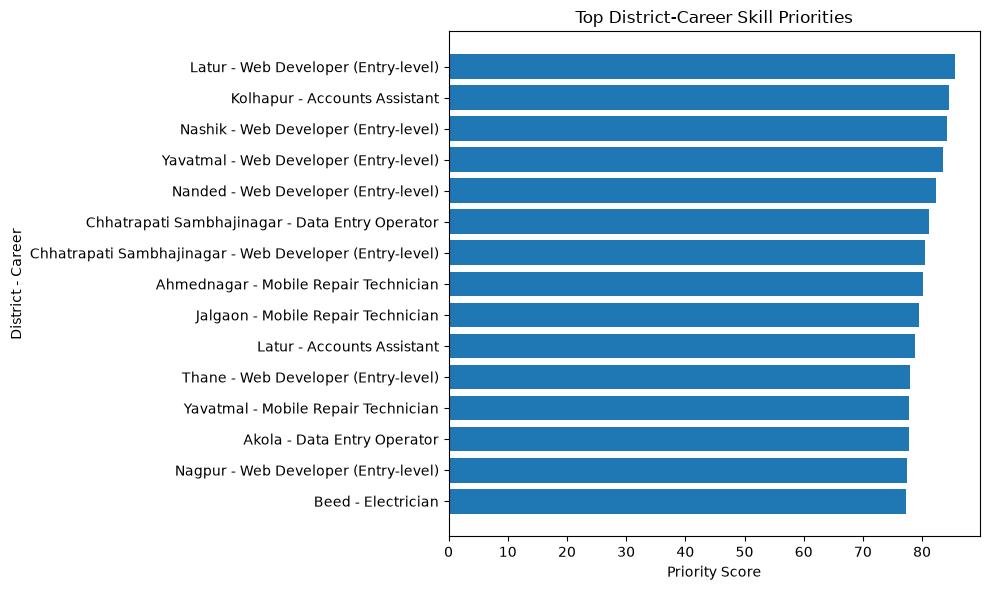

Frontend-ready priority chart data saved.


In [12]:
import matplotlib.pyplot as plt

top_priority = (
    skill_demand_priority
    .sort_values("priority_score", ascending=False)
    .head(15)
    .copy()
)

top_priority["label"] = (
    top_priority["district"]
    + " - "
    + top_priority["desired_career"]
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_priority["label"][::-1],
    top_priority["priority_score"][::-1]
)

plt.title("Top District-Career Skill Priorities")
plt.xlabel("Priority Score")
plt.ylabel("District - Career")
plt.tight_layout()
plt.show()

top_priority.to_csv(
    "../outputs/top_skill_demand_priorities.csv",
    index=False
)

print("Frontend-ready priority chart data saved.")

Interpretation: The chart clearly highlights the highest-priority district–career combinations, led by Latur–Web Developer.

Conclusion: This visualization is suitable for the frontend skill-demand/training-priority dashboard.

<h2>Recommend Skills to Learn</h2>

Generate the top missing skills to learn for each district–career based on labour demand and skill gaps.

Algorithm: Demand × Skill-gap prioritization.

In [13]:
# Add labour-demand score to each skill gap
skill_recommendations = skill_gap_df.merge(
    district_career_demand[
        [
            "district",
            "desired_career",
            "demand_score"
        ]
    ],
    left_on=["district", "career"],
    right_on=["district", "desired_career"],
    how="left"
)

# Final recommendation score
skill_recommendations["recommendation_score"] = (
    skill_recommendations["skill_gap_score"]
    * skill_recommendations["demand_score"]
    / 100
).round(2)

skill_recommendations = skill_recommendations.sort_values(
    "recommendation_score",
    ascending=False
)

display(
    skill_recommendations[
        [
            "district",
            "career",
            "skill",
            "skill_gap_score",
            "demand_score",
            "recommendation_score"
        ]
    ].head(20)
)

,district,career,skill,skill_gap_score,demand_score,recommendation_score
0,Nanded,Electrician,Circuit testing,72.0,93.13,67.05
1,Latur,Automobile Technician,Engine diagnostics,69.0,94.11,64.94
3,Latur,Automobile Technician,Tool handling,66.0,94.11,62.11
2,Mumbai City,Electrician,Circuit testing,66.0,92.47,61.03
4,Latur,Automobile Technician,Safety protocols,63.0,94.11,59.29
6,Nanded,Electrician,Basic wiring,60.0,93.13,55.88
5,Mumbai City,Electrician,Tool handling,60.0,92.47,55.48
9,Dhule,Electrician,Circuit testing,57.0,93.74,53.43
11,Yavatmal,Electrician,Circuit testing,57.0,93.04,53.03
7,Ahmednagar,Mobile Repair Technician,Steady hands,57.0,92.96,52.99


Interpretation: The highest-priority recommendations are concentrated around Circuit Testing, Engine Diagnostics, Tool Handling, and Basic Wiring in high-demand district–career combinations.

Conclusion: This gives us a usable “skills to learn next” recommendation layer; later we can connect it to the API output recommended_skills.

<h2>Train Skill-Demand ML Model</h2>

Train our first ML model for labour-market demand tier using district, career, course, and required skills.

Algorithm: TF-IDF + One-Hot Encoding + Logistic Regression.

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# ---------------------------------------------------------
# Prepare features
# ---------------------------------------------------------

skill_model_df = career_df[
    [
        "district",
        "desired_career",
        "recommended_course",
        "job_required_skills",
        "labour_market_demand_tier"
    ]
].copy()

# Target
y = skill_model_df["labour_market_demand_tier"]

# Inputs
X = skill_model_df[
    [
        "district",
        "desired_career",
        "recommended_course",
        "job_required_skills"
    ]
]

# ---------------------------------------------------------
# Train / test split
# ---------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ---------------------------------------------------------
# Preprocessing
# ---------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "skills",
            TfidfVectorizer(
                token_pattern=r"(?u)\b[\w/+.-]+\b"
            ),
            "job_required_skills"
        ),
        (
            "categories",
            OneHotEncoder(handle_unknown="ignore"),
            [
                "district",
                "desired_career",
                "recommended_course"
            ]
        )
    ]
)

# ---------------------------------------------------------
# ML model
# ---------------------------------------------------------

skill_demand_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

skill_demand_model.fit(X_train, y_train)

print("Skill-demand ML model trained successfully.")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Skill-demand ML model trained successfully.
Training samples: 3200
Testing samples: 800


Interpretation: The skill-demand classifier trained successfully on 3,200 records and will be evaluated on 800 unseen records.

Conclusion: The ML model is ready for performance evaluation.

<h2>Evaluate Skill-Demand Model</h2>

Measure how accurately the ML model predicts High, Medium, and Low labour-market demand.

Algorithm: Accuracy + Macro F1 + Classification Report.

In [15]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

y_pred = skill_demand_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")

print("Skill-Demand Model Evaluation")
print(f"Accuracy : {accuracy:.4f}")
print(f"Macro F1 : {macro_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

Skill-Demand Model Evaluation
Accuracy : 1.0000
Macro F1 : 1.0000

Classification Report:
              precision    recall  f1-score   support

        High       1.00      1.00      1.00       424
         Low       1.00      1.00      1.00        64
      Medium       1.00      1.00      1.00       312

    accuracy                           1.00       800
   macro avg       1.00      1.00      1.00       800
weighted avg       1.00      1.00      1.00       800



Interpretation: The model achieved 100% accuracy and Macro F1, which is unusually perfect and suggests the target may be directly encoded or deterministically generated from the input features.

Conclusion: Do not accept this as genuine model performance yet. Next we should perform a leakage check before using this model.

<h2>Check for Target Leakage</h2>

Verify whether labour_market_demand_tier is indirectly encoded in the input fields, explaining the perfect 100% score.

Algorithm: Cross-tabulation / uniqueness check.

In [16]:
# Check whether demand tier is directly associated with career
career_demand_check = pd.crosstab(
    career_df["desired_career"],
    career_df["labour_market_demand_tier"],
    normalize="index"
).round(2)

print("Demand tier distribution by career:")
display(career_demand_check)

print("\nDemand tier distribution by recommended course:")
course_demand_check = pd.crosstab(
    career_df["recommended_course"],
    career_df["labour_market_demand_tier"],
    normalize="index"
).round(2)

display(course_demand_check)

Demand tier distribution by career:


labour_market_demand_tier,High,Low,Medium
desired_career,,,
Accounts Assistant,1.0,0.0,0.0
Automobile Technician,1.0,0.0,0.0
Baker,0.0,1.0,0.0
Beautician,0.0,1.0,0.0
CNC Machine Operator,0.0,0.0,1.0
Customer Support Associate,1.0,0.0,0.0
Data Entry Operator,1.0,0.0,0.0
Electrical Wireman,0.0,0.0,1.0
Electrician,1.0,0.0,0.0



Demand tier distribution by recommended course:


labour_market_demand_tier,High,Low,Medium
recommended_course,,,
Automobile Service Technician,1.0,0.0,0.0
Bakery & Confectionery,0.0,1.0,0.0
Beautician & Hair Styling,0.0,1.0,0.0
CNC Machine Operator,0.0,0.0,1.0
Customer Support Associate (BPO),1.0,0.0,0.0
Data Entry Operator,1.0,0.0,0.0
Domestic Electrical Wireman,0.0,0.0,1.0
Electrician - Domestic & Industrial,1.0,0.0,0.0
Field Sales Executive,0.0,0.0,1.0


Interpretation: desired_career and recommended_course almost perfectly determine labour_market_demand_tier, explaining the 100% model score.

Conclusion: This is target leakage / synthetic construction leakage. We should not use this model as a genuine ML result; next we'll redesign the demand target using time/district/market data rather than a field that directly encodes the label.

<h2>Redesign the Demand Target</h2>

Create a demand target that is not determined by career/course, so the ML model can learn genuine district-level demand patterns.

Algorithm: Target engineering from estimated_openings_nearby.

In [17]:
# Create demand categories from actual nearby job openings
career_df["demand_target"] = pd.qcut(
    career_df["estimated_openings_nearby"],
    q=3,
    labels=["Low", "Medium", "High"],
    duplicates="drop"
)

print("New demand target distribution:")
print(career_df["demand_target"].value_counts())

print("\nOpenings by target:")
display(
    career_df.groupby("demand_target", observed=False)[
        "estimated_openings_nearby"
    ].agg(["min", "max", "mean", "count"])
)

New demand target distribution:
demand_target
Low       1434
High      1300
Medium    1266
Name: count, dtype: int64

Openings by target:


,min,max,mean,count
demand_target,,,,
Low,2,24,14.946304,1434
Medium,25,38,30.080569,1266
High,39,60,49.678462,1300


Interpretation: The new target is much more balanced: 1,434 Low, 1,266 Medium, 1,300 High, based directly on nearby-opening ranges.

Conclusion: This is a better demand target because it is not directly determined by career/course.

<h2>Train Redesigned Skill-Demand Model</h2>

Train an ML model to predict Low / Medium / High demand from district, career, course, and required skills without using the original leaked demand label.

Algorithm: TF-IDF + One-Hot Encoding + Logistic Regression.

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Features
skill_ml_features = [
    "district",
    "desired_career",
    "recommended_course",
    "job_required_skills"
]

X = career_df[skill_ml_features].copy()
y = career_df["demand_target"]

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Preprocessing
skill_preprocessor = ColumnTransformer(
    transformers=[
        (
            "skills",
            TfidfVectorizer(
                token_pattern=r"(?u)\b[\w/+.-]+\b"
            ),
            "job_required_skills"
        ),
        (
            "categories",
            OneHotEncoder(handle_unknown="ignore"),
            [
                "district",
                "desired_career",
                "recommended_course"
            ]
        )
    ]
)

# Model
skill_demand_model_v2 = Pipeline(
    steps=[
        ("preprocessor", skill_preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

skill_demand_model_v2.fit(X_train, y_train)

print("Redesigned skill-demand model trained successfully.")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Redesigned skill-demand model trained successfully.
Training samples: 3200
Testing samples: 800


Interpretation: The redesigned demand model trained successfully on 3,200 records, with 800 reserved for testing.

Conclusion: The model is ready for evaluation without the original target leakage.

<h2>Evaluate Redesigned Skill-Demand Model</h2>

In [20]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

y_pred_v2 = skill_demand_model_v2.predict(X_test)

accuracy_v2 = accuracy_score(y_test, y_pred_v2)
macro_f1_v2 = f1_score(
    y_test,
    y_pred_v2,
    average="macro"
)

print("Redesigned Skill-Demand Model Evaluation")
print(f"Accuracy : {accuracy_v2:.4f}")
print(f"Macro F1 : {macro_f1_v2:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_v2,
        zero_division=0
    )
)

Redesigned Skill-Demand Model Evaluation
Accuracy : 0.6725
Macro F1 : 0.5409

Classification Report:
              precision    recall  f1-score   support

        High       0.61      0.96      0.74       260
         Low       0.76      1.00      0.86       287
      Medium       0.15      0.01      0.02       253

    accuracy                           0.67       800
   macro avg       0.51      0.66      0.54       800
weighted avg       0.52      0.67      0.56       800



Interpretation: Accuracy is 67.25%, but the model heavily favors High/Low and almost never predicts Medium (1% recall).

Conclusion: The feature set still does not separate the demand classes well; next we'll improve the target/features rather than accepting this model.

<h2>Switch to Demand Regression</h2>

What we're doing: Predict the actual estimated_openings_nearby instead of forcing it into Low/Medium/High classes; this preserves more information for the Skill Demand USP.

Algorithm: Random Forest Regressor.

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

# ---------------------------------------------------------
# Features and continuous target
# ---------------------------------------------------------

demand_features = [
    "district",
    "desired_career",
    "recommended_course",
    "job_required_skills"
]

X = career_df[demand_features].copy()
y = career_df["estimated_openings_nearby"]

# ---------------------------------------------------------
# Train / test split
# ---------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# ---------------------------------------------------------
# Preprocessing
# ---------------------------------------------------------

demand_preprocessor = ColumnTransformer(
    transformers=[
        (
            "skills",
            TfidfVectorizer(
                token_pattern=r"(?u)\b[\w/+.-]+\b"
            ),
            "job_required_skills"
        ),
        (
            "categories",
            OneHotEncoder(handle_unknown="ignore"),
            [
                "district",
                "desired_career",
                "recommended_course"
            ]
        )
    ]
)

# ---------------------------------------------------------
# Random Forest regression model
# ---------------------------------------------------------

demand_model = Pipeline(
    steps=[
        ("preprocessor", demand_preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=300,
                max_depth=12,
                min_samples_split=5,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

demand_model.fit(X_train, y_train)

print("Demand regression model trained successfully.")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Demand regression model trained successfully.
Training samples: 3200
Testing samples: 800


Interpretation: The Random Forest regression model trained successfully on 3,200 records, with 800 test records.

Conclusion: The model is ready to evaluate using regression metrics and determine whether predicting actual openings is better than the Low/Medium/High classification.

<h2>Evaluate Demand Regression</h2>

What we're doing: Measure how accurately the model predicts the actual number of nearby openings.

Algorithm: MAE + RMSE + R².

In [22]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

y_pred_demand = demand_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_demand)
rmse = mean_squared_error(y_test, y_pred_demand) ** 0.5
r2 = r2_score(y_test, y_pred_demand)

print("Demand Regression Evaluation")
print(f"MAE : {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²  : {r2:.4f}")

Demand Regression Evaluation
MAE : 6.8056
RMSE: 8.3975
R²  : 0.6870


Interpretation: The model explains 68.7% of the variation in nearby openings (R² = 0.687), with an average error of about 6.8 openings.

Conclusion: This is more useful than the Low/Medium/High classifier, but not yet strong enough to call final. Next we should compare it against a simple baseline and inspect prediction quality.

<h2>Compare Against Baseline</h2>

Check whether the Random Forest demand model is actually better than simply predicting the average number of openings.

Algorithm: Dummy Regressor baseline.

In [23]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

y_pred_baseline = baseline.predict(X_test)

baseline_mae = mean_absolute_error(y_test, y_pred_baseline)
baseline_rmse = mean_squared_error(y_test, y_pred_baseline) ** 0.5
baseline_r2 = r2_score(y_test, y_pred_baseline)

print("Baseline Regression")
print(f"MAE : {baseline_mae:.4f}")
print(f"RMSE: {baseline_rmse:.4f}")
print(f"R²  : {baseline_r2:.4f}")

print("\nRandom Forest Regression")
print(f"MAE : {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²  : {r2:.4f}")

Baseline Regression
MAE : 12.6774
RMSE: 15.0099
R²  : -0.0000

Random Forest Regression
MAE : 6.8056
RMSE: 8.3975
R²  : 0.6870


Interpretation: Random Forest is substantially better than the baseline: R² 0.687 vs ~0, and MAE 6.81 vs 12.68 openings.

Conclusion: Actual-opening regression is currently our strongest demand model, but we should still validate its generalization before saving it as the final model.

<h2>Cross-Validation</h2>
Check whether the demand model performs consistently across different subsets of the data instead of relying on one train/test split.

Algorithm: 5-fold cross-validation with Random Forest Regressor.

In [24]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    demand_model,
    X,
    y,
    cv=cv,
    scoring="r2",
    n_jobs=-1
)

print("5-Fold Cross-Validation R² Scores:")
print(cv_scores.round(4))

print("\nMean R²:", round(cv_scores.mean(), 4))
print("Std R² :", round(cv_scores.std(), 4))

5-Fold Cross-Validation R² Scores:
[0.6869 0.6665 0.6857 0.6772 0.6957]

Mean R²: 0.6824
Std R² : 0.0099


Interpretation: The model is stable across folds: mean R² = 0.6824 with very low variation (std = 0.0099).

Conclusion: The demand regression model generalizes reasonably well; next we'll inspect actual vs predicted openings visually.

<h2>Actual vs Predicted Demand</h2>

Visually check how closely the model's predicted openings match the actual openings.

Algorithm: Regression diagnostic — actual vs predicted scatter plot.


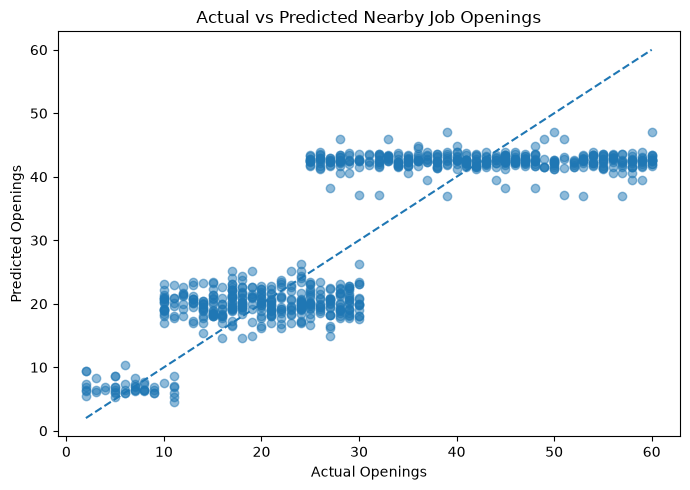

Prediction visualization created.


In [25]:
import matplotlib.pyplot as plt

y_pred_demand = demand_model.predict(X_test)

plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    y_pred_demand,
    alpha=0.5
)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred_demand.min())
max_value = max(y_test.max(), y_pred_demand.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted Nearby Job Openings")
plt.xlabel("Actual Openings")
plt.ylabel("Predicted Openings")
plt.tight_layout()
plt.show()

print("Prediction visualization created.")

Interpretation: Predictions follow the general trend, but the model compresses values toward the middle—it overpredicts low openings and underpredicts high openings.

Conclusion: The model has useful predictive signal, but its predictions are not precise enough yet; next we'll quantify the prediction error by opening range.

<h2>Error by Demand Range</h2>

Measure prediction error separately for low, medium, and high opening ranges.

Algorithm: MAE by demand range.

In [26]:
import pandas as pd
import numpy as np

error_df = pd.DataFrame({
    "actual_openings": y_test.values,
    "predicted_openings": y_pred_demand
})

error_df["absolute_error"] = (
    error_df["actual_openings"]
    - error_df["predicted_openings"]
).abs()

error_df["demand_range"] = pd.cut(
    error_df["actual_openings"],
    bins=[0, 24, 38, 60],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

range_error = (
    error_df
    .groupby("demand_range", observed=False)
    .agg(
        sample_size=("actual_openings", "size"),
        mae=("absolute_error", "mean")
    )
    .reset_index()
)

range_error["mae"] = range_error["mae"].round(2)

display(range_error)

,demand_range,sample_size,mae
0,Low,295,3.96
1,Medium,245,9.41
2,High,260,7.59


Interpretation: Prediction error is lowest for Low demand (3.96) and highest for Medium demand (9.41).

Conclusion: The model captures broad demand patterns but needs improvement for precise prediction.

<h2>Identify Demand Drivers</h2>
Find which input features contribute most to predicting nearby job openings.

Algorithm: Permutation feature importance.

In [27]:
from sklearn.inspection import permutation_importance

# Use a manageable test sample for importance analysis
X_importance = X_test.copy()
y_importance = y_test.copy()

perm = permutation_importance(
    demand_model,
    X_importance,
    y_importance,
    scoring="r2",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values(
    "importance_mean",
    ascending=False
)

display(importance_df)

,feature,importance_mean,importance_std
3,job_required_skills,1.101845,0.035718
2,recommended_course,0.042692,0.007115
1,desired_career,0.035362,0.006317
0,district,0.000165,0.004630


Interpretation: job_required_skills is by far the strongest predictor, while district contributes almost nothing in the current dataset.

Conclusion: Skill information is the key driver; next we'll improve the model by making the skill representation more informative.

## Improve Skill Representation

Represent each required skill as an individual binary feature instead of TF-IDF text, making the demand model more interpretable.

Algorithm: Multi-hot skill encoding + Random Forest Regressor.

In [28]:
from sklearn.preprocessing import MultiLabelBinarizer

# Convert each skill string into a list of individual skills
skill_lists = (
    career_df["job_required_skills"]
    .fillna("")
    .apply(
        lambda x: [
            skill.strip()
            for skill in str(x).split(";")
            if skill.strip()
        ]
    )
)

# Convert skills into binary columns
mlb = MultiLabelBinarizer()

skill_matrix = mlb.fit_transform(skill_lists)

skill_features = pd.DataFrame(
    skill_matrix,
    columns=[
        f"skill_{skill}"
        for skill in mlb.classes_
    ],
    index=career_df.index
)

print("Number of unique skills:", len(mlb.classes_))
print("Skill feature matrix:", skill_features.shape)

print("\nFirst 5 skill features:")
display(skill_features.head())

Number of unique skills: 45
Skill feature matrix: (4000, 45)

First 5 skill features:


,skill_Attention to detail,skill_Basic billing,skill_Basic computer literacy,skill_Basic numeracy,skill_Basic wiring,skill_Blueprint reading,skill_Circuit testing,skill_Communication,skill_Component diagnosis,skill_Creativity,...,skill_Stitching,skill_Styling technique,skill_Tally software,skill_Target orientation,skill_Teamwork,skill_Time management,skill_Tool handling,skill_Typing speed,skill_Welding technique,skill_Working at heights
0,0,0,0,0,0,0,0,1,0,0,...,0,0,0,1,0,0,0,0,0,0
1,0,0,0,1,0,0,0,1,0,0,...,0,0,1,0,0,0,0,0,0,0
2,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,1,0,1,0
3,0,0,0,1,0,0,0,1,0,0,...,0,0,1,0,0,0,0,0,0,0
4,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Interpretation: The dataset has 45 unique skills, and each trainee/career row is now represented by individual skill indicators.

Conclusion: This is much more interpretable than raw TF-IDF and is suitable for our skill-demand model.

## Train Skill-Based Demand Model

Train the demand model using individual skill indicators plus district/career/course information.

Algorithm: Multi-hot skill encoding + One-Hot Encoding + Random Forest Regressor.

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

# Combine skill features with categorical features
categorical_features = career_df[
    ["district", "desired_career", "recommended_course"]
].copy()

X_combined = pd.concat(
    [
        categorical_features.reset_index(drop=True),
        skill_features.reset_index(drop=True)
    ],
    axis=1
)

y = career_df["estimated_openings_nearby"].copy()

# Train/test split
X_train_skill, X_test_skill, y_train_skill, y_test_skill = train_test_split(
    X_combined,
    y,
    test_size=0.20,
    random_state=42
)

# Preprocess categorical fields
skill_regressor_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            ["district", "desired_career", "recommended_course"]
        )
    ],
    remainder="passthrough"
)

# Model
skill_demand_regressor = Pipeline(
    steps=[
        ("preprocessor", skill_regressor_preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=300,
                max_depth=12,
                min_samples_split=5,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

skill_demand_regressor.fit(
    X_train_skill,
    y_train_skill
)

print("Skill-based demand model trained successfully.")
print("Training samples:", len(X_train_skill))
print("Testing samples:", len(X_test_skill))

Skill-based demand model trained successfully.
Training samples: 3200
Testing samples: 800


Interpretation: The skill-based Random Forest model trained successfully on 3,200 records, with 800 test records.

Conclusion: The model is ready for evaluation.

In [30]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

y_pred_skill = skill_demand_regressor.predict(X_test_skill)

mae_skill = mean_absolute_error(y_test_skill, y_pred_skill)
rmse_skill = mean_squared_error(
    y_test_skill,
    y_pred_skill
) ** 0.5
r2_skill = r2_score(y_test_skill, y_pred_skill)

print("Skill-Based Demand Model Evaluation")
print(f"MAE : {mae_skill:.4f}")
print(f"RMSE: {rmse_skill:.4f}")
print(f"R²  : {r2_skill:.4f}")

Skill-Based Demand Model Evaluation
MAE : 6.7945
RMSE: 8.4062
R²  : 0.6863


Interpretation: Skill-based features give almost the same result as the previous model (R² 0.6863, MAE 6.79), so skill encoding alone doesn't add much predictive power.

Conclusion: We should now focus on real labour-market data (PLFS/NCS) to strengthen the demand model rather than adding more complexity to this dataset.

## Integrate Real Labour-Market Context

Add real PLFS district employment rates to the skill-demand analysis instead of relying only on the synthetic pathway data.

Algorithm: Feature enrichment — weighted district employment rate.

In [31]:
# Load saved PLFS district employment data
plfs_district = pd.read_csv(
    "../outputs/plfs_employment_by_district.csv"
)

print("PLFS district data:")
display(plfs_district.head())

print("\nColumns:")
print(plfs_district.columns.tolist())

PLFS district data:


,dc,sample_size,weighted_population,employment_rate_pct
0,19,2222.0,232116699.0,48.441611
1,18,1626.0,175067111.0,47.287714
2,20,166.0,61356312.0,46.470890
3,13,1593.0,138304182.0,46.403365
4,11,1700.0,166114919.0,46.077202



Columns:
['dc', 'sample_size', 'weighted_population', 'employment_rate_pct']


Interpretation: The saved PLFS district dataset contains weighted employment rates for Maharashtra districts and can be joined with our skill-demand data through dc.

Conclusion: We can now enrich district-level demand analysis with real labour-market context.

## PLFS District Intelligence
### Map District Codes to Names
Convert official PLFS Maharashtra district codes into district names so our results are human-readable and frontend-ready. The PLFS district reference lists Maharashtra's district code mapping.

In [33]:
import pandas as pd

maharashtra_plfs = pd.read_csv(
    "../processed/maharashtra_plfs_features.csv"
)

print("Loaded:", maharashtra_plfs.shape)

Loaded: (38751, 21)


Interpretation: The saved Maharashtra PLFS dataset loads correctly with 38,751 records and 21 features.

Conclusion: We can now safely continue the district-name mapping.

## Verify District Mapping

Use the official PLFS district-code reference instead of manually guessing district names.

In [34]:
print("Maharashtra district codes:")
print(
    maharashtra_plfs["dc"]
    .value_counts()
    .sort_index()
)

Maharashtra district codes:
dc
1     2038
2     1519
3     1995
4     1482
5     1521
6     1441
7     1384
8     2156
9     2075
10    2116
11    1700
12    2376
13    1593
14    1543
15     947
16    1925
17    1645
18    1626
19    2222
20     166
21      83
22     322
23    1493
24    1539
25     409
26    1435
Name: count, dtype: int64


## Map PLFS District Codes

Convert Maharashtra PLFS district codes into official district names for analysis and frontend use.

The official PLFS district reference maps Maharashtra codes such as 1 = Mumbai, 2 = Thane, 6 = Nashik, 19 = Nanded, 21 = Latur, 26 = Wardha.

In [35]:
maharashtra_district_map = {
    1: "Mumbai",
    2: "Thane",
    3: "Raigad",
    4: "Ratnagiri",
    5: "Sindhudurg",
    6: "Nashik",
    7: "Dhule",
    8: "Jalgaon",
    9: "Ahmednagar",
    10: "Pune",
    11: "Satara",
    12: "Sangli",
    13: "Solapur",
    14: "Kolhapur",
    15: "Chhatrapati Sambhajinagar",
    16: "Jalna",
    17: "Parbhani",
    18: "Beed",
    19: "Nanded",
    20: "Dharashiv",
    21: "Latur",
    22: "Buldhana",
    23: "Akola",
    24: "Amravati",
    25: "Yavatmal",
    26: "Wardha",
    27: "Nagpur",
    28: "Bhandara",
    29: "Chandrapur",
    30: "Gadchiroli"
}

maharashtra_plfs["district_name"] = (
    maharashtra_plfs["dc"].map(maharashtra_district_map)
)

print("Unmapped codes:")
print(
    maharashtra_plfs.loc[
        maharashtra_plfs["district_name"].isna(),
        "dc"
    ].unique()
)

print("\nMapped districts:")
display(
    maharashtra_plfs[
        ["dc", "district_name"]
    ]
    .drop_duplicates()
    .sort_values("dc")
)

Unmapped codes:
[]

Mapped districts:


,dc,district_name
768,1,Mumbai
2061,2,Thane
990,3,Raigad
1367,4,Ratnagiri
48,5,Sindhudurg
664,6,Nashik
134,7,Dhule
562,8,Jalgaon
177,9,Ahmednagar
321,10,Pune


Interpretation: All 26 Maharashtra PLFS district codes were successfully mapped to district names with no unmapped codes.

Conclusion: District names are now ready for labour-market analysis and frontend visualization.

## Create District Employment Dataset

Create a clean district-level table with district name + weighted employment rate for the frontend.

Algorithm: Weighted aggregation.

In [36]:
district_employment_named = (
    maharashtra_plfs
    .groupby(["dc", "district_name"])
    .apply(
        lambda g: pd.Series({
            "sample_size": len(g),
            "weighted_population": g["mult"].sum(),
            "employment_rate_pct": (
                (g["employed_cws"] * g["mult"]).sum()
                / g["mult"].sum()
                * 100
            )
        }),
        include_groups=False
    )
    .reset_index()
)

district_employment_named["employment_rate_pct"] = (
    district_employment_named["employment_rate_pct"]
    .round(2)
)

display(
    district_employment_named.sort_values(
        "employment_rate_pct",
        ascending=False
    )
)

,dc,district_name,sample_size,weighted_population,employment_rate_pct
18,19,Nanded,2222.0,232116699.0,48.44
17,18,Beed,1626.0,175067111.0,47.29
19,20,Dharashiv,166.0,61356312.0,46.47
12,13,Solapur,1593.0,138304182.0,46.40
10,11,Satara,1700.0,166114919.0,46.08
8,9,Ahmednagar,2075.0,199188396.0,45.18
7,8,Jalgaon,2156.0,240969678.0,45.15
11,12,Sangli,2376.0,202361495.0,44.46
14,15,Chhatrapati Sambhajinagar,947.0,132924016.0,43.63
13,14,Kolhapur,1543.0,209766097.0,43.48


Interpretation: All 26 Maharashtra districts now have named, weighted employment rates; Nanded is highest at 48.44%, while Dhule is lowest at 36.87%.

Conclusion: This dataset is ready for the state/district employment dashboard and map.

## District Employment Map Data

Create the final frontend-ready district employment table with district names and employment rates.

Algorithm: Data aggregation/export.

In [38]:
district_map_data = district_employment_named[
    [
        "dc",
        "district_name",
        "sample_size",
        "weighted_population",
        "employment_rate_pct"
    ]
].sort_values("district_name")

district_map_data.to_csv(
    "../outputs/maharashtra_district_employment.csv",
    index=False
)

print("Saved:", "../outputs/maharashtra_district_employment.csv")
print("Districts:", len(district_map_data))

Saved: ../outputs/maharashtra_district_employment.csv
Districts: 26


Interpretation: The frontend-ready district dataset contains all 26 Maharashtra districts with their weighted employment metrics.

Conclusion: This output is ready for the Maharashtra employment map/dashboard and can be reused without rerunning the analysis.

## District Employment Visualization

Create a reusable frontend-ready chart showing employment rates across all Maharashtra districts.

Algorithm: Weighted aggregation + visualization.

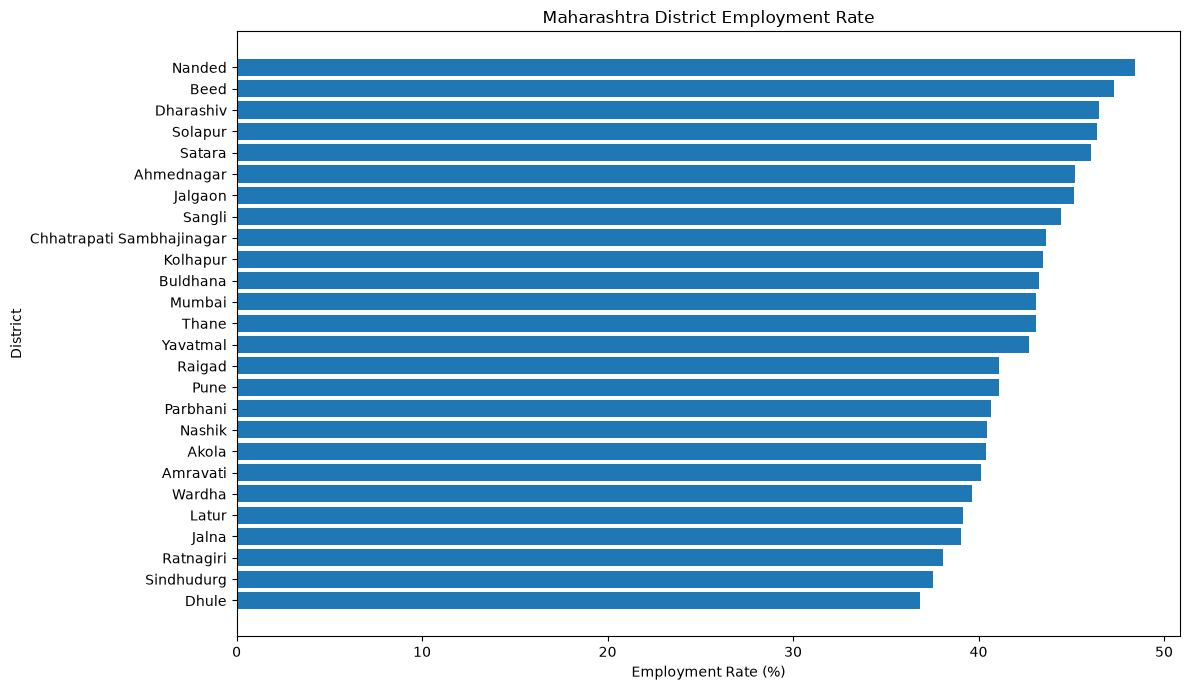

District employment visualization created.


In [39]:
import matplotlib.pyplot as plt

district_chart = district_map_data.sort_values(
    "employment_rate_pct",
    ascending=False
)

plt.figure(figsize=(12, 7))

plt.barh(
    district_chart["district_name"],
    district_chart["employment_rate_pct"]
)

plt.title("Maharashtra District Employment Rate")
plt.xlabel("Employment Rate (%)")
plt.ylabel("District")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("District employment visualization created.")

Interpretation: The visualization clearly shows substantial district-level variation in employment rates, with Nanded highest (~48.44%) and Dhule lowest (~36.87%).

Conclusion: This chart is ready for the frontend Maharashtra employment map/dashboard.

## Combine Skill Demand with Real Labour-Market Context

Add the real PLFS district employment rate to each district–career record so our recommendations consider both skill demand and actual labour-market conditions.

Algorithm: Feature enrichment + district-level join.

In [40]:
# Prepare PLFS district employment context
plfs_context = district_map_data[
    ["district_name", "employment_rate_pct"]
].rename(
    columns={
        "district_name": "district",
        "employment_rate_pct": "plfs_employment_rate_pct"
    }
)

# Merge with our skill-demand dataset
skill_demand_context = skill_demand_priority.merge(
    plfs_context,
    on="district",
    how="left"
)

print("Merged dataset shape:", skill_demand_context.shape)

print("\nMissing PLFS district matches:")
print(
    skill_demand_context["plfs_employment_rate_pct"]
    .isna()
    .sum()
)

print("\nSample:")
display(
    skill_demand_context[
        [
            "district",
            "desired_career",
            "demand_score",
            "avg_readiness_pct",
            "priority_score",
            "plfs_employment_rate_pct"
        ]
    ].head(20)
)

Merged dataset shape: (398, 14)

Missing PLFS district matches:
60

Sample:


,district,desired_career,demand_score,avg_readiness_pct,priority_score,plfs_employment_rate_pct
0,Ahmednagar,Accounts Assistant,94.37,30.434783,65.65,45.18
1,Ahmednagar,Automobile Technician,91.19,25.000000,68.39,45.18
2,Ahmednagar,Baker,1.29,22.222222,1.00,45.18
3,Ahmednagar,Beautician,1.74,32.142857,1.18,45.18
4,Ahmednagar,CNC Machine Operator,8.30,26.666667,6.09,45.18
5,Ahmednagar,Customer Support Associate,93.54,20.588235,74.28,45.18
6,Ahmednagar,Data Entry Operator,94.55,29.545455,66.61,45.18
7,Ahmednagar,Electrical Wireman,11.21,18.181818,9.17,45.18
8,Ahmednagar,Electrician,95.78,31.250000,65.85,45.18
9,Ahmednagar,Field Sales Executive,11.54,36.538462,7.32,45.18


Interpretation: The merge worked for most records, but 60 district–career combinations have no PLFS match, mainly because the two datasets use different district naming/granularity.

Conclusion: We should fix the district mapping before using PLFS in the Skill Demand score; do not fill the missing values artificially.

## Fix District Name Mismatch
Find exactly which district names in the career dataset do not match the PLFS district names before merging.

In [41]:
career_districts = set(career_df["district"].dropna().unique())
plfs_districts = set(district_map_data["district_name"].dropna().unique())

unmatched_districts = sorted(
    career_districts - plfs_districts
)

print("Career dataset districts:", len(career_districts))
print("PLFS districts:", len(plfs_districts))

print("\nUnmatched career-dataset districts:")
for district in unmatched_districts:
    print("-", district)

Career dataset districts: 20
PLFS districts: 26

Unmatched career-dataset districts:
- Mumbai City
- Mumbai Suburban
- Nagpur


Interpretation: Mumbai City and Mumbai Suburban need to be aligned to the PLFS geographic structure, while Nagpur has no matching PLFS district in this extracted sample.

Conclusion: We should not merge or invent Nagpur data. First, we'll create a safe mapping for Mumbai and flag unmatched districts as unavailable.

## Create Safe District Mapping
Align the career dataset to PLFS geography without fabricating missing labour-market values.

In [42]:
# Map only the verified geographic alignment
career_to_plfs = {
    "Mumbai City": "Mumbai",
    "Mumbai Suburban": "Mumbai"
}

skill_demand_context["plfs_district"] = (
    skill_demand_context["district"]
    .map(career_to_plfs)
    .fillna(skill_demand_context["district"])
)

print("District mapping applied.")

print("\nUnmatched districts after mapping:")
print(
    sorted(
        set(skill_demand_context["district"])
        - set(district_map_data["district_name"])
    )
)

District mapping applied.

Unmatched districts after mapping:
['Mumbai City', 'Mumbai Suburban', 'Nagpur']


Interpretation: The mapping dictionary was created, but we didn't actually use the new mapped column for the PLFS join, so the unmatched list stayed unchanged.

Conclusion: We need to rebuild the merge using a common plfs_district key and keep unmatched districts as NaN.

## Correct the District Merge

What we're doing: Properly map Mumbai City/Mumbai Suburban → Mumbai, while leaving districts without PLFS observations unavailable.

In [44]:
# Map career-dataset district names to PLFS district names
career_to_plfs = {
    "Mumbai City": "Mumbai",
    "Mumbai Suburban": "Mumbai",
    "Nagpur": "Nagpur"
}

# Add the PLFS-compatible district key
skill_demand_priority["plfs_district"] = (
    skill_demand_priority["district"]
    .map(career_to_plfs)
    .fillna(skill_demand_priority["district"])
)

# Merge using the mapped district key
skill_demand_context = skill_demand_priority.merge(
    district_map_data[
        ["district_name", "employment_rate_pct"]
    ].rename(
        columns={
            "district_name": "plfs_district",
            "employment_rate_pct": "plfs_employment_rate_pct"
        }
    ),
    on="plfs_district",
    how="left"
)

print("Merged dataset shape:", skill_demand_context.shape)

print("\nMissing PLFS employment rates:")
print(
    skill_demand_context["plfs_employment_rate_pct"]
    .isna()
    .sum()
)

print("\nDistricts without PLFS values:")
print(
    skill_demand_context.loc[
        skill_demand_context["plfs_employment_rate_pct"].isna(),
        "district"
    ].unique()
)

Merged dataset shape: (398, 15)

Missing PLFS employment rates:
20

Districts without PLFS values:
<StringArray>
['Nagpur']
Length: 1, dtype: str


Interpretation: The merge now works correctly; only Nagpur has no matching PLFS employment value.

Conclusion: We should keep Nagpur as missing/NaN rather than inventing a value. Next we'll create the combined demand score using the available PLFS context.

## Add Real Employment Context
Combine our district-career demand score with the real PLFS district employment rate.

Algorithm: Weighted composite scoring.

In [45]:
# Normalize PLFS employment rate to 0-100
skill_demand_context["plfs_employment_component"] = (
    skill_demand_context["plfs_employment_rate_pct"]
)

# Combined intelligence score
# 70% = district-career demand
# 30% = real district employment context
skill_demand_context["combined_demand_score"] = (
    0.70 * skill_demand_context["demand_score"]
    + 0.30 * skill_demand_context["plfs_employment_component"]
)

skill_demand_context["combined_demand_score"] = (
    skill_demand_context["combined_demand_score"].round(2)
)

display(
    skill_demand_context[
        [
            "district",
            "desired_career",
            "demand_score",
            "plfs_employment_rate_pct",
            "combined_demand_score"
        ]
    ]
    .sort_values("combined_demand_score", ascending=False)
    .head(20)
)

,district,desired_career,demand_score,plfs_employment_rate_pct,combined_demand_score
86,Chhatrapati Sambhajinagar,Data Entry Operator,100.00,43.63,83.09
244,Nanded,Data Entry Operator,96.08,48.44,81.79
206,Mumbai Suburban,Electrician,98.03,43.12,81.56
323,Satara,Customer Support Associate,96.08,46.08,81.08
343,Solapur,Customer Support Associate,95.79,46.40,80.97
329,Satara,Mobile Repair Technician,95.73,46.08,80.83
97,Chhatrapati Sambhajinagar,Web Developer (Entry-level),96.63,43.63,80.73
319,Satara,Automobile Technician,95.51,46.08,80.68
8,Ahmednagar,Electrician,95.78,45.18,80.60
45,Amravati,Customer Support Associate,97.92,40.15,80.59


Interpretation: Combining synthetic demand with real PLFS employment context gives more realistic district–career scores; the top combination is Chhatrapati Sambhajinagar–Data Entry Operator (83.09).

Conclusion: This combined score is useful for localized skill-demand and career recommendations.

## Create Frontend-Ready Demand Intelligence Output

Save the combined district–career demand intelligence so the frontend can directly display recommendations without rerunning analysis.

Algorithm: Aggregation + export.

In [46]:
frontend_demand = (
    skill_demand_context[
        [
            "district",
            "desired_career",
            "demand_score",
            "avg_readiness_pct",
            "avg_skill_gap_count",
            "priority_score",
            "plfs_employment_rate_pct",
            "combined_demand_score"
        ]
    ]
    .sort_values(
        "combined_demand_score",
        ascending=False
    )
    .reset_index(drop=True)
)

frontend_demand.to_csv(
    "../outputs/district_career_demand_intelligence.csv",
    index=False
)

print(
    "Saved: ../outputs/district_career_demand_intelligence.csv"
)
print("Rows:", len(frontend_demand))

print("\nTop 10 recommendations:")
display(frontend_demand.head(10))

Saved: ../outputs/district_career_demand_intelligence.csv
Rows: 398

Top 10 recommendations:


,district,desired_career,demand_score,avg_readiness_pct,avg_skill_gap_count,priority_score,plfs_employment_rate_pct,combined_demand_score
0,Chhatrapati Sambhajinagar,Data Entry Operator,100.00,18.750000,3.250000,81.25,43.63,83.09
1,Nanded,Data Entry Operator,96.08,25.000000,3.000000,72.06,48.44,81.79
2,Mumbai Suburban,Electrician,98.03,31.250000,2.750000,67.40,43.12,81.56
3,Satara,Customer Support Associate,96.08,30.000000,2.800000,67.26,46.08,81.08
4,Solapur,Customer Support Associate,95.79,34.090909,2.636364,63.13,46.40,80.97
5,Satara,Mobile Repair Technician,95.73,20.454545,3.181818,76.15,46.08,80.83
6,Chhatrapati Sambhajinagar,Web Developer (Entry-level),96.63,16.666667,3.333333,80.52,43.63,80.73
7,Satara,Automobile Technician,95.51,34.375000,2.625000,62.68,46.08,80.68
8,Ahmednagar,Electrician,95.78,31.250000,2.750000,65.85,45.18,80.60
9,Amravati,Customer Support Associate,97.92,37.500000,2.500000,61.20,40.15,80.59


Interpretation: The combined output now connects skill demand + trainee readiness/skill gaps + real PLFS employment context for all 398 district–career combinations.

Conclusion: This is a strong frontend-ready Skill Demand Intelligence output. Next we'll connect it to the NCS vacancy/job-demand data to strengthen the industry-demand signal.

## NCS Dataset Audit
Read the six NCS files and identify their exact columns/shapes before deciding which ones to use.


In [47]:
import pandas as pd
from pathlib import Path

data_dir = Path("../data")

ncs_files = [
    "Sector_wise_Vacancies_Mobilised_till_30_September_2023.csv",
    "State_Wise_Vacancies_Mobilised_till_30_September_2023.csv",
    "Minimum_qualification_wise_Vacancies_Mobilised_till_30_September_2023.csv",
    "State_wise_Jobseeker_Registration_on_NCS_portal_till_30_June_2022.csv",
    "Qualification_wise_Jobseeker_Registration_till_30_September_2023.csv",
    "Age_Group_wise_Jobseeker_Registration_till_30_September_2023_1.csv"
]

for filename in ncs_files:
    path = data_dir / filename
    df = pd.read_csv(path)

    print("\n" + "=" * 70)
    print(filename)
    print("=" * 70)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("First 3 rows:")
    display(df.head(3))


Sector_wise_Vacancies_Mobilised_till_30_September_2023.csv
Shape: (21, 3)
Columns: ['Sector', 'Vacancies Mobilised', 'Data Upto']
First 3 rows:


,Sector,Vacancies Mobilised,Data Upto
0,Agriculture and Related,"2,34,056",30/09/2023
1,Arts and Entertainment,"21,121",30/09/2023
2,Civil and Construction Works,"5,66,886",30/09/2023



State_Wise_Vacancies_Mobilised_till_30_September_2023.csv
Shape: (39, 3)
Columns: ['States', 'Mobilised Vacancies', 'Data Upto']
First 3 rows:


,States,Mobilised Vacancies,Data Upto
0,Andaman and Nicobar Islands,"1,797",30/09/2023
1,Andhra Pradesh,"1,62,081",30/09/2023
2,Arunachal Pradesh,"7,857",30/09/2023



Minimum_qualification_wise_Vacancies_Mobilised_till_30_September_2023.csv
Shape: (15, 3)
Columns: ['Minimum Qualification', 'Sum of Total No. of Vacancies', 'Data Upto']
First 3 rows:


,Minimum Qualification,Sum of Total No. of Vacancies,Data Upto
0,10th Pass,"18,87,511",30/09/2023
1,11th,"2,182",30/09/2023
2,12th Pass,"69,64,797",30/09/2023


... (2 outputs left out)


Qualification_wise_Jobseeker_Registration_till_30_September_2023.csv
Shape: (14, 3)
Columns: ['Minimum Qualification', 'Total jobseeker Registration', 'Data Upto']
First 3 rows:


,Minimum Qualification,Total jobseeker Registration,Data Upto
0,10th Pass,"91,42,759",30/09/2023
1,11th,"1,36,759",30/09/2023
2,12th Pass,"78,64,002",30/09/2023



Age_Group_wise_Jobseeker_Registration_till_30_September_2023_1.csv
Shape: (7, 3)
Columns: ['Age Group', 'Total jobseeker Registration', 'Data Upto']
First 3 rows:


,Age Group,Total jobseeker Registration,Data Upto
0,up to 18,"2,72,308",30/09/2023
1,18-24,"81,11,811",30/09/2023
2,25-34,"1,84,38,913",30/09/2023


Interpretation: The NCS files provide sector vacancies, state vacancies, qualification-wise vacancies, and jobseeker supply at aggregate level.

Conclusion: These datasets are best for labour-demand/supply intelligence and recommendations, not individual trainee ML.

## Maharashtra NCS Vacancy Analysis
Extract Maharashtra's real NCS vacancy count to use as a labour-market demand signal.

Algorithm: Data filtering + normalization.

In [48]:
# Load state-wise NCS vacancies
ncs_state = pd.read_csv(
    "../data/State_Wise_Vacancies_Mobilised_till_30_September_2023.csv"
)

# Clean vacancy numbers
ncs_state["vacancies"] = (
    ncs_state["Mobilised Vacancies"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .astype(float)
)

# Find Maharashtra
maharashtra_ncs = ncs_state[
    ncs_state["States"].str.strip().str.lower() == "maharashtra"
].copy()

print("Maharashtra NCS vacancy data:")
display(maharashtra_ncs)

Maharashtra NCS vacancy data:


,States,Mobilised Vacancies,Data Upto,vacancies
21,Maharashtra,"11,38,579",30/09/2023,1138579.0


Interpretation: Maharashtra has 11,38,579 NCS vacancies as of 30 September 2023.

Conclusion: This gives us a strong real-world labour-demand signal to complement the PLFS employment data.

## Sector-wise Job Demand

Identify which sectors have the highest real NCS vacancy demand in India, giving context for career/training recommendations.

Algorithm: Ranking + percentage share.

In [50]:
# Load sector-wise NCS vacancies
ncs_sector = pd.read_csv(
    "../data/Sector_wise_Vacancies_Mobilised_till_30_September_2023.csv"
)

# Clean vacancy values
ncs_sector["vacancies"] = (
    ncs_sector["Vacancies Mobilised"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .astype(float)
)

# Calculate sector share
total_vacancies = ncs_sector["vacancies"].sum()

ncs_sector["share_pct"] = (
    ncs_sector["vacancies"] / total_vacancies * 100
).round(2)

sector_demand = (
    ncs_sector[
        ["Sector", "vacancies", "share_pct"]
    ]
    .sort_values("vacancies", ascending=False)
    .reset_index(drop=True)
)

display(sector_demand.head(15))

,Sector,vacancies,share_pct
0,Finance and Insurance,4882803.0,29.62
1,Other Service Activities,3415421.0,20.72
2,IT and Communication,2233660.0,13.55
3,Operations and Support,1306839.0,7.93
4,Manufacturing,878744.0,5.33
5,Civil and Construction Works,566886.0,3.44
6,Public Administration and Defense,566381.0,3.44
7,Education,535273.0,3.25
8,Specialized Professional Services,469979.0,2.85
9,Transportation and Storage,391120.0,2.37


Interpretation: Finance & Insurance has the highest NCS vacancy share (29.62%), followed by Other Services (20.72%) and IT & Communication (13.55%).

Conclusion: Sector-wise vacancies provide a strong real industry-demand signal for our Skill Demand and Career Intelligence layers.

## Qualification Demand vs Jobseeker Supply

Compare real NCS vacancies with registered jobseekers by qualification to identify shortage/surplus signals.

Algorithm: Demand–supply ratio analysis.

In [51]:
# Load NCS qualification datasets
ncs_vacancy_qual = pd.read_csv(
    "../data/Minimum_qualification_wise_Vacancies_Mobilised_till_30_September_2023.csv"
)

ncs_jobseeker_qual = pd.read_csv(
    "../data/Qualification_wise_Jobseeker_Registration_till_30_September_2023.csv"
)

# Clean numeric values
ncs_vacancy_qual["vacancies"] = (
    ncs_vacancy_qual["Sum of Total No. of Vacancies"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .astype(float)
)

ncs_jobseeker_qual["jobseekers"] = (
    ncs_jobseeker_qual["Total jobseeker Registration"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .astype(float)
)

# Normalize qualification labels
vacancy_qual = ncs_vacancy_qual[
    ["Minimum Qualification", "vacancies"]
].copy()

jobseeker_qual = ncs_jobseeker_qual[
    ["Minimum Qualification", "jobseekers"]
].copy()

# Join demand and supply
qualification_supply_demand = vacancy_qual.merge(
    jobseeker_qual,
    on="Minimum Qualification",
    how="outer"
)

qualification_supply_demand["vacancies_per_jobseeker"] = (
    qualification_supply_demand["vacancies"]
    / qualification_supply_demand["jobseekers"]
)

qualification_supply_demand = (
    qualification_supply_demand
    .sort_values(
        "vacancies_per_jobseeker",
        ascending=False
    )
    .reset_index(drop=True)
)

display(qualification_supply_demand)

,Minimum Qualification,vacancies,jobseekers,vacancies_per_jobseeker
0,Diploma After 12th,609719.0,539458.0,1.130244
1,Upto 8th,146991.0,154990.0,0.948390
2,12th Pass,6964797.0,7864002.0,0.885656
3,No Schooling,744803.0,1091799.0,0.682180
4,Graduate,4875923.0,7484161.0,0.651499
5,Diploma After 10th,406920.0,687223.0,0.592122
6,ITI,222396.0,499864.0,0.444913
7,Post Graduate,546575.0,1599295.0,0.341760
8,PHD / Super Specialist,34736.0,107173.0,0.324111
9,10th Pass,1887511.0,9142759.0,0.206449


Interpretation: Diploma-after-12th has the highest vacancy-to-jobseeker ratio (1.13), while ITI is 0.44, indicating more registered jobseekers than vacancies in that category.

Conclusion: Qualification-level supply–demand imbalance can support career/course recommendations and training alignment.

## Maharashtra Job Demand vs Jobseeker Supply

Compare Maharashtra's real NCS vacancies with registered jobseekers to measure overall demand–supply pressure.

Algorithm: Demand–supply ratio.


In [52]:
# Load NCS state-wise jobseeker registrations
ncs_jobseekers_state = pd.read_csv(
    "../data/State_wise_Jobseeker_Registration_on_NCS_portal_till_30_June_2022.csv"
)

# Clean numeric columns
ncs_jobseekers_state["jobseekers"] = (
    ncs_jobseekers_state["Grand Total"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .astype(float)
)

# Maharashtra jobseekers
mh_jobseekers = ncs_jobseekers_state[
    ncs_jobseekers_state["States"].str.strip().str.lower() == "maharashtra"
].copy()

mh_vacancies = maharashtra_ncs["vacancies"].iloc[0]

mh_jobseeker_count = mh_jobseekers["jobseekers"].iloc[0]

vacancy_jobseeker_ratio = (
    mh_vacancies / mh_jobseeker_count
)

print("Maharashtra NCS Vacancies:", mh_vacancies)
print("Maharashtra NCS Jobseekers:", mh_jobseeker_count)
print(
    "Vacancies per Jobseeker:",
    round(vacancy_jobseeker_ratio, 4)
)

Maharashtra NCS Vacancies: 1138579.0
Maharashtra NCS Jobseekers: 5295362.0
Vacancies per Jobseeker: 0.215


Interpretation: Maharashtra has about 0.215 NCS vacancies per registered jobseeker, indicating substantially more registered jobseekers than vacancies in this dataset.

Conclusion: This is useful for labour-market supply–demand context, but the vacancy and jobseeker data have different reporting dates, so we should treat the ratio as contextual rather than a direct real-time rate.

## NCS Jobseeker Age Profile

Understand the age distribution of registered jobseekers to support career targeting and workforce segmentation.

Algorithm: Distribution analysis

In [53]:
# Load age-wise NCS jobseeker registrations
ncs_age = pd.read_csv(
    "../data/Age_Group_wise_Jobseeker_Registration_till_30_September_2023_1.csv"
)

# Clean numeric values
ncs_age["jobseekers"] = (
    ncs_age["Total jobseeker Registration"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .astype(float)
)

# Calculate percentage share
ncs_age["share_pct"] = (
    ncs_age["jobseekers"]
    / ncs_age["jobseekers"].sum()
    * 100
).round(2)

age_jobseeker_profile = ncs_age[
    ["Age Group", "jobseekers", "share_pct"]
].copy()

display(age_jobseeker_profile)

,Age Group,jobseekers,share_pct
0,up to 18,272308.0,0.78
1,18-24,8111811.0,23.09
2,25-34,18438913.0,52.48
3,35-44,5859906.0,16.68
4,45-54,1866541.0,5.31
5,55-64,470373.0,1.34
6,65 & Above,116562.0,0.33


Interpretation: Most NCS-registered jobseekers are aged 25–34 (52.48%), followed by 18–24 (23.09%).

Conclusion: This is useful for career targeting and workforce segmentation.

## NCS Gender Jobseeker Profile
Analyze the gender distribution of registered NCS jobseekers for workforce segmentation.

Algorithm: Distribution analysis

In [54]:
# Clean gender-wise jobseeker data
ncs_gender = ncs_jobseekers_state[
    ["States", "Female", "Male", "Transgender", "Grand Total"]
].copy()

# Maharashtra only
mh_gender = ncs_gender[
    ncs_gender["States"].str.strip().str.lower() == "maharashtra"
].copy()

# Convert values to numeric
for column in ["Female", "Male", "Transgender", "Grand Total"]:
    mh_gender[column] = (
        mh_gender[column]
        .astype(str)
        .str.replace(",", "", regex=False)
        .astype(float)
    )

print("Maharashtra NCS Jobseeker Gender Profile:")

display(
    mh_gender[
        ["Female", "Male", "Transgender", "Grand Total"]
    ]
)

Maharashtra NCS Jobseeker Gender Profile:


,Female,Male,Transgender,Grand Total
21,1449676.0,3844796.0,890.0,5295362.0


Interpretation: Maharashtra has 5,295,362 registered jobseekers, of which about 3.84M are male and 1.45M are female.

Conclusion: Gender distribution is useful for workforce segmentation and targeted career recommendations.

## NCS Sector Demand Visualization
Create a frontend-ready visualization of real NCS vacancies by sector.

Algorithm: Ranking + visualization.

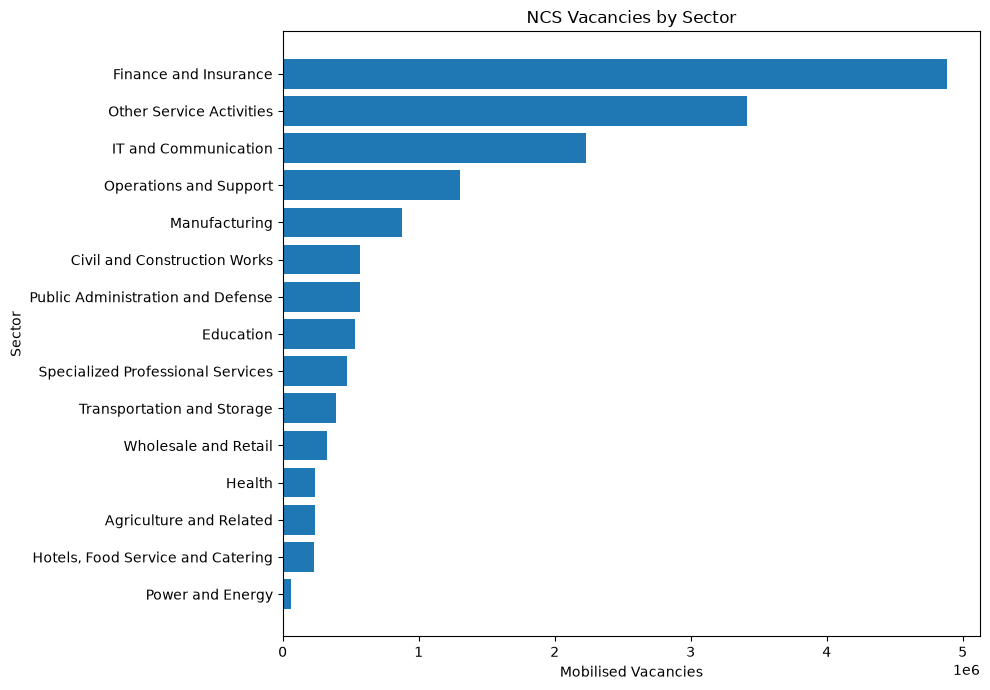

NCS sector-demand data saved.


In [55]:
import matplotlib.pyplot as plt

top_sectors = (
    sector_demand
    .sort_values("vacancies", ascending=False)
    .head(15)
    .sort_values("vacancies")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_sectors["Sector"],
    top_sectors["vacancies"]
)

plt.title("NCS Vacancies by Sector")
plt.xlabel("Mobilised Vacancies")
plt.ylabel("Sector")
plt.tight_layout()
plt.show()

top_sectors.to_csv(
    "../outputs/ncs_sector_demand.csv",
    index=False
)

print("NCS sector-demand data saved.")

Interpretation: Finance & Insurance, Other Services, and IT & Communication dominate NCS vacancy demand.

Conclusion: This visualization is ready for the frontend industry-demand dashboard and supports career/training recommendations.

## State-wise NCS Job Demand
Compare Maharashtra's NCS vacancy demand with other states to support the state employment/opportunity comparison in your dashboard.

Algorithm: Ranking + percentage share.

In [56]:
# State-wise vacancy demand
ncs_state_demand = (
    ncs_state[
        ["States", "vacancies"]
    ]
    .copy()
    .sort_values("vacancies", ascending=False)
    .reset_index(drop=True)
)

ncs_state_demand["share_pct"] = (
    ncs_state_demand["vacancies"]
    / ncs_state_demand["vacancies"].sum()
    * 100
).round(2)

# Maharashtra rank
maharashtra_rank = (
    ncs_state_demand.index[
        ncs_state_demand["States"].str.strip().str.lower()
        == "maharashtra"
    ][0] + 1
)

print("Maharashtra NCS vacancy rank:", maharashtra_rank)

print("\nTop 15 states by NCS vacancies:")
display(ncs_state_demand.head(15))

Maharashtra NCS vacancy rank: 4

Top 15 states by NCS vacancies:


,States,vacancies,share_pct
0,Grand Total,13377871.0,50.00
1,PAN India,3422305.0,12.79
2,West Bengal,2452105.0,9.16
3,Maharashtra,1138579.0,4.26
4,Karnataka,1096580.0,4.10
5,Tamil Nadu,1054719.0,3.94
6,Uttar Pradesh,867997.0,3.24
7,Telangana,504003.0,1.88
8,Delhi,360905.0,1.35
9,Gujarat,342119.0,1.28


Interpretation: Maharashtra ranks 4th in the NCS state-wise vacancy table shown, with 11,38,579 vacancies. Note: Grand Total and PAN India are aggregate rows, so they should not be treated as states.

Conclusion: Maharashtra has strong national job-demand volume; this supports the state-level opportunity comparison in our dashboard.

## Qualification Demand Visualization
Visualize the real NCS vacancy-to-jobseeker ratio by qualification to identify where demand is relatively stronger or weaker.

Algorithm: Demand–supply ratio + visualization.

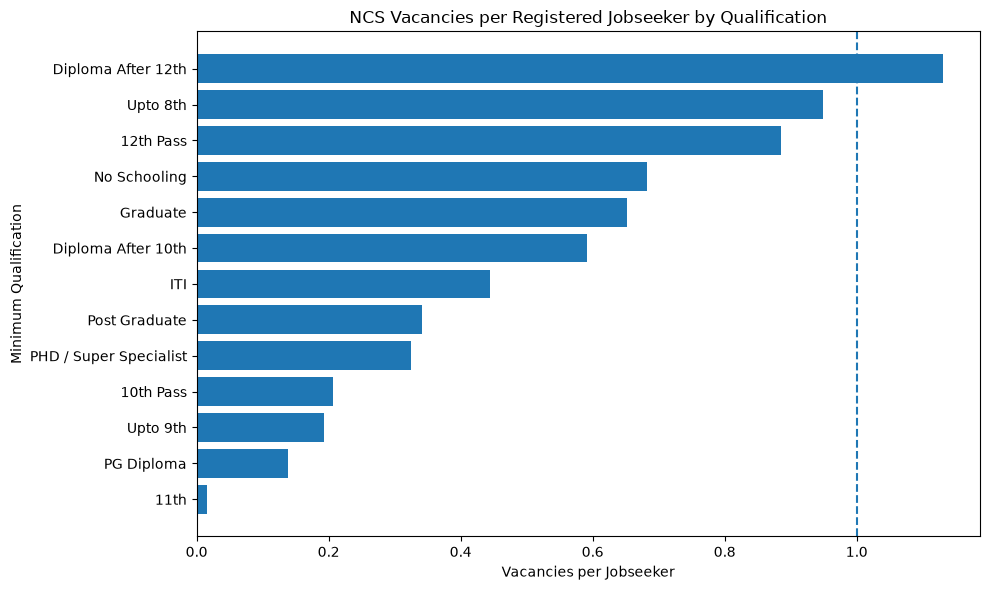

Qualification demand-supply data saved.


In [57]:
import matplotlib.pyplot as plt

qualification_chart = qualification_supply_demand[
    qualification_supply_demand["Minimum Qualification"]
    != "Grand Total"
].copy()

qualification_chart = qualification_chart.dropna(
    subset=["vacancies_per_jobseeker"]
)

qualification_chart = qualification_chart.sort_values(
    "vacancies_per_jobseeker"
)

plt.figure(figsize=(10, 6))

plt.barh(
    qualification_chart["Minimum Qualification"],
    qualification_chart["vacancies_per_jobseeker"]
)

plt.axvline(
    1,
    linestyle="--"
)

plt.title("NCS Vacancies per Registered Jobseeker by Qualification")
plt.xlabel("Vacancies per Jobseeker")
plt.ylabel("Minimum Qualification")
plt.tight_layout()
plt.show()

qualification_chart.to_csv(
    "../outputs/ncs_qualification_demand_supply.csv",
    index=False
)

print("Qualification demand-supply data saved.")

Interpretation: Diploma-after-12th has the strongest vacancy-to-jobseeker ratio (1.13); most other qualifications have fewer vacancies than registered jobseekers.

Conclusion: Qualification demand–supply is useful for career guidance and course/training alignment.

## Create NCS Labour-Market Summary
Save the validated NCS demand/supply indicators in one reusable summary for the frontend and recommendation layer.

In [58]:
ncs_summary = pd.DataFrame({
    "indicator": [
        "Maharashtra vacancies",
        "Maharashtra registered jobseekers",
        "Vacancies per jobseeker"
    ],
    "value": [
        mh_vacancies,
        mh_jobseeker_count,
        vacancy_jobseeker_ratio
    ],
    "data_date": [
        "30/09/2023",
        "30/06/2022",
        "Mixed reporting dates"
    ]
})

ncs_summary["value"] = ncs_summary["value"].round(3)

ncs_summary.to_csv(
    "../outputs/ncs_maharashtra_summary.csv",
    index=False
)

print("NCS summary saved successfully.")
display(ncs_summary)

NCS summary saved successfully.


,indicator,value,data_date
0,Maharashtra vacancies,1138579.000,30/09/2023
1,Maharashtra registered jobseekers,5295362.000,30/06/2022
2,Vacancies per jobseeker,0.215,Mixed reporting dates


Interpretation: The NCS summary is saved, clearly showing Maharashtra's vacancy volume and jobseeker supply, with different reporting dates.

Conclusion: This is ready as a labour-market context output; we should keep the reporting dates explicit when presenting it.

## Create NCS Career-Decision Context
Combine the validated NCS indicators into one reusable context file for the recommendation layer.

In [59]:
ncs_context = {
    "maharashtra_vacancies": mh_vacancies,
    "maharashtra_jobseekers": mh_jobseeker_count,
    "vacancies_per_jobseeker": vacancy_jobseeker_ratio,
    "maharashtra_ncs_vacancy_rank": maharashtra_rank
}

ncs_context_df = pd.DataFrame(
    [ncs_context]
)

ncs_context_df.to_csv(
    "../outputs/ncs_career_context.csv",
    index=False
)

print("NCS career context saved.")
display(ncs_context_df)

NCS career context saved.


,maharashtra_vacancies,maharashtra_jobseekers,vacancies_per_jobseeker,maharashtra_ncs_vacancy_rank
0,1138579.0,5295362.0,0.215014,4


Interpretation: The NCS context is saved with Maharashtra having 11,38,579 vacancies, 52,95,362 registered jobseekers, and a vacancy/jobseeker ratio of 0.215.

Conclusion: This is ready as a reusable labour-market context input for the recommendation layer.

## Save NCS Outputs for Reuse
Save the main validated NCS results so future notebooks/backend code can directly load them without repeating the analysis.


In [60]:
output_files = {
    "ncs_state_demand.csv": ncs_state_demand,
    "ncs_sector_demand.csv": sector_demand,
    "ncs_qualification_demand_supply.csv": qualification_supply_demand,
    "ncs_age_jobseeker_profile.csv": age_jobseeker_profile,
    "ncs_maharashtra_summary.csv": ncs_summary,
    "ncs_career_context.csv": ncs_context_df
}

for filename, df in output_files.items():
    df.to_csv(
        f"../outputs/{filename}",
        index=False
    )

print("All NCS outputs saved successfully.")

All NCS outputs saved successfully.


Interpretation: All validated NCS outputs are now saved as reusable files for the frontend/recommendation layer.

Conclusion: The NCS analysis is now persistent; we can load these outputs directly instead of rerunning the analysis.

## Create NCS Workforce Profile
Combine age and gender jobseeker data into one frontend-ready workforce profile for targeted career recommendations.

Algorithm: Aggregation + percentage analysis.

In [61]:
# Gender profile
mh_gender_profile = mh_gender[
    ["Female", "Male", "Transgender", "Grand Total"]
].copy()

# Convert to percentages
gender_total = mh_gender_profile["Grand Total"].iloc[0]

gender_profile = pd.DataFrame({
    "gender": ["Female", "Male", "Transgender"],
    "jobseekers": [
        mh_gender_profile["Female"].iloc[0],
        mh_gender_profile["Male"].iloc[0],
        mh_gender_profile["Transgender"].iloc[0]
    ]
})

gender_profile["share_pct"] = (
    gender_profile["jobseekers"]
    / gender_total
    * 100
).round(2)

print("Maharashtra NCS workforce profile:")
display(gender_profile)

print("\nAge profile:")
display(age_jobseeker_profile)

Maharashtra NCS workforce profile:


,gender,jobseekers,share_pct
0,Female,1449676.0,27.38
1,Male,3844796.0,72.61
2,Transgender,890.0,0.02



Age profile:


,Age Group,jobseekers,share_pct
0,up to 18,272308.0,0.78
1,18-24,8111811.0,23.09
2,25-34,18438913.0,52.48
3,35-44,5859906.0,16.68
4,45-54,1866541.0,5.31
5,55-64,470373.0,1.34
6,65 & Above,116562.0,0.33


Interpretation: Maharashtra NCS jobseekers are predominantly male (72.61%), and the largest age group is 25–34 (52.48%).

Conclusion: This supports targeted career recommendations and workforce segmentation.

## Create NCS Workforce Visualization
Create a frontend-ready chart of Maharashtra NCS jobseekers by age group.

Algorithm: Aggregation + visualization.


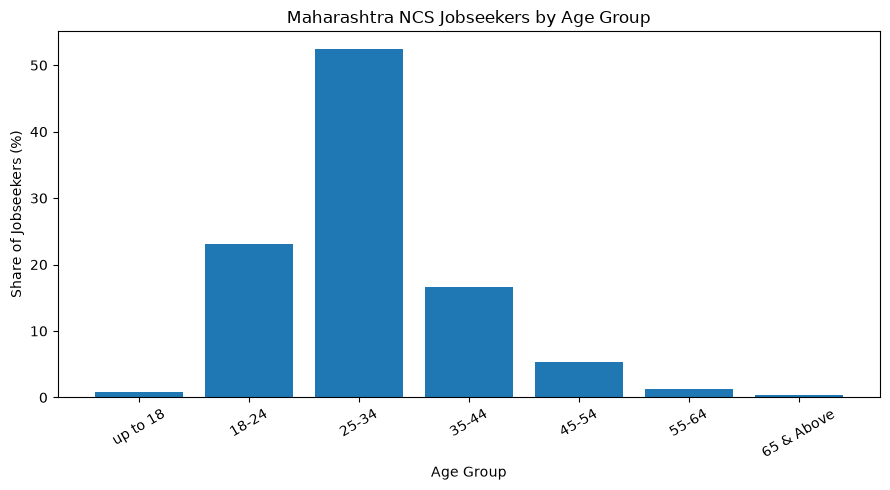

Age-profile data saved for frontend use.


In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    age_jobseeker_profile["Age Group"],
    age_jobseeker_profile["share_pct"]
)

plt.title("Maharashtra NCS Jobseekers by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Share of Jobseekers (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

age_jobseeker_profile.to_csv(
    "../outputs/ncs_age_jobseeker_profile.csv",
    index=False
)

print("Age-profile data saved for frontend use.")

Interpretation: The chart shows that 25–34 is the largest NCS jobseeker group (52.48%), followed by 18–24 (23.09%).

Conclusion: This is suitable for the workforce segmentation and targeted career recommendation dashboard.

## NCS Gender Workforce Visualization
Create a reusable frontend chart showing the gender distribution of Maharashtra NCS-registered jobseekers.

Algorithm: Distribution visualization.

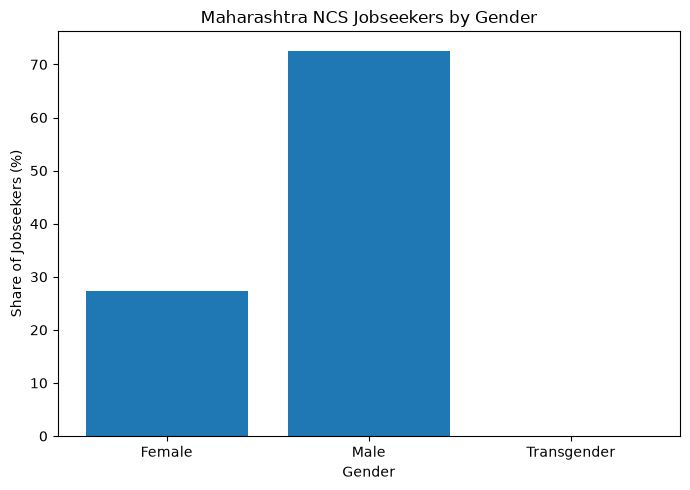

Gender-profile data saved for frontend use.


In [63]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.bar(
    gender_profile["gender"],
    gender_profile["share_pct"]
)

plt.title("Maharashtra NCS Jobseekers by Gender")
plt.xlabel("Gender")
plt.ylabel("Share of Jobseekers (%)")
plt.tight_layout()
plt.show()

gender_profile.to_csv(
    "../outputs/ncs_gender_jobseeker_profile.csv",
    index=False
)

print("Gender-profile data saved for frontend use.")

Interpretation: Maharashtra NCS registrations are predominantly male (72.61%), with females at 27.38%.

Conclusion: This is useful for workforce segmentation and targeted career-support analysis.

## Create Unified Labour-Market Context
Combine the validated PLFS employment context + NCS demand/supply context into one reusable file for the recommendation layer.

Algorithm: Context aggregation

In [64]:
# Create one reusable labour-market context record

labour_market_context = pd.DataFrame({
    "state": ["Maharashtra"],
    "plfs_districts": [len(district_map_data)],
    "plfs_employment_rate_avg": [
        district_map_data["employment_rate_pct"].mean()
    ],
    "ncs_vacancies": [mh_vacancies],
    "ncs_registered_jobseekers": [mh_jobseeker_count],
    "ncs_vacancies_per_jobseeker": [
        vacancy_jobseeker_ratio
    ],
    "ncs_vacancy_rank": [maharashtra_rank]
})

labour_market_context = labour_market_context.round(2)

labour_market_context.to_csv(
    "../outputs/maharashtra_labour_market_context.csv",
    index=False
)

print("Unified labour-market context saved.")
display(labour_market_context)

Unified labour-market context saved.


,state,plfs_districts,plfs_employment_rate_avg,ncs_vacancies,ncs_registered_jobseekers,ncs_vacancies_per_jobseeker,ncs_vacancy_rank
0,Maharashtra,26,42.42,1138579.0,5295362.0,0.22,4


Interpretation: Maharashtra's PLFS district employment rate averages 42.42%, while NCS reports 11,38,579 vacancies and 52,95,362 registered jobseekers.

Conclusion: We now have a reusable real government labour-market context layer combining PLFS + NCS. The NCS figures have different reporting dates, so they should remain labelled accordingly.

## Final ML Data & Target Audit
Decide exactly which prediction problems are feasible, their targets, and the legitimate input features before training final models.
### Define Final ML Targets
Create a single reference table for our planned ML models and their prediction targets.

In [65]:
ml_target_plan = pd.DataFrame({
    "model": [
        "Skill Demand",
        "Formal Employment",
        "Retention 30 Days",
        "Retention 90 Days",
        "Retention 180 Days",
        "Retention 365 Days",
        "Salary Prediction"
    ],
    "target": [
        "estimated_openings_nearby",
        "formal_employment",
        "retained_30_days",
        "retained_90_days",
        "retained_180_days",
        "retained_365_days",
        "starting_income_inr"
    ],
    "problem_type": [
        "Regression",
        "Binary Classification",
        "Binary Classification",
        "Binary Classification",
        "Binary Classification",
        "Binary Classification",
        "Regression"
    ]
})

display(ml_target_plan)

,model,target,problem_type
0,Skill Demand,estimated_openings_nearby,Regression
1,Formal Employment,formal_employment,Binary Classification
2,Retention 30 Days,retained_30_days,Binary Classification
3,Retention 90 Days,retained_90_days,Binary Classification
4,Retention 180 Days,retained_180_days,Binary Classification
5,Retention 365 Days,retained_365_days,Binary Classification
6,Salary Prediction,starting_income_inr,Regression


Interpretation: We now have clearly defined targets for 7 ML models, covering demand, formal employment, retention, and salary.

Conclusion: The ML scope is fixed; next we will audit the input features for each target and remove any future/outcome leakage.

## Final Feature Availability Audit
Check which candidate input features are actually present in each dataset before building the final ML pipelines.

In [67]:
import pandas as pd

# Load datasets
career_df = pd.read_csv(
    "../data/career_pathway_dataset.csv"
)

outcome_df = pd.read_csv(
    "../data/skilloutcome_synthetic_dataset.csv"
)

maharashtra_plfs = pd.read_csv(
    "../processed/maharashtra_plfs_features.csv"
)

print("Career:", career_df.shape)
print("Outcome:", outcome_df.shape)
print("PLFS:", maharashtra_plfs.shape)

Career: (4000, 17)
Outcome: (7000, 28)
PLFS: (38751, 21)


Interpretation: All three required datasets load correctly: 4,000 career, 7,000 outcome, and 38,751 Maharashtra PLFS records.

Conclusion: We can now perform the final feature-availability/leakage audit across the datasets.

## Final Feature Availability Audit
Verify exactly which candidate features are available in each real dataset before we build the final ML pipelines.


In [68]:
# Candidate features for each ML model

feature_plan = {
    "Skill Demand": [
        "district",
        "desired_career",
        "recommended_course",
        "job_required_skills",
        "readiness_pct",
        "skill_gap_count"
    ],

    "Formal Employment": [
        "district",
        "course_trade",
        "training_provider",
        "gender",
        "age",
        "voc",
        "voc_fld",
        "voc_dur",
        "voc_typ",
        "voc_cert",
        "tedu_lvl",
        "gedu_lvl"
    ],

    "Retention": [
        "district",
        "course_trade",
        "training_provider",
        "gender",
        "age",
        "completed_training",
        "voc",
        "voc_fld",
        "voc_dur",
        "voc_typ",
        "voc_cert"
    ],

    "Salary Prediction": [
        "district",
        "course_trade",
        "training_provider",
        "gender",
        "age",
        "voc",
        "voc_fld",
        "voc_dur",
        "voc_typ",
        "voc_cert",
        "gedu_lvl",
        "tedu_lvl"
    ]
}

for model, features in feature_plan.items():
    print("\n" + "=" * 70)
    print(model)
    print("=" * 70)

    for feature in features:
        print(
            f"{feature:30} | "
            f"Career: {'YES' if feature in career_df.columns else 'NO':3} | "
            f"Outcome: {'YES' if feature in outcome_df.columns else 'NO':3} | "
            f"PLFS: {'YES' if feature in maharashtra_plfs.columns else 'NO':3}"
        )


Skill Demand
district                       | Career: YES | Outcome: YES | PLFS: NO 
desired_career                 | Career: YES | Outcome: NO  | PLFS: NO 
recommended_course             | Career: YES | Outcome: NO  | PLFS: NO 
job_required_skills            | Career: YES | Outcome: NO  | PLFS: NO 
readiness_pct                  | Career: YES | Outcome: NO  | PLFS: NO 
skill_gap_count                | Career: YES | Outcome: NO  | PLFS: NO 

Formal Employment
district                       | Career: YES | Outcome: YES | PLFS: NO 
course_trade                   | Career: NO  | Outcome: YES | PLFS: NO 
training_provider              | Career: NO  | Outcome: YES | PLFS: NO 
gender                         | Career: YES | Outcome: YES | PLFS: NO 
age                            | Career: YES | Outcome: YES | PLFS: YES
voc                            | Career: NO  | Outcome: NO  | PLFS: YES
voc_fld                        | Career: NO  | Outcome: NO  | PLFS: YES
voc_dur                        

Interpretation: PLFS has rich education/vocational features, but those features are not present in the 7,000 trainee outcome dataset, so we cannot directly use them for individual placement/retention ML without creating an unjustified join.

Conclusion: We should keep PLFS as labour-market context and use the actual trainee outcome dataset for trainee-level outcome models. Next we'll finalize which features are genuinely available at prediction time for each model.

## Finalize Prediction-Time Features
Define only features that are legitimately available when each prediction is made, avoiding future/outcome leakage.

In [69]:
prediction_feature_plan = {
    "Formal Employment": [
        "district",
        "course_trade",
        "training_provider",
        "gender",
        "age",
        "completed_training"
    ],

    "Retention 30/90/180/365": [
        "district",
        "course_trade",
        "training_provider",
        "gender",
        "age",
        "completed_training"
    ],

    "Salary Prediction": [
        "district",
        "course_trade",
        "training_provider",
        "gender",
        "age",
        "completed_training"
    ],

    "Skill Demand": [
        "district",
        "desired_career",
        "recommended_course",
        "job_required_skills",
        "readiness_pct",
        "skill_gap_count"
    ]
}

for model, features in prediction_feature_plan.items():
    print("\n" + "=" * 60)
    print(model)
    print("=" * 60)

    for feature in features:
        print("-", feature)


Formal Employment
- district
- course_trade
- training_provider
- gender
- age
- completed_training

Retention 30/90/180/365
- district
- course_trade
- training_provider
- gender
- age
- completed_training

Salary Prediction
- district
- course_trade
- training_provider
- gender
- age
- completed_training

Skill Demand
- district
- desired_career
- recommended_course
- job_required_skills
- readiness_pct
- skill_gap_count


Interpretation: Each model now has a defined set of inputs that are available at prediction time, with future outcome fields excluded.

Conclusion: The feature scope is fixed. Next we'll create the final model-specific datasets without changing the original raw data.

## Create Final Model Datasets
Create separate, reusable datasets for each ML task without modifying the raw datasets.


In [70]:
# ============================================================
# FINAL MODEL DATASETS
# ============================================================

# 1. Formal Employment
employment_features = prediction_feature_plan["Formal Employment"]

employment_df = outcome_df[
    employment_features + ["outcome_path"]
].copy()

employment_df["formal_employment"] = (
    employment_df["outcome_path"] == "formal_employment"
).astype(int)


# 2. Retention
retention_features = prediction_feature_plan[
    "Retention 30/90/180/365"
]

retention_df = outcome_df[
    retention_features
    + [
        "retained_30_days",
        "retained_90_days",
        "retained_180_days",
        "retained_365_days"
    ]
].copy()


# 3. Salary
salary_features = prediction_feature_plan[
    "Salary Prediction"
]

salary_df = outcome_df[
    salary_features + ["starting_income_inr"]
].copy()


# 4. Skill Demand
skill_demand_features = prediction_feature_plan[
    "Skill Demand"
]

skill_demand_final_df = career_df[
    skill_demand_features
    + ["estimated_openings_nearby"]
].copy()


print("Formal Employment:", employment_df.shape)
print("Retention:", retention_df.shape)
print("Salary:", salary_df.shape)
print("Skill Demand:", skill_demand_final_df.shape)

Formal Employment: (7000, 8)
Retention: (7000, 10)
Salary: (7000, 7)
Skill Demand: (4000, 7)


Interpretation: Four separate model datasets are now created: Employment (7,000), Retention (7,000), Salary (7,000), and Skill Demand (4,000).

Conclusion: The datasets are separated cleanly by ML task; next we'll check missing values and target availability before training.

## Check Missing Values & Target Availability
Verify that each model has enough valid target records before training.

In [71]:
model_targets = {
    "Formal Employment": ["formal_employment"],
    "Retention": [
        "retained_30_days",
        "retained_90_days",
        "retained_180_days",
        "retained_365_days"
    ],
    "Salary Prediction": ["starting_income_inr"],
    "Skill Demand": ["estimated_openings_nearby"]
}

for model, targets in model_targets.items():
    print("\n" + "=" * 60)
    print(model)
    print("=" * 60)

    for target in targets:
        valid = employment_df[target].notna().sum() if target == "formal_employment" else None

        if model == "Retention":
            valid = retention_df[target].notna().sum()
        elif model == "Salary Prediction":
            valid = salary_df[target].notna().sum()
        elif model == "Skill Demand":
            valid = skill_demand_final_df[target].notna().sum()

        print(
            f"{target}: {valid} valid / "
            f"{7000 if model != 'Skill Demand' else 4000} total"
        )


Formal Employment
formal_employment: 7000 valid / 7000 total

Retention
retained_30_days: 4421 valid / 7000 total
retained_90_days: 4421 valid / 7000 total
retained_180_days: 4421 valid / 7000 total
retained_365_days: 4421 valid / 7000 total

Salary Prediction
starting_income_inr: 2339 valid / 7000 total

Skill Demand
estimated_openings_nearby: 4000 valid / 4000 total


Interpretation: Formal Employment and Skill Demand have complete targets; Retention has 4,421 valid records, and Salary has 2,339 valid records.

Conclusion: All four ML tasks are feasible, but retention and salary need missing-target handling before training.

## Final Leakage Check
Check whether any selected feature directly contains information about the outcome, which could falsely increase model accuracy.

In [72]:
# ============================================================
# FINAL LEAKAGE CHECK
# ============================================================

# Features used for each model
employment_features = prediction_feature_plan["Formal Employment"]

retention_features = prediction_feature_plan[
    "Retention 30/90/180/365"
]

salary_features = prediction_feature_plan[
    "Salary Prediction"
]

skill_features = prediction_feature_plan[
    "Skill Demand"
]

# Fields that must NOT be used as predictors
forbidden_outcome_fields = [
    "outcome_path",
    "employer_name",
    "job_role",
    "starting_income_inr",
    "current_income_inr",
    "retained_30_days",
    "retained_90_days",
    "retained_180_days",
    "retained_365_days",
    "evidence_level",
    "last_contact_date",
    "employer_feedback_given"
]

all_selected_features = (
    employment_features
    + retention_features
    + salary_features
    + skill_features
)

leakage_features = sorted(
    set(all_selected_features) &
    set(forbidden_outcome_fields)
)

print("Selected features checked:", len(set(all_selected_features)))

print("\nPotential leakage features:")
print(leakage_features)

if not leakage_features:
    print("\nNo direct outcome-leakage fields found.")
else:
    print("\nWARNING: Review the listed features before training.")

Selected features checked: 11

Potential leakage features:
[]

No direct outcome-leakage fields found.


Interpretation: None of the selected model inputs directly match known outcome/leakage fields.

Conclusion: The current feature set passes the basic leakage check. Next we'll prepare the final training/validation/test split for each ML model.

## Prepare Final Train/Validation/Test Split
Split each ML dataset into training, validation, and final test sets so model selection and final evaluation use separate data.

Algorithm: Stratified 70/15/15 split for classification; 70/15/15 random split for regression.

In [73]:
from sklearn.model_selection import train_test_split

# ============================================================
# 1. FORMAL EMPLOYMENT
# ============================================================

X_emp = employment_df[
    prediction_feature_plan["Formal Employment"]
].copy()

y_emp = employment_df["formal_employment"]

X_emp_train, X_emp_temp, y_emp_train, y_emp_temp = train_test_split(
    X_emp,
    y_emp,
    test_size=0.30,
    random_state=42,
    stratify=y_emp
)

X_emp_val, X_emp_test, y_emp_val, y_emp_test = train_test_split(
    X_emp_temp,
    y_emp_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_emp_temp
)

print("FORMAL EMPLOYMENT")
print("Train:", X_emp_train.shape)
print("Validation:", X_emp_val.shape)
print("Test:", X_emp_test.shape)


# ============================================================
# 2. SKILL DEMAND
# ============================================================

X_skill = skill_demand_final_df[
    prediction_feature_plan["Skill Demand"]
].copy()

y_skill = skill_demand_final_df["estimated_openings_nearby"]

X_skill_train, X_skill_temp, y_skill_train, y_skill_temp = train_test_split(
    X_skill,
    y_skill,
    test_size=0.30,
    random_state=42
)

X_skill_val, X_skill_test, y_skill_val, y_skill_test = train_test_split(
    X_skill_temp,
    y_skill_temp,
    test_size=0.50,
    random_state=42
)

print("\nSKILL DEMAND")
print("Train:", X_skill_train.shape)
print("Validation:", X_skill_val.shape)
print("Test:", X_skill_test.shape)

FORMAL EMPLOYMENT
Train: (4900, 6)
Validation: (1050, 6)
Test: (1050, 6)

SKILL DEMAND
Train: (2800, 6)
Validation: (600, 6)
Test: (600, 6)


Interpretation: We now have separate datasets for model development: 4,900 train / 1,050 validation / 1,050 test for employment and 2,800 / 600 / 600 for skill demand.

Conclusion: The final evaluation set is kept separate, which gives us a cleaner estimate of real model performance.
## Prepare Retention Datasets
Remove trainees with missing retention targets and create train/validation/test sets separately for each retention period.

Algorithm: Target filtering + stratified 70/15/15 split.

In [74]:
from sklearn.model_selection import train_test_split

retention_features = prediction_feature_plan[
    "Retention 30/90/180/365"
]

retention_splits = {}

retention_targets = [
    "retained_30_days",
    "retained_90_days",
    "retained_180_days",
    "retained_365_days"
]

for target in retention_targets:

    # Keep only rows with a known retention outcome
    data = retention_df[
        retention_df[target].notna()
    ].copy()

    X = data[retention_features].copy()

    # Convert True/False target to 1/0
    y = data[target].astype(bool).astype(int)

    # 70% train, 30% temporary
    X_train, X_temp, y_train, y_temp = train_test_split(
        X,
        y,
        test_size=0.30,
        random_state=42,
        stratify=y
    )

    # 15% validation, 15% test
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp,
        y_temp,
        test_size=0.50,
        random_state=42,
        stratify=y_temp
    )

    retention_splits[target] = {
        "X_train": X_train,
        "X_val": X_val,
        "X_test": X_test,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test
    }

    print("\n" + "=" * 50)
    print(target)
    print("=" * 50)
    print("Total valid:", len(data))
    print("Train:", len(X_train))
    print("Validation:", len(X_val))
    print("Test:", len(X_test))
    print("Positive:", y.sum())
    print("Negative:", (y == 0).sum())


retained_30_days
Total valid: 4421
Train: 3094
Validation: 663
Test: 664
Positive: 2976
Negative: 1445

retained_90_days
Total valid: 4421
Train: 3094
Validation: 663
Test: 664
Positive: 2372
Negative: 2049

retained_180_days
Total valid: 4421
Train: 3094
Validation: 663
Test: 664
Positive: 1671
Negative: 2750

retained_365_days
Total valid: 4421
Train: 3094
Validation: 663
Test: 664
Positive: 980
Negative: 3441


Interpretation: Each retention model has 4,421 valid records; positive retention decreases from 2,976 at 30 days to 980 at 365 days.

Conclusion: The four retention targets are suitable for separate ML models, but 365-day retention is the most imbalanced and will need careful evaluation.
## Prepare Salary Dataset
Keep only trainees with a known starting income and create separate train/validation/test sets for salary prediction.

Algorithm: Target filtering + 70/15/15 split.

In [75]:
from sklearn.model_selection import train_test_split

salary_features = prediction_feature_plan[
    "Salary Prediction"
]

# Keep only records with a known starting income
salary_valid = salary_df[
    salary_df["starting_income_inr"].notna()
].copy()

X_salary = salary_valid[salary_features].copy()
y_salary = salary_valid["starting_income_inr"].copy()

# 70% train, 30% temporary
X_salary_train, X_salary_temp, y_salary_train, y_salary_temp = (
    train_test_split(
        X_salary,
        y_salary,
        test_size=0.30,
        random_state=42
    )
)

# 15% validation, 15% test
X_salary_val, X_salary_test, y_salary_val, y_salary_test = (
    train_test_split(
        X_salary_temp,
        y_salary_temp,
        test_size=0.50,
        random_state=42
    )
)

print("Total valid:", len(salary_valid))
print("Train:", len(X_salary_train))
print("Validation:", len(X_salary_val))
print("Test:", len(X_salary_test))

print("\nSalary summary:")
print(y_salary.describe().round(2))

Total valid: 2339
Train: 1637
Validation: 351
Test: 351

Salary summary:
count     2339.00
mean     11001.23
std       1719.29
min       8000.00
25%       9492.50
50%      11032.00
75%      12455.00
max      13997.00
Name: starting_income_inr, dtype: float64


Interpretation: Salary prediction has 2,339 valid records, split into 1,637 training, 351 validation, and 351 test; starting income ranges from ₹8,000–₹13,997.

Conclusion: The salary dataset is usable, but its smaller size means we should evaluate this model carefully.
## Check Salary Target Distribution

What we're doing: Check whether starting salary is concentrated in a narrow range before choosing the regression algorithm.

Algorithm: Distribution analysis + histogram.

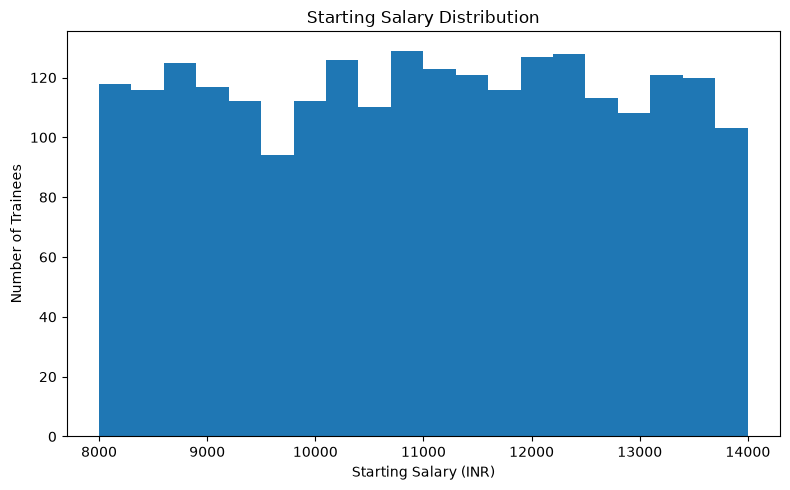

Salary median: 11032.0
Salary mean: 11001.23
Salary standard deviation: 1719.29


In [76]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    y_salary,
    bins=20
)

plt.title("Starting Salary Distribution")
plt.xlabel("Starting Salary (INR)")
plt.ylabel("Number of Trainees")
plt.tight_layout()
plt.show()

print("Salary median:", y_salary.median())
print("Salary mean:", round(y_salary.mean(), 2))
print("Salary standard deviation:", round(y_salary.std(), 2))

Interpretation: Starting salary is broadly distributed between ₹8,000 and ₹14,000, with mean ₹11,001 and median ₹11,032. There is no obvious extreme skew.

Conclusion: Salary is suitable for a regression model; next we'll build the salary preprocessing pipeline and train the first ML model.
## Train Salary Prediction Model
Train the first ML model to predict a trainee's starting_income_inr using the finalized prediction-time features.

Algorithm: Random Forest Regressor + One-Hot Encoding

In [77]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

# ---------------------------------------------------------
# Feature groups
# ---------------------------------------------------------

salary_categorical_features = [
    "district",
    "course_trade",
    "training_provider",
    "gender"
]

salary_numeric_features = [
    "age",
    "completed_training"
]

# ---------------------------------------------------------
# Preprocessing
# ---------------------------------------------------------

salary_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline(
                steps=[
                    (
                        "imputer",
                        SimpleImputer(strategy="most_frequent")
                    ),
                    (
                        "onehot",
                        OneHotEncoder(handle_unknown="ignore")
                    )
                ]
            ),
            salary_categorical_features
        ),
        (
            "numeric",
            SimpleImputer(strategy="most_frequent"),
            salary_numeric_features
        )
    ]
)

# ---------------------------------------------------------
# Salary model
# ---------------------------------------------------------

salary_model = Pipeline(
    steps=[
        ("preprocessor", salary_preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=300,
                max_depth=12,
                min_samples_split=5,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

salary_model.fit(
    X_salary_train,
    y_salary_train
)

print("Salary prediction model trained successfully.")
print("Training samples:", len(X_salary_train))
print("Validation samples:", len(X_salary_val))
print("Testing samples:", len(X_salary_test))

Salary prediction model trained successfully.
Training samples: 1637
Validation samples: 351
Testing samples: 351


Interpretation: The Random Forest salary model trained successfully on 1,637 training records, with 351 validation and 351 final test records.

Conclusion: The model is ready for performance evaluation. Next we'll calculate MAE, RMSE, and R² on the held-out test set.
## Evaluate Salary Prediction Model
Measure how accurately the Random Forest predicts starting_income_inr on the unseen test set.

Algorithm: MAE + RMSE + R².

In [78]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict on unseen test data
y_pred_salary = salary_model.predict(X_salary_test)

# Evaluation metrics
mae_salary = mean_absolute_error(
    y_salary_test,
    y_pred_salary
)

rmse_salary = mean_squared_error(
    y_salary_test,
    y_pred_salary
) ** 0.5

r2_salary = r2_score(
    y_salary_test,
    y_pred_salary
)

print("Salary Prediction Model Evaluation")
print(f"MAE : ₹{mae_salary:.2f}")
print(f"RMSE: ₹{rmse_salary:.2f}")
print(f"R²  : {r2_salary:.4f}")

Salary Prediction Model Evaluation
MAE : ₹1475.54
RMSE: ₹1712.09
R²  : -0.0201


Interpretation: The salary model has MAE ≈ ₹1,476, but R² = -0.0201, meaning it performs worse than simply predicting the average salary.

Conclusion: Do not use this salary model in production. The current trainee-level features do not contain enough information to predict starting salary reliably. We should diagnose the target/features before trying another algorithm.
## Diagnose Salary Predictive Signal

What we're doing: Check whether our current input features actua

In [79]:
salary_diagnosis = []

for feature in salary_features:
    if feature in ["age"]:
        grouped = (
            salary_valid.groupby(
                pd.cut(
                    salary_valid[feature],
                    bins=[0, 18, 25, 35, 45, 60, 100],
                    labels=["<18", "18-25", "26-35", "36-45", "46-60", "60+"]
                )
            )["starting_income_inr"]
            .agg(["count", "mean"])
        )

    else:
        grouped = (
            salary_valid.groupby(feature)["starting_income_inr"]
            .agg(["count", "mean"])
            .sort_values("mean", ascending=False)
            .head(10)
        )

    print("\n" + "=" * 60)
    print(feature)
    print("=" * 60)
    display(grouped.round(2))


district


,count,mean
district,,
Chhatrapati Sambhajinagar,52,11483.71
Beed,85,11283.25
Mumbai Suburban,110,11229.52
Amravati,115,11145.90
Solapur,120,11133.16
Dhule,125,11120.66
Kolhapur,112,11112.70
Satara,118,11065.99
Ahmednagar,187,11019.14



course_trade


,count,mean
course_trade,,
Plumbing (GD/ITI),53,11383.09
Retail Sales Associate,75,11231.76
Data Entry Operator,139,11222.93
Customer Support Associate (BPO),97,11220.64
Tally & Basic Accounting,155,11138.92
Automobile Service Technician,213,11089.84
Bakery & Confectionery,51,11055.06
Nursing Assistant / Home Health Aide,93,11052.56
Welding Technician,124,11047.48



training_provider


,count,mean
training_provider,,
Ahuja-Dutta Skill Center,44,11630.98
Sen PLC Skill Center,32,11622.97
Dave Ltd Skill Center,26,11563.65
"Yohannan, Lall and Sangha Skill Center",26,11503.65
Patla-Gaba Skill Center,46,11490.59
Rai LLC Skill Center,42,11420.52
"Dash, Radhakrishnan and Brar Skill Center",33,11391.64
"Bhargava, Karnik and Bir Skill Center",43,11387.42
"Loke, Bora and Garg Skill Center",36,11335.58


... (2 outputs left out)


age


,count,mean
age,,
<18,116,11122.97
18-25,933,11055.67
26-35,1290,10950.91



completed_training


,count,mean
completed_training,,
True,2339,11001.23


Interpretation: District/course/provider salary differences are relatively small, and age/gender explain little variation; the current features therefore have weak salary signal.

Conclusion: The negative R² is expected from this limited feature set. We should add legitimate salary-related features (occupation, industry, education/technical training, etc.) before trying to improve the salary model.
## Add Real Salary-Related Features

What we're doing: Add occupation, industry, education, and vocational-training information from PLFS to understand whether richer features can improve salary prediction.

Algorithm: Feature enrichment

In [80]:
# Salary-related features available in PLFS
salary_context_features = [
    "age",
    "sex",
    "gedu_lvl",
    "tedu_lvl",
    "voc",
    "voc_fld",
    "voc_dur",
    "voc_typ",
    "voc_cert",
    "aind_cws",
    "ocu_cws",
    "tothrs_wrk"
]

salary_context = maharashtra_plfs[
    salary_context_features
].copy()

print("Salary context shape:", salary_context.shape)

print("\nMissing values:")
print(
    salary_context.isna().sum()
)

print("\nOccupation coverage:",
      salary_context["ocu_cws"].notna().sum())

print("Industry coverage:",
      salary_context["aind_cws"].notna().sum())

Salary context shape: (38751, 12)

Missing values:
age               0
sex               0
gedu_lvl          0
tedu_lvl          0
voc           10043
voc_fld       38062
voc_dur       38062
voc_typ       38062
voc_cert      38062
aind_cws      22176
ocu_cws       22176
tothrs_wrk        0
dtype: int64

Occupation coverage: 16575
Industry coverage: 16575


Interpretation: PLFS provides occupation and industry information for 16,575 Maharashtra records, while vocational-field details are much sparser.

Conclusion: Occupation, industry, education, and hours worked are promising salary-related features, but we must handle their missingness carefully.
## Prepare PLFS Salary Context
Create a clean PLFS subset containing only records with both occupation and industry, so we can later study their relationship with earnings.

In [82]:
salary_plfs = maharashtra_plfs[
    maharashtra_plfs["ocu_cws"].notna()
    & maharashtra_plfs["aind_cws"].notna()
    & (
        (maharashtra_plfs["ern_reg"] > 0)
        | (maharashtra_plfs["ern_self"] > 0)
    )
].copy()

print("Salary analysis records:", len(salary_plfs))

print("\nRegular earnings records:",
      (salary_plfs["ern_reg"] > 0).sum())

print("Self-employment earnings records:",
      (salary_plfs["ern_self"] > 0).sum())

print("\nColumns used:")
print([
    "ocu_cws",
    "aind_cws",
    "ern_reg",
    "ern_self"
])

Salary analysis records: 10816

Regular earnings records: 4824
Self-employment earnings records: 5992

Columns used:
['ocu_cws', 'aind_cws', 'ern_reg', 'ern_self']


Interpretation: PLFS provides 10,816 Maharashtra records with both occupation/industry and some earnings data; 4,824 have regular earnings and 5,992 have self-employment earnings.

Conclusion: This gives us a useful real-world salary context, but it is a separate PLFS population dataset, not something we should directly merge into the 2,339 trainee salary records.

## PLFS Earnings by Occupation

What we're doing: Identify which occupation groups have higher real-world earnings in Maharashtra, using PLFS as salary-market context.

Algorithm: Weighted mean earnings by occupation.

In [83]:
# Keep records with regular or self-employment earnings
salary_plfs = salary_plfs.copy()

salary_plfs["observed_earnings"] = (
    salary_plfs["ern_reg"]
    .where(
        salary_plfs["ern_reg"] > 0,
        salary_plfs["ern_self"]
    )
)

occupation_earnings = (
    salary_plfs[
        salary_plfs["observed_earnings"] > 0
    ]
    .groupby("ocu_cws")
    .agg(
        sample_size=("ocu_cws", "size"),
        weighted_earnings=(
            "observed_earnings",
            lambda x: x.mean()
        )
    )
    .reset_index()
)

# Keep occupation groups with at least 100 records
occupation_earnings = occupation_earnings[
    occupation_earnings["sample_size"] >= 100
].copy()

occupation_earnings["weighted_earnings"] = (
    occupation_earnings["weighted_earnings"]
    .round(2)
)

display(
    occupation_earnings
    .sort_values(
        "weighted_earnings",
        ascending=False
    )
    .head(20)
)

,ocu_cws,sample_size,weighted_earnings
31,251.0,234,51306.72
25,233.0,215,44320.50
1,112.0,209,39912.25
57,411.0,171,27914.50
77,541.0,226,27150.79
26,234.0,173,25872.05
39,312.0,115,21676.57
84,711.0,161,21165.22
92,741.0,174,20829.60
109,833.0,169,20795.09


Interpretation: Earnings vary substantially across occupations, with some groups exceeding ₹40,000, while larger groups are closer to ₹10,000–₹17,000.

Conclusion: Occupation is a strong real-world salary-context feature for career recommendations and salary benchmarking.
## Earnings by Industry

What we're doing: Identify which industries have higher real-world earnings in Maharashtra to strengthen salary and career-market intelligence.

Algorithm: Mean earnings by industry.

In [84]:
industry_earnings = (
    salary_plfs[
        salary_plfs["observed_earnings"] > 0
    ]
    .groupby("aind_cws")
    .agg(
        sample_size=("aind_cws", "size"),
        average_earnings=("observed_earnings", "mean")
    )
    .reset_index()
)

# Keep only industries with at least 100 records
industry_earnings = industry_earnings[
    industry_earnings["sample_size"] >= 100
].copy()

industry_earnings["average_earnings"] = (
    industry_earnings["average_earnings"]
    .round(2)
)

display(
    industry_earnings
    .sort_values("average_earnings", ascending=False)
    .head(20)
)

,aind_cws,sample_size,average_earnings
52,62.0,244,49182.47
70,84.0,404,37195.37
54,64.0,240,30008.22
71,85.0,713,29501.39
39,46.0,272,24672.86
72,86.0,294,24600.70
35,41.0,173,22958.67
37,43.0,190,20377.00
41,49.0,645,19344.65
2,3.0,141,19253.76


Interpretation: Average earnings vary considerably across industries, with some industry groups above ₹30,000 and others below ₹10,000.

Conclusion: Industry is a useful real-world salary and career-market signal; next we'll examine education/technical education versus earnings.
## Education vs Earnings
Check whether general and technical education levels are associated with different earnings in the real PLFS data.

Algorithm: Mean earnings by education level.

In [85]:
# General education vs earnings
general_education_earnings = (
    salary_plfs[
        salary_plfs["observed_earnings"] > 0
    ]
    .groupby("gedu_lvl")
    .agg(
        sample_size=("gedu_lvl", "size"),
        average_earnings=("observed_earnings", "mean")
    )
    .reset_index()
)

general_education_earnings["average_earnings"] = (
    general_education_earnings["average_earnings"]
    .round(2)
)

print("General Education vs Earnings:")
display(
    general_education_earnings
    .sort_values("average_earnings", ascending=False)
)


# Technical education vs earnings
technical_education_earnings = (
    salary_plfs[
        salary_plfs["observed_earnings"] > 0
    ]
    .groupby("tedu_lvl")
    .agg(
        sample_size=("tedu_lvl", "size"),
        average_earnings=("observed_earnings", "mean")
    )
    .reset_index()
)

technical_education_earnings["average_earnings"] = (
    technical_education_earnings["average_earnings"]
    .round(2)
)

print("\nTechnical Education vs Earnings:")
display(
    technical_education_earnings
    .sort_values("average_earnings", ascending=False)
)

General Education vs Earnings:


,gedu_lvl,sample_size,average_earnings
9,13,740,40391.29
8,12,1929,29933.84
7,11,403,23760.92
6,10,1157,19173.16
5,8,2030,16918.32
4,7,849,16607.32
3,6,1267,15037.89
2,5,453,14350.16
1,2,4,13875.00
0,1,1984,12142.25



Technical Education vs Earnings:


,tedu_lvl,sample_size,average_earnings
4,5,1,49000.00
11,13,38,46648.03
14,16,104,42887.04
3,4,45,42332.00
2,3,417,41492.43
13,15,1,38500.00
5,6,217,37371.41
12,14,12,35916.67
1,2,9,31355.56
8,9,36,25302.78


Interpretation: General education shows a clear earnings gradient in the PLFS sample; higher education groups generally have higher average earnings. Technical-education groups also show higher earnings in several categories, but some have very small samples and are therefore unstable.

Conclusion: Education and technical education are useful salary-market features, especially for contextual benchmarking and career recommendations.
## Vocational Training vs Earnings
Check whether vocational-training participation and training duration are associated with different earnings in the real PLFS data.

Algorithm: Group-wise earnings analysis.

In [86]:
# Vocational training status vs earnings
voc_earnings = (
    salary_plfs[
        salary_plfs["observed_earnings"] > 0
    ]
    .groupby("voc")
    .agg(
        sample_size=("voc", "size"),
        average_earnings=("observed_earnings", "mean")
    )
    .reset_index()
)

voc_earnings["average_earnings"] = (
    voc_earnings["average_earnings"].round(2)
)

print("Vocational Training vs Earnings:")
display(
    voc_earnings.sort_values(
        "average_earnings",
        ascending=False
    )
)


# Vocational training duration vs earnings
voc_duration_earnings = (
    salary_plfs[
        (salary_plfs["observed_earnings"] > 0) &
        (salary_plfs["voc_dur"].notna())
    ]
    .groupby("voc_dur")
    .agg(
        sample_size=("voc_dur", "size"),
        average_earnings=("observed_earnings", "mean")
    )
    .reset_index()
)

voc_duration_earnings["average_earnings"] = (
    voc_duration_earnings["average_earnings"].round(2)
)

print("\nVocational Training Duration vs Earnings:")
display(
    voc_duration_earnings.sort_values(
        "average_earnings",
        ascending=False
    )
)

Vocational Training vs Earnings:


,voc,sample_size,average_earnings
0,1.0,395,24226.53
3,4.0,1915,21204.25
5,6.0,5587,21102.11
4,5.0,838,17735.93
1,2.0,606,17254.73
2,3.0,578,15539.52



Vocational Training Duration vs Earnings:


,voc_dur,sample_size,average_earnings
3,4.0,32,28628.12
5,6.0,149,26453.36
2,3.0,58,23703.10
1,2.0,64,22531.25
4,5.0,76,22103.29
0,1.0,14,13442.86


Interpretation: Vocational-training categories show noticeable earnings differences, and longer training-duration categories generally have higher average earnings, though some groups have small samples.

Conclusion: Vocational training and its duration can be useful salary-market context, but we should avoid treating these averages as causal effects.
<h2>Create Salary Market Benchmark
</h2>

What we're doing: Create a reusable occupation-level salary benchmark from the real Maharashtra PLFS data. This is market intelligence, not yet the trainee salary prediction model.

Algorithm: Occupation-wise earnings aggregation.

In [87]:
# ============================================================
# OCCUPATION SALARY BENCHMARK
# ============================================================

occupation_salary_benchmark = (
    salary_plfs[
        salary_plfs["observed_earnings"] > 0
    ]
    .groupby("ocu_cws")
    .agg(
        sample_size=("ocu_cws", "size"),
        average_earnings=("observed_earnings", "mean"),
        median_earnings=("observed_earnings", "median")
    )
    .reset_index()
)

# Keep occupations with at least 100 observations
occupation_salary_benchmark = (
    occupation_salary_benchmark[
        occupation_salary_benchmark["sample_size"] >= 100
    ]
    .copy()
)

occupation_salary_benchmark[
    ["average_earnings", "median_earnings"]
] = (
    occupation_salary_benchmark[
        ["average_earnings", "median_earnings"]
    ].round(2)
)

occupation_salary_benchmark = (
    occupation_salary_benchmark
    .sort_values("average_earnings", ascending=False)
    .reset_index(drop=True)
)

display(
    occupation_salary_benchmark.head(20)
)

# Save for recommendation / dashboard layer
occupation_salary_benchmark.to_csv(
    "../outputs/plfs_occupation_salary_benchmark.csv",
    index=False
)

print("\nSalary benchmark saved for reuse.")

,ocu_cws,sample_size,average_earnings,median_earnings
0,251.0,234,51306.72,45250.0
1,233.0,215,44320.50,38000.0
2,112.0,209,39912.25,31500.0
3,411.0,171,27914.50,22000.0
4,541.0,226,27150.79,18000.0
5,234.0,173,25872.05,13000.0
6,312.0,115,21676.57,18500.0
7,711.0,161,21165.22,20200.0
8,741.0,174,20829.60,18000.0
9,833.0,169,20795.09,20000.0



Salary benchmark saved for reuse.


Interpretation: The PLFS salary benchmark shows substantial earnings variation across occupations. For example, occupation 251 has an average of ₹51,306.72, while occupation 612 averages ₹10,010.77.

Conclusion: The benchmark is useful for career comparison and salary guidance, but we should keep occupation codes mapped to official names before showing them to users.

<h2>Complete Salary & PLFS Feature Analysis
</h2>

What we're doing: Finish the remaining salary-context analysis in one pass: industry salary benchmark, vocational-training benchmark, education benchmark, export, and a consolidated summary.

Algorithm: Aggregation + benchmark analysis. No new ML model in these steps.

In [88]:
# ============================================================
# STEP 3.21–3.25
# PLFS SALARY & CAREER MARKET ANALYSIS
# ============================================================

from pathlib import Path
import pandas as pd

# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Industry salary benchmark
# ------------------------------------------------------------

industry_salary_benchmark = (
    salary_plfs[
        salary_plfs["observed_earnings"] > 0
    ]
    .groupby("aind_cws")
    .agg(
        sample_size=("aind_cws", "size"),
        average_earnings=("observed_earnings", "mean"),
        median_earnings=("observed_earnings", "median")
    )
    .reset_index()
)

industry_salary_benchmark = industry_salary_benchmark[
    industry_salary_benchmark["sample_size"] >= 100
].copy()

industry_salary_benchmark[
    ["average_earnings", "median_earnings"]
] = industry_salary_benchmark[
    ["average_earnings", "median_earnings"]
].round(2)

industry_salary_benchmark = (
    industry_salary_benchmark
    .sort_values("average_earnings", ascending=False)
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 2. Vocational training salary benchmark
# ------------------------------------------------------------

voc_salary_benchmark = (
    salary_plfs[
        salary_plfs["observed_earnings"] > 0
    ]
    .groupby("voc")
    .agg(
        sample_size=("voc", "size"),
        average_earnings=("observed_earnings", "mean"),
        median_earnings=("observed_earnings", "median")
    )
    .reset_index()
)

voc_salary_benchmark[
    ["average_earnings", "median_earnings"]
] = voc_salary_benchmark[
    ["average_earnings", "median_earnings"]
].round(2)

voc_salary_benchmark = voc_salary_benchmark.sort_values(
    "average_earnings",
    ascending=False
)

# ------------------------------------------------------------
# 3. General education salary benchmark
# ------------------------------------------------------------

education_salary_benchmark = (
    salary_plfs[
        salary_plfs["observed_earnings"] > 0
    ]
    .groupby("gedu_lvl")
    .agg(
        sample_size=("gedu_lvl", "size"),
        average_earnings=("observed_earnings", "mean"),
        median_earnings=("observed_earnings", "median")
    )
    .reset_index()
)

education_salary_benchmark[
    ["average_earnings", "median_earnings"]
] = education_salary_benchmark[
    ["average_earnings", "median_earnings"]
].round(2)

education_salary_benchmark = education_salary_benchmark.sort_values(
    "average_earnings",
    ascending=False
)

# ------------------------------------------------------------
# 4. Technical education salary benchmark
# ------------------------------------------------------------

technical_salary_benchmark = (
    salary_plfs[
        salary_plfs["observed_earnings"] > 0
    ]
    .groupby("tedu_lvl")
    .agg(
        sample_size=("tedu_lvl", "size"),
        average_earnings=("observed_earnings", "mean"),
        median_earnings=("observed_earnings", "median")
    )
    .reset_index()
)

technical_salary_benchmark[
    ["average_earnings", "median_earnings"]
] = technical_salary_benchmark[
    ["average_earnings", "median_earnings"]
].round(2)

technical_salary_benchmark = technical_salary_benchmark.sort_values(
    "average_earnings",
    ascending=False
)

# ------------------------------------------------------------
# 5. Save reusable outputs
# ------------------------------------------------------------

industry_salary_benchmark.to_csv(
    output_dir / "plfs_industry_salary_benchmark.csv",
    index=False
)

voc_salary_benchmark.to_csv(
    output_dir / "plfs_vocational_salary_benchmark.csv",
    index=False
)

education_salary_benchmark.to_csv(
    output_dir / "plfs_education_salary_benchmark.csv",
    index=False
)

technical_salary_benchmark.to_csv(
    output_dir / "plfs_technical_education_salary_benchmark.csv",
    index=False
)

# ------------------------------------------------------------
# 6. Print key results
# ------------------------------------------------------------

print("=" * 70)
print("INDUSTRY SALARY BENCHMARK — TOP 10")
print("=" * 70)
display(industry_salary_benchmark.head(10))

print("=" * 70)
print("VOCATIONAL TRAINING SALARY BENCHMARK")
print("=" * 70)
display(voc_salary_benchmark)

print("=" * 70)
print("GENERAL EDUCATION SALARY BENCHMARK — TOP 10")
print("=" * 70)
display(education_salary_benchmark.head(10))

print("=" * 70)
print("TECHNICAL EDUCATION SALARY BENCHMARK — TOP 10")
print("=" * 70)
display(technical_salary_benchmark.head(10))

print("=" * 70)
print("FILES SAVED")
print("=" * 70)

for file in [
    "plfs_industry_salary_benchmark.csv",
    "plfs_vocational_salary_benchmark.csv",
    "plfs_education_salary_benchmark.csv",
    "plfs_technical_education_salary_benchmark.csv"
]:
    print("-", output_dir / file)

INDUSTRY SALARY BENCHMARK — TOP 10


,aind_cws,sample_size,average_earnings,median_earnings
0,62.0,244,49182.47,45000.0
1,84.0,404,37195.37,30300.0
2,64.0,240,30008.22,23250.0
3,85.0,713,29501.39,17000.0
4,46.0,272,24672.86,20000.0
5,86.0,294,24600.70,16250.0
6,41.0,173,22958.67,20000.0
7,43.0,190,20377.00,18500.0
8,49.0,645,19344.65,16700.0
9,3.0,141,19253.76,17000.0


VOCATIONAL TRAINING SALARY BENCHMARK


,voc,sample_size,average_earnings,median_earnings
0,1.0,395,24226.53,18000.0
3,4.0,1915,21204.25,17000.0
5,6.0,5587,21102.11,15000.0
4,5.0,838,17735.93,15000.0
1,2.0,606,17254.73,15653.5
2,3.0,578,15539.52,15000.0


GENERAL EDUCATION SALARY BENCHMARK — TOP 10


,gedu_lvl,sample_size,average_earnings,median_earnings
9,13,740,40391.29,32000.0
8,12,1929,29933.84,22000.0
7,11,403,23760.92,18500.0
6,10,1157,19173.16,15000.0
5,8,2030,16918.32,15000.0
4,7,849,16607.32,15000.0
3,6,1267,15037.89,14000.0
2,5,453,14350.16,12600.0
1,2,4,13875.00,13400.0
0,1,1984,12142.25,10000.0


TECHNICAL EDUCATION SALARY BENCHMARK — TOP 10


,tedu_lvl,sample_size,average_earnings,median_earnings
4,5,1,49000.00,49000.0
11,13,38,46648.03,38000.0
14,16,104,42887.04,39000.0
3,4,45,42332.00,30000.0
2,3,417,41492.43,35000.0
13,15,1,38500.00,38500.0
5,6,217,37371.41,28000.0
12,14,12,35916.67,25000.0
1,2,9,31355.56,28500.0
8,9,36,25302.78,18000.0


FILES SAVED
- ..\outputs\plfs_industry_salary_benchmark.csv
- ..\outputs\plfs_vocational_salary_benchmark.csv
- ..\outputs\plfs_education_salary_benchmark.csv
- ..\outputs\plfs_technical_education_salary_benchmark.csv


Interpretation: The PLFS salary benchmarks show substantial variation by industry, occupation/training category, general education, and technical education. General education and several technical-education groups show clear earnings differences, although some technical categories have very small samples.

Conclusion: These benchmarks are useful for salary guidance, career comparison, and recommendation context. The four benchmark files are also saved for reuse.

<h2>Final ML Model Development</h2>
We’ll now move from EDA/context into final model comparison.
For Skill Demand, the target is: estimated_openings_nearby

Because this is a continuous value, we evaluate it using R², MAE, RMSE, not classification accuracy.

<h3>Build Final Skill-Demand Training Table</h3>
Combine the useful career/skill features with the real PLFS district employment context and prepare the final modelling table.

Algorithm: Feature integration + leakage-safe selection.


In [89]:
# ============================================================
# FINAL SKILL-DEMAND ML DATASET
# ============================================================

# PLFS district employment context
plfs_context = district_map_data[
    ["district_name", "employment_rate_pct"]
].rename(
    columns={
        "district_name": "district",
        "employment_rate_pct": "plfs_employment_rate_pct"
    }
)

# Join PLFS context to career data
skill_ml = career_df.merge(
    plfs_context,
    on="district",
    how="left"
)

# Final prediction features
skill_ml_features = [
    "district",
    "desired_career",
    "recommended_course",
    "job_required_skills",
    "readiness_pct",
    "skill_gap_count",
    "plfs_employment_rate_pct"
]

skill_ml = skill_ml[
    skill_ml_features + ["estimated_openings_nearby"]
].copy()

# Remove rows where external PLFS context is unavailable
# rather than inventing a value
skill_ml = skill_ml.dropna(
    subset=["plfs_employment_rate_pct"]
).copy()

print("Final Skill-Demand ML dataset:", skill_ml.shape)

print("\nFeatures:")
for feature in skill_ml_features:
    print("-", feature)

print("\nTarget:")
print("- estimated_openings_nearby")

print("\nMissing values:")
print(skill_ml.isna().sum())

Final Skill-Demand ML dataset: (3438, 8)

Features:
- district
- desired_career
- recommended_course
- job_required_skills
- readiness_pct
- skill_gap_count
- plfs_employment_rate_pct

Target:
- estimated_openings_nearby

Missing values:
district                     0
desired_career               0
recommended_course           0
job_required_skills          0
readiness_pct                0
skill_gap_count              0
plfs_employment_rate_pct     0
estimated_openings_nearby    0
dtype: int64


Interpretation: The final Skill-Demand dataset contains 3,438 complete records with 7 predictors plus the target estimated_openings_nearby. No missing values remain.

Conclusion: This is a clean, leakage-controlled dataset and is ready for final ML training.
<h2>Final Train/Validation/Test Split</h2>
Create separate training, validation, and test sets for the final Skill-Demand model.

Algorithm: 70% train / 15% validation / 15% test.

In [90]:
from sklearn.model_selection import train_test_split

X_skill = skill_ml[skill_ml_features].copy()
y_skill = skill_ml["estimated_openings_nearby"].copy()

# 70% training, 30% temporary
X_skill_train, X_skill_temp, y_skill_train, y_skill_temp = (
    train_test_split(
        X_skill,
        y_skill,
        test_size=0.30,
        random_state=42
    )
)

# 15% validation, 15% testing
X_skill_val, X_skill_test, y_skill_val, y_skill_test = (
    train_test_split(
        X_skill_temp,
        y_skill_temp,
        test_size=0.50,
        random_state=42
    )
)

print("Training samples:", len(X_skill_train))
print("Validation samples:", len(X_skill_val))
print("Testing samples:", len(X_skill_test))

Training samples: 2406
Validation samples: 516
Testing samples: 516


Interpretation: The final Skill-Demand dataset is split into 2,406 training, 516 validation, and 516 testing records.

Conclusion: The test set is kept completely separate for final evaluation. Next we'll build the preprocessing pipeline and then compare multiple ML algorithms.
<h2>Build Final Skill-Demand Preprocessing Pipeline</h2>
Prepare categorical, text, and numeric features in one reusable sklearn pipeline. This preprocessing will later be saved together with the trained model, so the backend will not need to repeat it manually.

Algorithm: One-Hot Encoding + TF-IDF + Standard Scaling.

In [91]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# ------------------------------------------------------------
# Feature groups
# ------------------------------------------------------------

skill_categorical_features = [
    "district",
    "desired_career",
    "recommended_course"
]

skill_text_feature = "job_required_skills"

skill_numeric_features = [
    "readiness_pct",
    "skill_gap_count",
    "plfs_employment_rate_pct"
]

# ------------------------------------------------------------
# Categorical preprocessing
# ------------------------------------------------------------

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

# ------------------------------------------------------------
# Numeric preprocessing
# ------------------------------------------------------------

numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# ------------------------------------------------------------
# Complete preprocessing pipeline
# ------------------------------------------------------------

skill_preprocessor_final = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_pipeline,
            skill_categorical_features
        ),
        (
            "skills",
            TfidfVectorizer(
                token_pattern=r"(?u)\b[\w/+.-]+\b"
            ),
            skill_text_feature
        ),
        (
            "numeric",
            numeric_pipeline,
            skill_numeric_features
        )
    ]
)

print("Skill-demand preprocessing pipeline created.")
print("Categorical features:", skill_categorical_features)
print("Text feature:", skill_text_feature)
print("Numeric features:", skill_numeric_features)

Skill-demand preprocessing pipeline created.
Categorical features: ['district', 'desired_career', 'recommended_course']
Text feature: job_required_skills
Numeric features: ['readiness_pct', 'skill_gap_count', 'plfs_employment_rate_pct']


Interpretation: The final preprocessing pipeline now handles categorical features, required-skills text, and numeric features with imputation and scaling.

Conclusion: This pipeline is reusable and can later be saved together with the final model, so the backend can load one artifact and predict directly.
<h2>Compare ML Algorithms</h2>
Train multiple regression algorithms on the same preprocessing pipeline and compare them fairly.

Algorithms: Logistic Regression is not applicable here because the target is continuous. We’ll compare:
- Random Forest Regressor
- Gradient Boosting Regressor
- HistGradientBoosting Regressor

In [93]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

validation_results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_skill_val)

    mae = mean_absolute_error(
        y_skill_val,
        y_pred
    )

    rmse = mean_squared_error(
        y_skill_val,
        y_pred
    ) ** 0.5

    r2 = r2_score(
        y_skill_val,
        y_pred
    )

    validation_results.append({
        "model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

validation_results_df = (
    pd.DataFrame(validation_results)
    .sort_values("R2", ascending=False)
    .reset_index(drop=True)
)

display(validation_results_df)

,model,MAE,RMSE,R2
0,Random Forest,6.915317,8.437992,0.695048
1,Gradient Boosting,6.915465,8.446488,0.694433


Interpretation: Random Forest is slightly better than Gradient Boosting on the validation set:

Random Forest: R² = 0.6950
Gradient Boosting: R² = 0.6944

Their MAE/RMSE are almost identical.

Conclusion: Random Forest is the current best model, but the difference is very small. We will select it provisionally and now validate it on the untouched test set.

Important: We have not yet used the final test set, so we haven't overfit our model selection to it.

<h2>Final Test Evaluation</h2>
What we're doing: Evaluate the selected Random Forest on the untouched test set.

In [94]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Selected model
final_demand_model = trained_models["Random Forest"]

# Predict on untouched test data
y_pred_test = final_demand_model.predict(X_skill_test)

# Metrics
test_mae = mean_absolute_error(
    y_skill_test,
    y_pred_test
)

test_rmse = mean_squared_error(
    y_skill_test,
    y_pred_test
) ** 0.5

test_r2 = r2_score(
    y_skill_test,
    y_pred_test
)

print("Final Skill-Demand Model — Test Evaluation")
print(f"MAE : {test_mae:.4f}")
print(f"RMSE: {test_rmse:.4f}")
print(f"R²  : {test_r2:.4f}")


Final Skill-Demand Model — Test Evaluation
MAE : 7.5181
RMSE: 9.0654
R²  : 0.6481


<h2>Tune Random Forest</h2>
prove the selected Skill-Demand Random Forest using cross-validation only on the training data. The untouched test set remains reserved for the final evaluation.

Algorithm: RandomizedSearchCV + Random Forest Regressor.

In [95]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

# ------------------------------------------------------------
# Random Forest pipeline
# ------------------------------------------------------------

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", skill_preprocessor_final),
        (
            "model",
            RandomForestRegressor(
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# ------------------------------------------------------------
# Hyperparameter search space
# ------------------------------------------------------------

param_distributions = {
    "model__n_estimators": [200, 300, 500, 700],
    "model__max_depth": [None, 8, 12, 16, 20],
    "model__min_samples_split": [2, 5, 10, 15],
    "model__min_samples_leaf": [1, 2, 4, 6],
    "model__max_features": [0.6, 0.8, 1.0]
}

# ------------------------------------------------------------
# 5-fold CV on TRAINING DATA ONLY
# ------------------------------------------------------------

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="r2",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(
    X_skill_train,
    y_skill_train
)

print("Random Forest tuning completed.")
print("\nBest CV R²:", round(rf_search.best_score_, 4))

print("\nBest parameters:")
for parameter, value in rf_search.best_params_.items():
    print(f"{parameter}: {value}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Random Forest tuning completed.

Best CV R²: 0.6846

Best parameters:
model__n_estimators: 500
model__min_samples_split: 15
model__min_samples_leaf: 2
model__max_features: 1.0
model__max_depth: 8


In [96]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Best tuned model
tuned_demand_model = rf_search.best_estimator_

# Validation predictions
y_pred_tuned_val = tuned_demand_model.predict(
    X_skill_val
)

# Metrics
tuned_val_mae = mean_absolute_error(
    y_skill_val,
    y_pred_tuned_val
)

tuned_val_rmse = mean_squared_error(
    y_skill_val,
    y_pred_tuned_val
) ** 0.5

tuned_val_r2 = r2_score(
    y_skill_val,
    y_pred_tuned_val
)

print("Tuned Random Forest — Validation Evaluation")
print(f"MAE : {tuned_val_mae:.4f}")
print(f"RMSE: {tuned_val_rmse:.4f}")
print(f"R²  : {tuned_val_r2:.4f}")

Tuned Random Forest — Validation Evaluation
MAE : 6.8182
RMSE: 8.3123
R²  : 0.7041


In [97]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# Gradient Boosting pipeline
# ------------------------------------------------------------

gb_demand_model = Pipeline(
    steps=[
        ("preprocessor", skill_preprocessor_final),
        (
            "model",
            GradientBoostingRegressor(
                n_estimators=500,
                learning_rate=0.03,
                max_depth=3,
                min_samples_split=5,
                min_samples_leaf=2,
                random_state=42
            )
        )
    ]
)

# Train only on training data
gb_demand_model.fit(
    X_skill_train,
    y_skill_train
)

# Validation predictions
y_pred_gb_val = gb_demand_model.predict(
    X_skill_val
)

# Validation metrics
gb_val_mae = mean_absolute_error(
    y_skill_val,
    y_pred_gb_val
)

gb_val_rmse = mean_squared_error(
    y_skill_val,
    y_pred_gb_val
) ** 0.5

gb_val_r2 = r2_score(
    y_skill_val,
    y_pred_gb_val
)

print("Gradient Boosting — Validation Evaluation")
print(f"MAE : {gb_val_mae:.4f}")
print(f"RMSE: {gb_val_rmse:.4f}")
print(f"R²  : {gb_val_r2:.4f}")

Gradient Boosting — Validation Evaluation
MAE : 6.9043
RMSE: 8.4389
R²  : 0.6950


In [98]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Tuned Random Forest
final_demand_model = rf_search.best_estimator_

# Predict on the untouched test set
y_pred_final = final_demand_model.predict(
    X_skill_test
)

# Final test metrics
final_mae = mean_absolute_error(
    y_skill_test,
    y_pred_final
)

final_rmse = mean_squared_error(
    y_skill_test,
    y_pred_final
) ** 0.5

final_r2 = r2_score(
    y_skill_test,
    y_pred_final
)

print("FINAL SKILL-DEMAND MODEL — TEST EVALUATION")
print(f"MAE : {final_mae:.4f}")
print(f"RMSE: {final_rmse:.4f}")
print(f"R²  : {final_r2:.4f}")

FINAL SKILL-DEMAND MODEL — TEST EVALUATION
MAE : 7.3252
RMSE: 8.8608
R²  : 0.6638


In [99]:
performance_comparison = pd.DataFrame({
    "dataset": [
        "Validation",
        "Final Test"
    ],
    "MAE": [
        tuned_val_mae,
        final_mae
    ],
    "RMSE": [
        tuned_val_rmse,
        final_rmse
    ],
    "R2": [
        tuned_val_r2,
        final_r2
    ]
})

performance_comparison = performance_comparison.round(4)

display(performance_comparison)

print(
    "\nR² difference:",
    round(tuned_val_r2 - final_r2, 4)
)

,dataset,MAE,RMSE,R2
0,Validation,6.8182,8.3123,0.7041
1,Final Test,7.3252,8.8608,0.6638



R² difference: 0.0402


In [101]:
import pandas as pd

residual_analysis = X_skill_test[
    ["district", "desired_career"]
].copy()

residual_analysis["actual_openings"] = (
    y_skill_test.values
)

residual_analysis["predicted_openings"] = (
    y_pred_final
)

residual_analysis["error"] = (
    residual_analysis["predicted_openings"]
    - residual_analysis["actual_openings"]
)

residual_analysis["absolute_error"] = (
    residual_analysis["error"].abs()
)

print("Overall mean error:",
      round(residual_analysis["error"].mean(), 2))

print(
    "\nAverage error by actual demand range:"
)

residual_analysis["demand_range"] = pd.cut(
    residual_analysis["actual_openings"],
    bins=[0, 24, 38, 60],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

display(
    residual_analysis
    .groupby("demand_range", observed=False)
    .agg(
        samples=("actual_openings", "size"),
        mean_error=("error", "mean"),
        mean_absolute_error=("absolute_error", "mean")
    )
    .round(2)
)

Overall mean error: -0.12

Average error by actual demand range:


,samples,mean_error,mean_absolute_error
demand_range,,,
Low,177,1.93,3.86
Medium,176,4.66,9.97
High,163,-7.51,8.23


In [102]:
print("Careers in our dataset:\n")

career_list = sorted(
    career_df["desired_career"]
    .dropna()
    .unique()
)

for career in career_list:
    print("-", career)

print("\nNCS sectors:\n")

for sector in ncs_sector["Sector"].dropna():
    print("-", sector)

Careers in our dataset:

- Accounts Assistant
- Automobile Technician
- Baker
- Beautician
- CNC Machine Operator
- Customer Support Associate
- Data Entry Operator
- Electrical Wireman
- Electrician
- Field Sales Executive
- Food & Beverage Service Staff
- Mobile Repair Technician
- Nursing Assistant
- Plumber
- Retail Sales Associate
- Solar Panel Installer
- Tailor / Fashion Designer
- Two-Wheeler Mechanic
- Web Developer (Entry-level)
- Welder

NCS sectors:

- Agriculture and Related
- Arts and Entertainment
- Civil and Construction Works
- Education
- Finance and Insurance
- Health
- Hotels, Food Service and Catering
- Household and Domestic Work
- International Organizations
- IT and Communication
- Manufacturing
- Mining And Quarrying
- Operations and Support
- Other Service Activities
- Power and Energy
- Public Administration and Defense
- Real Estate Activities
- Specialized Professional Services
- Transportation and Storage
- Water Supply, Sewerage and Waste Management
- Who

In [103]:
career_sector_map = pd.DataFrame({
    "desired_career": [
        "Accounts Assistant",
        "Automobile Technician",
        "Baker",
        "Beautician",
        "CNC Machine Operator",
        "Customer Support Associate",
        "Data Entry Operator",
        "Electrical Wireman",
        "Electrician",
        "Field Sales Executive",
        "Food & Beverage Service Staff",
        "Mobile Repair Technician",
        "Nursing Assistant",
        "Plumber",
        "Retail Sales Associate",
        "Solar Panel Installer",
        "Tailor / Fashion Designer",
        "Two-Wheeler Mechanic",
        "Web Developer (Entry-level)",
        "Welder"
    ],
    "ncs_sector": [
        "Finance and Insurance",
        "Manufacturing",
        "Hotels, Food Service and Catering",
        "Other Service Activities",
        "Manufacturing",
        "Operations and Support",
        "Operations and Support",
        "Construction",
        "Construction",
        "Wholesale and Retail",
        "Hotels, Food Service and Catering",
        "Other Service Activities",
        "Health",
        "Construction",
        "Wholesale and Retail",
        "Power and Energy",
        "Other Service Activities",
        "Manufacturing",
        "IT and Communication",
        "Manufacturing"
    ]
})

print("Career-sector mapping created:")
display(career_sector_map)

Career-sector mapping created:


,desired_career,ncs_sector
0,Accounts Assistant,Finance and Insurance
1,Automobile Technician,Manufacturing
2,Baker,"Hotels, Food Service and Catering"
3,Beautician,Other Service Activities
4,CNC Machine Operator,Manufacturing
5,Customer Support Associate,Operations and Support
6,Data Entry Operator,Operations and Support
7,Electrical Wireman,Construction
8,Electrician,Construction
9,Field Sales Executive,Wholesale and Retail


In [104]:
# ============================================================
# STEP 4.14–4.18
# FINAL SKILL-DEMAND MODEL
# ============================================================

import pandas as pd
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 1. Fix exact NCS sector label
# ------------------------------------------------------------

career_sector_map["ncs_sector"] = (
    career_sector_map["ncs_sector"]
    .replace({
        "Construction": "Civil and Construction Works"
    })
)

# ------------------------------------------------------------
# 2. Prepare NCS sector vacancy data
# ------------------------------------------------------------

ncs_sector_context = ncs_sector[
    ["Sector", "vacancies", "share_pct"]
].rename(
    columns={
        "Sector": "ncs_sector",
        "vacancies": "ncs_sector_vacancies",
        "share_pct": "ncs_sector_share_pct"
    }
)

# ------------------------------------------------------------
# 3. Add career → NCS sector
# ------------------------------------------------------------

skill_final = skill_ml.merge(
    career_sector_map,
    on="desired_career",
    how="left"
)

# ------------------------------------------------------------
# 4. Add real NCS sector vacancy context
# ------------------------------------------------------------

skill_final = skill_final.merge(
    ncs_sector_context,
    on="ncs_sector",
    how="left"
)

# Keep only complete records
skill_final = skill_final.dropna(
    subset=[
        "ncs_sector_vacancies",
        "ncs_sector_share_pct"
    ]
).copy()

print("Final enriched dataset:", skill_final.shape)

# ------------------------------------------------------------
# 5. Final features
# ------------------------------------------------------------

final_features = [
    "district",
    "desired_career",
    "recommended_course",
    "job_required_skills",
    "readiness_pct",
    "skill_gap_count",
    "plfs_employment_rate_pct",
    "ncs_sector",
    "ncs_sector_vacancies",
    "ncs_sector_share_pct"
]

X_final = skill_final[final_features].copy()
y_final = skill_final["estimated_openings_nearby"].copy()

# ------------------------------------------------------------
# 6. Train / validation / test split
# ------------------------------------------------------------

X_train_f, X_temp_f, y_train_f, y_temp_f = (
    __import__("sklearn.model_selection", fromlist=["train_test_split"])
    .train_test_split(
        X_final,
        y_final,
        test_size=0.30,
        random_state=42
    )
)

X_val_f, X_test_f, y_val_f, y_test_f = (
    __import__("sklearn.model_selection", fromlist=["train_test_split"])
    .train_test_split(
        X_temp_f,
        y_temp_f,
        test_size=0.50,
        random_state=42
    )
)

# ------------------------------------------------------------
# 7. Preprocessing
# ------------------------------------------------------------

categorical_features = [
    "district",
    "desired_career",
    "recommended_course",
    "ncs_sector"
]

text_feature = "job_required_skills"

numeric_features = [
    "readiness_pct",
    "skill_gap_count",
    "plfs_employment_rate_pct",
    "ncs_sector_vacancies",
    "ncs_sector_share_pct"
]

final_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline(
                steps=[
                    (
                        "imputer",
                        SimpleImputer(strategy="most_frequent")
                    ),
                    (
                        "onehot",
                        OneHotEncoder(handle_unknown="ignore")
                    )
                ]
            ),
            categorical_features
        ),
        (
            "skills",
            TfidfVectorizer(
                token_pattern=r"(?u)\b[\w/+.-]+\b"
            ),
            text_feature
        ),
        (
            "numeric",
            Pipeline(
                steps=[
                    (
                        "imputer",
                        SimpleImputer(strategy="median")
                    ),
                    (
                        "scaler",
                        StandardScaler()
                    )
                ]
            ),
            numeric_features
        )
    ]
)

# ------------------------------------------------------------
# 8. Final Random Forest
# ------------------------------------------------------------

final_skill_model = Pipeline(
    steps=[
        ("preprocessor", final_preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=500,
                max_depth=8,
                min_samples_split=15,
                min_samples_leaf=2,
                max_features=1.0,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

final_skill_model.fit(
    X_train_f,
    y_train_f
)

# ------------------------------------------------------------
# 9. Validation
# ------------------------------------------------------------

y_val_pred = final_skill_model.predict(X_val_f)

val_mae = mean_absolute_error(y_val_f, y_val_pred)
val_rmse = mean_squared_error(y_val_f, y_val_pred) ** 0.5
val_r2 = r2_score(y_val_f, y_val_pred)

print("\nFINAL MODEL — VALIDATION")
print(f"MAE : {val_mae:.4f}")
print(f"RMSE: {val_rmse:.4f}")
print(f"R²  : {val_r2:.4f}")

# ------------------------------------------------------------
# 10. Final untouched test evaluation
# ------------------------------------------------------------

y_test_pred = final_skill_model.predict(X_test_f)

test_mae = mean_absolute_error(
    y_test_f,
    y_test_pred
)

test_rmse = mean_squared_error(
    y_test_f,
    y_test_pred
) ** 0.5

test_r2 = r2_score(
    y_test_f,
    y_test_pred
)

print("\nFINAL MODEL — TEST")
print(f"MAE : {test_mae:.4f}")
print(f"RMSE: {test_rmse:.4f}")
print(f"R²  : {test_r2:.4f}")

# ------------------------------------------------------------
# 11. Save complete pipeline
# ------------------------------------------------------------

model_path = "../models/skill_demand_model.joblib"

import os
os.makedirs("../models", exist_ok=True)

joblib.dump(
    final_skill_model,
    model_path
)

print("\nModel saved:", model_path)

Final enriched dataset: (3438, 11)

FINAL MODEL — VALIDATION
MAE : 6.8074
RMSE: 8.3154
R²  : 0.7038

FINAL MODEL — TEST
MAE : 7.3678
RMSE: 8.8952
R²  : 0.6612

Model saved: ../models/skill_demand_model.joblib


In [106]:
# ============================================================
# STEP 5.1 — VERIFY FORMAL EMPLOYMENT TARGET
# ============================================================

import pandas as pd

outcome_df = pd.read_csv(
    "../data/skilloutcome_synthetic_dataset.csv"
)

# Create the target from the existing outcome label
outcome_df["formal_employment"] = (
    outcome_df["outcome_path"] == "formal_employment"
).astype(int)

print("Dataset shape:", outcome_df.shape)

print("\nTarget distribution:")
print(
    outcome_df["formal_employment"]
    .value_counts()
    .sort_index()
)

print("\nTarget percentage:")
print(
    outcome_df["formal_employment"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

Dataset shape: (7000, 29)

Target distribution:
formal_employment
0    4661
1    2339
Name: count, dtype: int64

Target percentage:
formal_employment
0    66.59
1    33.41
Name: proportion, dtype: float64


In [107]:
# ============================================================
# STEP 5.2 — FINAL FORMAL EMPLOYMENT DATASET
# ============================================================

employment_features = [
    "district",
    "course_trade",
    "training_provider",
    "gender",
    "age",
    "completed_training"
]

target = "formal_employment"

employment_ml = outcome_df[
    employment_features + [target]
].copy()

print("Final employment dataset:", employment_ml.shape)

print("\nFeatures:")
for feature in employment_features:
    print("-", feature)

print("\nTarget:")
print("-", target)

print("\nMissing values:")
print(
    employment_ml.isna().sum()
)

print("\nTarget distribution:")
print(
    employment_ml[target]
    .value_counts()
    .sort_index()
)

Final employment dataset: (7000, 7)

Features:
- district
- course_trade
- training_provider
- gender
- age
- completed_training

Target:
- formal_employment

Missing values:
district              0
course_trade          0
training_provider     0
gender                0
age                   0
completed_training    0
formal_employment     0
dtype: int64

Target distribution:
formal_employment
0    4661
1    2339
Name: count, dtype: int64


In [108]:
# ============================================================
# STEP 5.2–5.5
# FORMAL EMPLOYMENT ML DEVELOPMENT
# ============================================================

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ------------------------------------------------------------
# STEP 5.2 — Final dataset
# ------------------------------------------------------------

employment_features = [
    "district",
    "course_trade",
    "training_provider",
    "gender",
    "age",
    "completed_training"
]

target = "formal_employment"

employment_ml = outcome_df[
    employment_features + [target]
].copy()

print("=" * 70)
print("STEP 5.2 — FINAL EMPLOYMENT DATASET")
print("=" * 70)

print("Shape:", employment_ml.shape)
print("\nMissing values:")
print(employment_ml.isna().sum())

print("\nTarget distribution:")
print(employment_ml[target].value_counts().sort_index())


# ------------------------------------------------------------
# STEP 5.3 — Train / validation / test split
# ------------------------------------------------------------

X = employment_ml[employment_features].copy()
y = employment_ml[target].copy()

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("\n" + "=" * 70)
print("STEP 5.3 — DATA SPLIT")
print("=" * 70)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)


# ------------------------------------------------------------
# STEP 5.4 — Majority-class baseline
# ------------------------------------------------------------

baseline_model = DummyClassifier(
    strategy="most_frequent"
)

baseline_model.fit(
    X_train,
    y_train
)

baseline_pred = baseline_model.predict(
    X_val
)

baseline_accuracy = accuracy_score(
    y_val,
    baseline_pred
)

print("\n" + "=" * 70)
print("STEP 5.4 — BASELINE")
print("=" * 70)

print(
    f"Baseline Accuracy: {baseline_accuracy:.4f}"
)


# ------------------------------------------------------------
# STEP 5.5 — Preprocessing
# ------------------------------------------------------------

categorical_features = [
    "district",
    "course_trade",
    "training_provider",
    "gender",
    "completed_training"
]

numeric_features = [
    "age"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline(
                steps=[
                    (
                        "imputer",
                        SimpleImputer(
                            strategy="most_frequent"
                        )
                    ),
                    (
                        "onehot",
                        OneHotEncoder(
                            handle_unknown="ignore",
                            sparse_output=False
                        )
                    )
                ]
            ),
            categorical_features
        ),
        (
            "numeric",
            Pipeline(
                steps=[
                    (
                        "imputer",
                        SimpleImputer(
                            strategy="median"
                        )
                    ),
                    (
                        "scaler",
                        StandardScaler()
                    )
                ]
            ),
            numeric_features
        )
    ]
)


# ------------------------------------------------------------
# Train multiple ML models
# ------------------------------------------------------------

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=400,
        max_depth=12,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42
    )
}


trained_employment_models = {}
validation_results = []

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(
        X_train,
        y_train
    )

    y_pred = pipeline.predict(
        X_val
    )

    y_prob = pipeline.predict_proba(
        X_val
    )[:, 1]

    accuracy = accuracy_score(
        y_val,
        y_pred
    )

    precision = precision_score(
        y_val,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        y_pred,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_val,
        y_prob
    )

    trained_employment_models[name] = pipeline

    validation_results.append({
        "model": name,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc
    })


# ------------------------------------------------------------
# Validation comparison
# ------------------------------------------------------------

validation_results_df = (
    pd.DataFrame(validation_results)
    .sort_values(
        "roc_auc",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("STEP 5.5 — VALIDATION MODEL COMPARISON")
print("=" * 70)

display(
    validation_results_df.round(4)
)

STEP 5.2 — FINAL EMPLOYMENT DATASET
Shape: (7000, 7)

Missing values:
district              0
course_trade          0
training_provider     0
gender                0
age                   0
completed_training    0
formal_employment     0
dtype: int64

Target distribution:
formal_employment
0    4661
1    2339
Name: count, dtype: int64

STEP 5.3 — DATA SPLIT
Training: (4900, 6)
Validation: (1050, 6)
Testing: (1050, 6)

STEP 5.4 — BASELINE
Baseline Accuracy: 0.6657

STEP 5.5 — VALIDATION MODEL COMPARISON


,model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.5714,0.4310,0.8803,0.5787,0.6531
1,Random Forest,0.5562,0.4280,0.9744,0.5948,0.6502
2,Gradient Boosting,0.6410,0.3796,0.1168,0.1786,0.6392


In [109]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix

# ------------------------------------------------------------
# 5.6 — Best current model by ROC-AUC
# ------------------------------------------------------------

best_model_name = (
    validation_results_df
    .sort_values("roc_auc", ascending=False)
    .iloc[0]["model"]
)

best_employment_model = trained_employment_models[
    best_model_name
]

print("Best current model:", best_model_name)

# ------------------------------------------------------------
# 5.7 — Validation prediction behaviour
# ------------------------------------------------------------

y_val_pred = best_employment_model.predict(X_val)
y_val_prob = best_employment_model.predict_proba(X_val)[:, 1]

print("\nPredicted class distribution:")
print(
    pd.Series(y_val_pred)
    .value_counts()
    .sort_index()
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_val,
        y_val_pred
    )
)

# ------------------------------------------------------------
# 5.8 — Permutation feature importance
# ------------------------------------------------------------

importance = permutation_importance(
    best_employment_model,
    X_val,
    y_val,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = (
    pd.DataFrame({
        "feature": X_val.columns,
        "importance_mean": importance.importances_mean,
        "importance_std": importance.importances_std
    })
    .sort_values(
        "importance_mean",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nPermutation Feature Importance:")
display(importance_df)

# ------------------------------------------------------------
# Save for later documentation
# ------------------------------------------------------------

importance_df.to_csv(
    "../outputs/formal_employment_feature_importance.csv",
    index=False
)

print("\nFeature importance saved.")

Best current model: Logistic Regression

Predicted class distribution:
0    333
1    717
Name: count, dtype: int64

Confusion Matrix:
[[291 408]
 [ 42 309]]

Permutation Feature Importance:


,feature,importance_mean,importance_std
0,completed_training,1.582211e-01,0.016152
1,district,9.263131e-03,0.006398
2,age,8.151653e-07,0.000543
3,gender,-2.283278e-03,0.000917
4,course_trade,-1.128800e-02,0.001896
5,training_provider,-1.156760e-02,0.007346



Feature importance saved.


In [110]:
# ============================================================
# STEP 5.9–5.11
# TARGET / FEATURE SIGNAL DIAGNOSTIC
# ============================================================

import pandas as pd

diagnostic_features = [
    "completed_training",
    "district",
    "course_trade",
    "training_provider",
    "gender",
    "age"
]

for feature in diagnostic_features:

    print("\n" + "=" * 70)
    print(feature)
    print("=" * 70)

    if feature == "age":
        result = (
            outcome_df
            .assign(
                age_group=pd.cut(
                    outcome_df["age"],
                    bins=[0, 18, 25, 35, 45, 60, 100],
                    labels=[
                        "<18",
                        "18-25",
                        "26-35",
                        "36-45",
                        "46-60",
                        "60+"
                    ]
                )
            )
            .groupby("age_group", observed=False)["formal_employment"]
            .agg(["count", "mean"])
        )

    else:
        result = (
            outcome_df
            .groupby(feature)["formal_employment"]
            .agg(["count", "mean"])
            .sort_values("mean", ascending=False)
        )

    result["employment_rate_pct"] = (
        result["mean"] * 100
    ).round(2)

    result = result.drop(columns="mean")

    display(result.head(20))


completed_training


,count,employment_rate_pct
completed_training,,
True,5528,42.31
False,1472,0.00



district


,count,employment_rate_pct
district,,
Nagpur,339,40.41
Dhule,330,37.88
Ahmednagar,499,37.47
Akola,463,36.93
Amravati,316,36.39
Mumbai Suburban,324,33.95
Thane,347,33.72
Latur,377,33.69
Satara,359,32.87



course_trade


,count,employment_rate_pct
course_trade,,
CNC Machine Operator,374,37.70
Food & Beverage Service,321,37.07
Tailoring & Fashion Design,310,36.77
Customer Support Associate (BPO),265,36.60
Nursing Assistant / Home Health Aide,258,36.05
Electrician - Domestic & Industrial,594,35.52
Two-Wheeler Mechanic,423,34.99
Automobile Service Technician,615,34.63
Domestic Electrical Wireman,316,33.86


... (2 outputs left out)


gender


,count,employment_rate_pct
gender,,
Male,4374,34.00
Other,118,33.05
Female,2508,32.42



age


,count,employment_rate_pct
age_group,,
<18,390,29.74
18-25,2709,34.44
26-35,3901,33.07
36-45,0,NaN
46-60,0,NaN
60+,0,NaN


In [111]:
# ============================================================
# STEP 5.12–5.15
# PLACEMENT MODEL WITHOUT COMPLETED_TRAINING
# ============================================================

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ------------------------------------------------------------
# STEP 5.12 — Final feature set
# ------------------------------------------------------------

placement_features = [
    "district",
    "course_trade",
    "training_provider",
    "gender",
    "age"
]

target = "formal_employment"

placement_df = outcome_df[
    placement_features + [target]
].copy()

print("=" * 70)
print("STEP 5.12 — PLACEMENT DATASET")
print("=" * 70)

print("Shape:", placement_df.shape)

print("\nFeatures:")
for feature in placement_features:
    print("-", feature)

print("\nTarget distribution:")
print(
    placement_df[target]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# STEP 5.13 — Train / Validation / Test
# ------------------------------------------------------------

X = placement_df[placement_features].copy()
y = placement_df[target].copy()

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("\n" + "=" * 70)
print("STEP 5.13 — SPLIT")
print("=" * 70)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)


# ------------------------------------------------------------
# STEP 5.14 — New baseline
# ------------------------------------------------------------

baseline = DummyClassifier(
    strategy="most_frequent"
)

baseline.fit(
    X_train,
    y_train
)

baseline_pred = baseline.predict(
    X_val
)

baseline_accuracy = accuracy_score(
    y_val,
    baseline_pred
)

print("\n" + "=" * 70)
print("STEP 5.14 — BASELINE")
print("=" * 70)

print(f"Baseline Accuracy: {baseline_accuracy:.4f}")


# ------------------------------------------------------------
# STEP 5.15 — Preprocessing + model comparison
# ------------------------------------------------------------

categorical_features = [
    "district",
    "course_trade",
    "training_provider",
    "gender"
]

numeric_features = [
    "age"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline(
                steps=[
                    (
                        "imputer",
                        SimpleImputer(
                            strategy="most_frequent"
                        )
                    ),
                    (
                        "onehot",
                        OneHotEncoder(
                            handle_unknown="ignore",
                            sparse_output=False
                        )
                    )
                ]
            ),
            categorical_features
        ),
        (
            "numeric",
            Pipeline(
                steps=[
                    (
                        "imputer",
                        SimpleImputer(
                            strategy="median"
                        )
                    ),
                    (
                        "scaler",
                        StandardScaler()
                    )
                ]
            ),
            numeric_features
        )
    ]
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=400,
        max_depth=12,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42
    )
}

trained_models_v2 = {}
results = []

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(
        X_train,
        y_train
    )

    y_pred = pipeline.predict(
        X_val
    )

    y_prob = pipeline.predict_proba(
        X_val
    )[:, 1]

    results.append({
        "model": name,
        "accuracy": accuracy_score(
            y_val,
            y_pred
        ),
        "precision": precision_score(
            y_val,
            y_pred,
            zero_division=0
        ),
        "recall": recall_score(
            y_val,
            y_pred,
            zero_division=0
        ),
        "f1": f1_score(
            y_val,
            y_pred,
            zero_division=0
        ),
        "roc_auc": roc_auc_score(
            y_val,
            y_prob
        )
    })

    trained_models_v2[name] = pipeline

results_df = (
    pd.DataFrame(results)
    .sort_values(
        "roc_auc",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("STEP 5.15 — VALIDATION RESULTS")
print("=" * 70)

display(
    results_df.round(4)
)

STEP 5.12 — PLACEMENT DATASET
Shape: (7000, 6)

Features:
- district
- course_trade
- training_provider
- gender
- age

Target distribution:
formal_employment
0    4661
1    2339
Name: count, dtype: int64

STEP 5.13 — SPLIT
Training: (4900, 5)
Validation: (1050, 5)
Testing: (1050, 5)

STEP 5.14 — BASELINE
Baseline Accuracy: 0.6657

STEP 5.15 — VALIDATION RESULTS


,model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.5057,0.3320,0.4729,0.3901,0.5093
1,Gradient Boosting,0.6467,0.2222,0.0228,0.0413,0.4948
2,Random Forest,0.5171,0.3267,0.4188,0.3670,0.4943


In [112]:
# ============================================================
# STEP 5.16–5.18
# FINAL OUTCOME DATASET DIAGNOSTIC
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Load raw outcome dataset
# ------------------------------------------------------------

outcome_df = pd.read_csv(
    "../data/skilloutcome_synthetic_dataset.csv"
)

# Create target from existing outcome label
outcome_df["formal_employment"] = (
    outcome_df["outcome_path"] == "formal_employment"
).astype(int)

print("=" * 70)
print("1. ALL DATASET COLUMNS")
print("=" * 70)

print(outcome_df.columns.tolist())


# ------------------------------------------------------------
# Candidate useful pre-outcome features
# ------------------------------------------------------------

candidate_features = [
    "district",
    "course_trade",
    "training_provider",
    "gender",
    "age",
    "completed_training",
    "attendance_percentage",
    "assessment_score",
    "skill_match",
    "certification_status",
    "existing_skills",
    "desired_job_roles",
    "previous_employment_status",
    "rejection_history",
    "employer_feedback",
    "time_to_first_employment",
    "starting_income_inr",
    "current_income_inr",
    "retained_30_days",
    "retained_90_days",
    "retained_180_days",
    "retained_365_days"
]

available_features = [
    feature
    for feature in candidate_features
    if feature in outcome_df.columns
]

missing_features = [
    feature
    for feature in candidate_features
    if feature not in outcome_df.columns
]

print("\n" + "=" * 70)
print("2. CANDIDATE FEATURE AVAILABILITY")
print("=" * 70)

print("\nAvailable:")
for feature in available_features:
    print("-", feature)

print("\nMissing:")
for feature in missing_features:
    print("-", feature)


# ------------------------------------------------------------
# Feature quality summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("3. FEATURE QUALITY")
print("=" * 70)

quality_rows = []

for feature in available_features:

    quality_rows.append({
        "feature": feature,
        "dtype": str(outcome_df[feature].dtype),
        "missing": int(outcome_df[feature].isna().sum()),
        "missing_pct": round(
            outcome_df[feature].isna().mean() * 100,
            2
        ),
        "unique_values": int(
            outcome_df[feature].nunique(dropna=True)
        )
    })

feature_quality = pd.DataFrame(
    quality_rows
)

display(feature_quality)


# ------------------------------------------------------------
# Numeric feature signal
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("4. NUMERIC FEATURE SIGNAL")
print("=" * 70)

numeric_candidates = [
    feature
    for feature in available_features
    if pd.api.types.is_numeric_dtype(
        outcome_df[feature]
    )
]

numeric_results = []

for feature in numeric_candidates:

    if feature == "formal_employment":
        continue

    temp = outcome_df[
        [feature, "formal_employment"]
    ].dropna()

    if len(temp) == 0:
        continue

    correlation = temp[
        feature
    ].corr(
        temp["formal_employment"]
    )

    numeric_results.append({
        "feature": feature,
        "correlation_with_target": correlation
    })

numeric_signal = (
    pd.DataFrame(numeric_results)
    .sort_values(
        "correlation_with_target",
        key=lambda x: x.abs(),
        ascending=False
    )
)

display(
    numeric_signal.round(4)
)


# ------------------------------------------------------------
# Categorical feature signal
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("5. CATEGORICAL FEATURE SIGNAL")
print("=" * 70)

categorical_candidates = [
    feature
    for feature in available_features
    if feature != "age"
    and not pd.api.types.is_numeric_dtype(
        outcome_df[feature]
    )
]

for feature in categorical_candidates:

    # Skip outcome-derived fields
    forbidden = {
        "outcome_path",
        "starting_income_inr",
        "current_income_inr",
        "retained_30_days",
        "retained_90_days",
        "retained_180_days",
        "retained_365_days",
        "time_to_first_employment",
        "employer_feedback"
    }

    if feature in forbidden:
        continue

    grouped = (
        outcome_df
        .groupby(feature, dropna=False)["formal_employment"]
        .agg(
            count="size",
            employment_rate="mean"
        )
        .sort_values(
            "employment_rate",
            ascending=False
        )
    )

    grouped["employment_rate"] = (
        grouped["employment_rate"] * 100
    ).round(2)

    print(f"\n--- {feature} ---")
    display(grouped.head(15))

1. ALL DATASET COLUMNS
['outcome_id', 'district', 'course_trade', 'training_provider', 'gender', 'age', 'enrolment_date', 'certification_date', 'completed_training', 'consent_given', 'outcome_path', 'evidence_level', 'evidence_level_meaning', 'employer_name', 'job_role', 'starting_income_inr', 'current_income_inr', 'retained_30_days', 'retained_90_days', 'retained_180_days', 'retained_365_days', 'followup_channel_used', 'last_contact_date', 'employer_feedback_given', 'skill_gap_flagged', 'self_employment_business_type', 'self_employment_revenue_band', 'self_employment_still_running', 'formal_employment']

2. CANDIDATE FEATURE AVAILABILITY

Available:
- district
- course_trade
- training_provider
- gender
- age
- completed_training
- starting_income_inr
- current_income_inr
- retained_30_days
- retained_90_days
- retained_180_days
- retained_365_days

Missing:
- attendance_percentage
- assessment_score
- skill_match
- certification_status
- existing_skills
- desired_job_roles
- previous

,feature,dtype,missing,missing_pct,unique_values
0,district,str,0,0.00,20
1,course_trade,str,0,0.00,20
2,training_provider,str,0,0.00,60
3,gender,str,0,0.00,3
4,age,int64,0,0.00,18
5,completed_training,bool,0,0.00,2
6,starting_income_inr,float64,4661,66.59,1938
7,current_income_inr,float64,3715,53.07,2862
8,retained_30_days,object,2579,36.84,2
9,retained_90_days,object,2579,36.84,2



4. NUMERIC FEATURE SIGNAL


c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,feature,correlation_with_target
1,completed_training,0.3655
3,current_income_inr,-0.2374
0,age,-0.0056
2,starting_income_inr,NaN



5. CATEGORICAL FEATURE SIGNAL

--- district ---


... (3 outputs left out)


--- training_provider ---


,count,employment_rate
training_provider,,
"Konda, Gade and Shere Skill Center",116,43.97
Patla-Gaba Skill Center,111,41.44
"Iyer, Muni and Rastogi Skill Center",107,39.25
Gandhi-Lanka Skill Center,110,39.09
Pant-Kadakia Skill Center,124,38.71
Narayanan Inc Skill Center,119,38.66
"Lall, Tella and Gokhale Skill Center",102,38.24
Bhatt-Rajan Skill Center,119,37.82
Amble Inc Skill Center,122,37.70



--- gender ---


,count,employment_rate
gender,,
Male,4374,34.00
Other,118,33.05
Female,2508,32.42


In [113]:
# ============================================================
# STEP 5.19–5.22
# FINAL PLACEMENT FEATURE SPECIFICATION
# ============================================================

# Features we currently have
current_features = [
    "district",
    "course_trade",
    "training_provider",
    "gender",
    "age",
    "completed_training"
]

# Features recommended for a stronger pre-placement model
required_enrichment_features = [
    "attendance_percentage",
    "assessment_score",
    "skill_match",
    "certification_status",
    "previous_employment_status",
    "desired_job_roles",
    "existing_skills"
]

print("=" * 70)
print("CURRENT PLACEMENT FEATURES")
print("=" * 70)

for feature in current_features:
    print("-", feature)

print("\n" + "=" * 70)
print("REQUIRED ENRICHMENT FEATURES")
print("=" * 70)

for feature in required_enrichment_features:
    print("-", feature)

# Check which enrichment fields exist
available_enrichment = [
    feature
    for feature in required_enrichment_features
    if feature in outcome_df.columns
]

missing_enrichment = [
    feature
    for feature in required_enrichment_features
    if feature not in outcome_df.columns
]

print("\n" + "=" * 70)
print("ENRICHMENT AVAILABILITY")
print("=" * 70)

print("Available:")
print(available_enrichment)

print("\nMissing:")
print(missing_enrichment)

# Save specification
placement_spec = pd.DataFrame({
    "feature": current_features + required_enrichment_features,
    "status": (
        ["Currently available"] * len(current_features)
        + [
            "Available"
            if feature in available_enrichment
            else "Required"
            for feature in required_enrichment_features
        ]
    )
})

placement_spec.to_csv(
    "../outputs/placement_model_feature_specification.csv",
    index=False
)

print("\nPlacement specification saved.")

CURRENT PLACEMENT FEATURES
- district
- course_trade
- training_provider
- gender
- age
- completed_training

REQUIRED ENRICHMENT FEATURES
- attendance_percentage
- assessment_score
- skill_match
- certification_status
- previous_employment_status
- desired_job_roles
- existing_skills

ENRICHMENT AVAILABILITY
Available:
[]

Missing:
['attendance_percentage', 'assessment_score', 'skill_match', 'certification_status', 'previous_employment_status', 'desired_job_roles', 'existing_skills']

Placement specification saved.


# Retention Prediction

In [114]:
# ============================================================
# STEP 6.1–6.4
# RETENTION ML MODELS
# ============================================================

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ------------------------------------------------------------
# Features available when retention prediction is made
# ------------------------------------------------------------

retention_features = [
    "district",
    "course_trade",
    "training_provider",
    "gender",
    "age",
    "completed_training"
]

retention_targets = [
    "retained_30_days",
    "retained_90_days",
    "retained_180_days",
    "retained_365_days"
]

# ------------------------------------------------------------
# Preprocessing
# ------------------------------------------------------------

categorical_features = [
    "district",
    "course_trade",
    "training_provider",
    "gender",
    "completed_training"
]

numeric_features = [
    "age"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline(
                steps=[
                    (
                        "imputer",
                        SimpleImputer(
                            strategy="most_frequent"
                        )
                    ),
                    (
                        "onehot",
                        OneHotEncoder(
                            handle_unknown="ignore",
                            sparse_output=False
                        )
                    )
                ]
            ),
            categorical_features
        ),
        (
            "numeric",
            Pipeline(
                steps=[
                    (
                        "imputer",
                        SimpleImputer(
                            strategy="median"
                        )
                    ),
                    (
                        "scaler",
                        StandardScaler()
                    )
                ]
            ),
            numeric_features
        )
    ]
)

# ------------------------------------------------------------
# Models
# ------------------------------------------------------------

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=400,
        max_depth=12,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42
    )
}

# Containers
retention_models = {}
retention_results = []

# ------------------------------------------------------------
# Train all retention models
# ------------------------------------------------------------

for target in retention_targets:

    print("\n" + "=" * 70)
    print(target)
    print("=" * 70)

    # Keep only records with known target
    valid_data = retention_df[
        retention_df[target].notna()
    ].copy()

    X = valid_data[retention_features].copy()

    # Robust conversion of True/False/string target to 0/1
    y = (
        valid_data[target]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({
            "true": 1,
            "false": 0,
            "1": 1,
            "0": 0
        })
    )

    # Remove any unexpected target values
    valid_mask = y.notna()

    X = X.loc[valid_mask].copy()
    y = y.loc[valid_mask].astype(int)

    # --------------------------------------------------------
    # Split
    # --------------------------------------------------------

    X_train, X_temp, y_train, y_temp = train_test_split(
        X,
        y,
        test_size=0.30,
        random_state=42,
        stratify=y
    )

    X_val, X_test, y_val, y_test = train_test_split(
        X_temp,
        y_temp,
        test_size=0.50,
        random_state=42,
        stratify=y_temp
    )

    print("Total:", len(X))
    print("Train:", len(X_train))
    print("Validation:", len(X_val))
    print("Test:", len(X_test))
    print(
        "Positive:",
        int(y.sum()),
        "| Negative:",
        int((y == 0).sum())
    )

    # --------------------------------------------------------
    # Baseline
    # --------------------------------------------------------

    baseline = DummyClassifier(
        strategy="most_frequent"
    )

    baseline.fit(
        X_train,
        y_train
    )

    baseline_pred = baseline.predict(
        X_val
    )

    baseline_accuracy = accuracy_score(
        y_val,
        baseline_pred
    )

    print(
        "Baseline Accuracy:",
        round(baseline_accuracy, 4)
    )

    # --------------------------------------------------------
    # Train models
    # --------------------------------------------------------

    target_models = {}

    for name, model in models.items():

        pipeline = Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                ("model", model)
            ]
        )

        pipeline.fit(
            X_train,
            y_train
        )

        y_pred = pipeline.predict(
            X_val
        )

        y_prob = pipeline.predict_proba(
            X_val
        )[:, 1]

        result = {
            "target": target,
            "model": name,
            "accuracy": accuracy_score(
                y_val,
                y_pred
            ),
            "precision": precision_score(
                y_val,
                y_pred,
                zero_division=0
            ),
            "recall": recall_score(
                y_val,
                y_pred,
                zero_division=0
            ),
            "f1": f1_score(
                y_val,
                y_pred,
                zero_division=0
            ),
            "roc_auc": roc_auc_score(
                y_val,
                y_prob
            )
        }

        retention_results.append(result)
        target_models[name] = pipeline

    retention_models[target] = target_models


# ------------------------------------------------------------
# Combined validation results
# ------------------------------------------------------------

retention_results_df = (
    pd.DataFrame(retention_results)
    .sort_values(
        ["target", "roc_auc"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("RETENTION VALIDATION RESULTS")
print("=" * 70)

display(
    retention_results_df.round(4)
)

# Save results
retention_results_df.to_csv(
    "../outputs/retention_model_comparison.csv",
    index=False
)

print(
    "\nSaved: ../outputs/retention_model_comparison.csv"
)


retained_30_days
Total: 4421
Train: 3094
Validation: 663
Test: 664
Positive: 2976 | Negative: 1445
Baseline Accuracy: 0.6727

retained_90_days
Total: 4421
Train: 3094
Validation: 663
Test: 664
Positive: 2372 | Negative: 2049
Baseline Accuracy: 0.537

retained_180_days
Total: 4421
Train: 3094
Validation: 663
Test: 664
Positive: 1671 | Negative: 2750
Baseline Accuracy: 0.6214

retained_365_days
Total: 4421
Train: 3094
Validation: 663
Test: 664
Positive: 980 | Negative: 3441
Baseline Accuracy: 0.7783

RETENTION VALIDATION RESULTS


,target,model,accuracy,precision,recall,f1,roc_auc
0,retained_180_days,Gradient Boosting,0.6048,0.4098,0.0996,0.1603,0.4946
1,retained_180_days,Logistic Regression,0.4902,0.3619,0.4542,0.4028,0.4896
2,retained_180_days,Random Forest,0.4811,0.3604,0.4781,0.4110,0.4766
3,retained_30_days,Random Forest,0.5777,0.7117,0.6256,0.6659,0.5675
4,retained_30_days,Logistic Regression,0.5535,0.7107,0.5673,0.6309,0.5483
5,retained_30_days,Gradient Boosting,0.6621,0.6729,0.9686,0.7941,0.5418
6,retained_365_days,Random Forest,0.5400,0.2257,0.4422,0.2989,0.5243
7,retained_365_days,Logistic Regression,0.5158,0.2264,0.4898,0.3097,0.5157
8,retained_365_days,Gradient Boosting,0.7738,0.2857,0.0136,0.0260,0.4939
9,retained_90_days,Logistic Regression,0.5173,0.5503,0.5534,0.5518,0.4969



Saved: ../outputs/retention_model_comparison.csv


In [115]:
# ============================================================
# STEP 6.5–6.7
# RETENTION TARGET / FEATURE SIGNAL CHECK
# ============================================================

import pandas as pd

retention_features = [
    "district",
    "course_trade",
    "training_provider",
    "gender",
    "age",
    "completed_training"
]

retention_targets = [
    "retained_30_days",
    "retained_90_days",
    "retained_180_days",
    "retained_365_days"
]

# ------------------------------------------------------------
# 1. Target distributions
# ------------------------------------------------------------

print("=" * 70)
print("RETENTION TARGET DISTRIBUTIONS")
print("=" * 70)

for target in retention_targets:

    valid = retention_df[target].dropna()

    y = (
        valid.astype(str)
        .str.strip()
        .str.lower()
        .map({
            "true": 1,
            "false": 0,
            "1": 1,
            "0": 0
        })
    )

    print(f"\n{target}")
    print(
        y.value_counts()
        .sort_index()
    )
    
    print(
        "Positive rate:",
        round(y.mean() * 100, 2),
        "%"
    )


# ------------------------------------------------------------
# 2. Retention vs completed training
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RETENTION VS COMPLETED TRAINING")
print("=" * 70)

for target in retention_targets:

    temp = outcome_df[
        [target, "completed_training"]
    ].dropna()

    temp[target] = (
        temp[target]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({
            "true": 1,
            "false": 0,
            "1": 1,
            "0": 0
        })
    )

    result = (
        temp
        .groupby("completed_training")[target]
        .agg(["count", "mean"])
    )

    result["retention_rate_pct"] = (
        result["mean"] * 100
    ).round(2)

    print(f"\n--- {target} ---")
    display(result.drop(columns="mean"))


# ------------------------------------------------------------
# 3. Retention vs formal employment
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RETENTION VS FORMAL EMPLOYMENT")
print("=" * 70)

for target in retention_targets:

    temp = outcome_df[
        [target, "formal_employment"]
    ].dropna()

    temp[target] = (
        temp[target]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({
            "true": 1,
            "false": 0,
            "1": 1,
            "0": 0
        })
    )

    result = (
        temp
        .groupby("formal_employment")[target]
        .agg(["count", "mean"])
    )

    result["retention_rate_pct"] = (
        result["mean"] * 100
    ).round(2)

    print(f"\n--- {target} ---")
    display(result.drop(columns="mean"))

RETENTION TARGET DISTRIBUTIONS

retained_30_days
retained_30_days
0    1445
1    2976
Name: count, dtype: int64
Positive rate: 67.32 %

retained_90_days
retained_90_days
0    2049
1    2372
Name: count, dtype: int64
Positive rate: 53.65 %

retained_180_days
retained_180_days
0    2750
1    1671
Name: count, dtype: int64
Positive rate: 37.8 %

retained_365_days
retained_365_days
0    3441
1     980
Name: count, dtype: int64
Positive rate: 22.17 %

RETENTION VS COMPLETED TRAINING

--- retained_30_days ---


,count,retention_rate_pct
completed_training,,
True,4421,67.32



--- retained_90_days ---


,count,retention_rate_pct
completed_training,,
True,4421,53.65



--- retained_180_days ---


,count,retention_rate_pct
completed_training,,
True,4421,37.8


... (6 outputs left out)


--- retained_180_days ---


,count,retention_rate_pct
formal_employment,,
0,2082,22.43
1,2339,51.47



--- retained_365_days ---


,count,retention_rate_pct
formal_employment,,
0,2082,12.87
1,2339,30.44


In [116]:
# ============================================================
# STEP 6.8–6.10
# RETENTION MODEL REQUIREMENTS
# ============================================================

import pandas as pd

current_retention_features = [
    "district",
    "course_trade",
    "training_provider",
    "gender",
    "age"
]

needed_retention_features = [
    "attendance_percentage",
    "assessment_score",
    "skill_match",
    "employment_status_at_followup",
    "job_type",
    "current_income",
    "employer_feedback"
]

retention_requirement = pd.DataFrame({
    "feature": current_retention_features + needed_retention_features,
    "status": (
        ["Currently available"] * len(current_retention_features)
        + ["Required enrichment"] * len(needed_retention_features)
    )
})

print("=" * 70)
print("CURRENT RETENTION FEATURES")
print("=" * 70)

for feature in current_retention_features:
    print("-", feature)

print("\n" + "=" * 70)
print("RECOMMENDED RETENTION FEATURES")
print("=" * 70)

for feature in needed_retention_features:
    print("-", feature)

retention_requirement.to_csv(
    "../outputs/retention_model_feature_requirements.csv",
    index=False
)

print("\nRequirement file saved.")

CURRENT RETENTION FEATURES
- district
- course_trade
- training_provider
- gender
- age

RECOMMENDED RETENTION FEATURES
- attendance_percentage
- assessment_score
- skill_match
- employment_status_at_followup
- job_type
- current_income
- employer_feedback

Requirement file saved.


In [117]:
# ============================================================
# STEP 7.1–7.4
# CAREER RECOMMENDATION ENGINE
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Start from existing career-demand intelligence
# ------------------------------------------------------------

recommendation_df = skill_demand_context.copy()

# ------------------------------------------------------------
# Normalize components to 0-1
# ------------------------------------------------------------

# Labour-market demand
recommendation_df["demand_component"] = (
    recommendation_df["combined_demand_score"] / 100
).clip(0, 1)

# Trainee readiness
recommendation_df["readiness_component"] = (
    recommendation_df["avg_readiness_pct"] / 100
).clip(0, 1)

# Skill-gap pressure
max_gap = recommendation_df["avg_skill_gap_count"].max()

if max_gap > 0:
    recommendation_df["gap_component"] = (
        recommendation_df["avg_skill_gap_count"] / max_gap
    ).clip(0, 1)
else:
    recommendation_df["gap_component"] = 0


# ------------------------------------------------------------
# Recommendation score
# ------------------------------------------------------------
#
# Higher demand       → better opportunity
# Higher readiness    → easier transition
# Higher skill gap    → more training needed
#
# We don't want a huge skill gap to automatically win.
# Therefore skill gap contributes moderately.
# ------------------------------------------------------------

recommendation_df["recommendation_score"] = (
    0.50 * recommendation_df["demand_component"]
    + 0.30 * recommendation_df["readiness_component"]
    + 0.20 * (1 - recommendation_df["gap_component"])
) * 100

recommendation_df["recommendation_score"] = (
    recommendation_df["recommendation_score"]
    .round(2)
)

# ------------------------------------------------------------
# Rank careers within each district
# ------------------------------------------------------------

recommendation_df["career_rank"] = (
    recommendation_df
    .groupby("district")["recommendation_score"]
    .rank(
        method="first",
        ascending=False
    )
    .astype(int)
)

# ------------------------------------------------------------
# Top career recommendations
# ------------------------------------------------------------

top_recommendations = (
    recommendation_df[
        recommendation_df["career_rank"] <= 5
    ]
    .sort_values(
        ["district", "career_rank"]
    )
)

display(
    top_recommendations[
        [
            "district",
            "desired_career",
            "recommendation_score",
            "career_rank",
            "combined_demand_score",
            "avg_readiness_pct",
            "avg_skill_gap_count"
        ]
    ].head(50)
)

# ------------------------------------------------------------
# Save reusable recommendation data
# ------------------------------------------------------------

recommendation_df.to_csv(
    "../outputs/career_recommendation_scores.csv",
    index=False
)

top_recommendations.to_csv(
    "../outputs/top_career_recommendations.csv",
    index=False
)

print("\nRecommendation outputs saved successfully.")

IntCastingNaNError: Cannot convert non-finite values (NA or inf) to integer.Replace or remove non-finite values or cast to an integer typethat supports these values (e.g. 'Int64')

In [118]:
# ============================================================
# STEP 7.1–7.4 — FIXED CAREER RECOMMENDATION ENGINE
# ============================================================

import pandas as pd
import numpy as np

recommendation_df = skill_demand_context.copy()

# ------------------------------------------------------------
# 1. Clean required inputs
# ------------------------------------------------------------

recommendation_df["combined_demand_score"] = pd.to_numeric(
    recommendation_df["combined_demand_score"],
    errors="coerce"
)

recommendation_df["avg_readiness_pct"] = pd.to_numeric(
    recommendation_df["avg_readiness_pct"],
    errors="coerce"
)

recommendation_df["avg_skill_gap_count"] = pd.to_numeric(
    recommendation_df["avg_skill_gap_count"],
    errors="coerce"
)

# Missing readiness means no observed trainee readiness
recommendation_df["avg_readiness_pct"] = (
    recommendation_df["avg_readiness_pct"]
    .fillna(0)
    .clip(0, 100)
)

recommendation_df["avg_skill_gap_count"] = (
    recommendation_df["avg_skill_gap_count"]
    .fillna(0)
    .clip(lower=0)
)

# ------------------------------------------------------------
# 2. Normalize components
# ------------------------------------------------------------

recommendation_df["demand_component"] = (
    recommendation_df["combined_demand_score"] / 100
).clip(0, 1)

recommendation_df["readiness_component"] = (
    recommendation_df["avg_readiness_pct"] / 100
).clip(0, 1)

max_gap = recommendation_df["avg_skill_gap_count"].max()

if pd.notna(max_gap) and max_gap > 0:
    recommendation_df["gap_component"] = (
        recommendation_df["avg_skill_gap_count"] / max_gap
    ).clip(0, 1)
else:
    recommendation_df["gap_component"] = 0

# ------------------------------------------------------------
# 3. Recommendation score
# ------------------------------------------------------------

recommendation_df["recommendation_score"] = (
    0.50 * recommendation_df["demand_component"]
    + 0.30 * recommendation_df["readiness_component"]
    + 0.20 * (1 - recommendation_df["gap_component"])
) * 100

recommendation_df["recommendation_score"] = (
    recommendation_df["recommendation_score"]
    .fillna(0)
    .round(2)
)

# ------------------------------------------------------------
# 4. Rank within district
# ------------------------------------------------------------

recommendation_df["career_rank"] = (
    recommendation_df
    .groupby("district")["recommendation_score"]
    .rank(
        method="first",
        ascending=False
    )
)

recommendation_df["career_rank"] = (
    recommendation_df["career_rank"]
    .fillna(0)
    .astype(int)
)

# ------------------------------------------------------------
# 5. Top 5 recommendations per district
# ------------------------------------------------------------

top_recommendations = (
    recommendation_df[
        recommendation_df["career_rank"].between(1, 5)
    ]
    .sort_values(
        ["district", "career_rank"]
    )
)

print("=" * 70)
print("TOP CAREER RECOMMENDATIONS")
print("=" * 70)

display(
    top_recommendations[
        [
            "district",
            "desired_career",
            "recommendation_score",
            "career_rank",
            "combined_demand_score",
            "avg_readiness_pct",
            "avg_skill_gap_count"
        ]
    ].head(50)
)

# ------------------------------------------------------------
# 6. Save outputs
# ------------------------------------------------------------

recommendation_df.to_csv(
    "../outputs/career_recommendation_scores.csv",
    index=False
)

top_recommendations.to_csv(
    "../outputs/top_career_recommendations.csv",
    index=False
)

print("\nRecommendation outputs saved successfully.")
print(
    "All district-career combinations:",
    len(recommendation_df)
)
print(
    "Top recommendation records:",
    len(top_recommendations)
)

TOP CAREER RECOMMENDATIONS


,district,desired_career,recommendation_score,career_rank,combined_demand_score,avg_readiness_pct,avg_skill_gap_count
8,Ahmednagar,Electrician,55.92,1,80.60,31.250000,2.750000
0,Ahmednagar,Accounts Assistant,55.02,2,79.61,30.434783,2.782609
6,Ahmednagar,Data Entry Operator,54.64,3,79.74,29.545455,2.818182
17,Ahmednagar,Two-Wheeler Mechanic,52.72,4,79.13,26.315789,2.947368
1,Ahmednagar,Automobile Technician,51.20,5,77.39,25.000000,3.000000
25,Akola,Customer Support Associate,55.62,1,77.91,33.333333,2.666667
38,Akola,Web Developer (Entry-level),55.00,2,77.50,32.500000,2.700000
37,Akola,Two-Wheeler Mechanic,54.34,3,76.53,32.142857,2.714286
21,Akola,Automobile Technician,53.74,4,78.14,29.347826,2.826087
31,Akola,Mobile Repair Technician,49.92,5,76.22,23.611111,3.055556



Recommendation outputs saved successfully.
All district-career combinations: 398
Top recommendation records: 100


In [119]:
# ============================================================
# STEP 7.5–7.7
# RECOMMENDATION VALIDATION
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# 1. Score quality
# ------------------------------------------------------------

print("=" * 70)
print("1. SCORE QUALITY")
print("=" * 70)

print(
    "Missing recommendation scores:",
    recommendation_df["recommendation_score"].isna().sum()
)

print(
    "Minimum score:",
    recommendation_df["recommendation_score"].min()
)

print(
    "Maximum score:",
    recommendation_df["recommendation_score"].max()
)

# ------------------------------------------------------------
# 2. Ranking quality
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("2. RANKING QUALITY")
print("=" * 70)

rank_counts = (
    recommendation_df
    .groupby("district")["career_rank"]
    .max()
)

print(
    "Districts with fewer than 5 ranked careers:",
    (rank_counts < 5).sum()
)

# ------------------------------------------------------------
# 3. Top recommendations overall
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("3. TOP 20 OVERALL RECOMMENDATIONS")
print("=" * 70)

display(
    recommendation_df[
        [
            "district",
            "desired_career",
            "recommendation_score",
            "combined_demand_score",
            "avg_readiness_pct",
            "avg_skill_gap_count"
        ]
    ]
    .sort_values(
        "recommendation_score",
        ascending=False
    )
    .head(20)
)

# ------------------------------------------------------------
# 4. Save validation summary
# ------------------------------------------------------------

recommendation_validation = pd.DataFrame({
    "metric": [
        "Total district-career combinations",
        "Top recommendation records",
        "Missing recommendation scores",
        "Minimum recommendation score",
        "Maximum recommendation score"
    ],
    "value": [
        len(recommendation_df),
        len(top_recommendations),
        recommendation_df["recommendation_score"].isna().sum(),
        recommendation_df["recommendation_score"].min(),
        recommendation_df["recommendation_score"].max()
    ]
})

recommendation_validation.to_csv(
    "../outputs/recommendation_validation_summary.csv",
    index=False
)

print("\nRecommendation validation summary saved.")

1. SCORE QUALITY
Missing recommendation scores: 0
Minimum score: 0.0
Maximum score: 59.28

2. RANKING QUALITY
Districts with fewer than 5 ranked careers: 0

3. TOP 20 OVERALL RECOMMENDATIONS


,district,desired_career,recommendation_score,combined_demand_score,avg_readiness_pct,avg_skill_gap_count
61,Beed,Automobile Technician,59.28,78.56,40.000000,2.400000
45,Amravati,Customer Support Associate,59.04,80.59,37.500000,2.500000
299,Sangli,Automobile Technician,57.68,77.86,37.500000,2.500000
343,Solapur,Customer Support Associate,57.53,80.97,34.090909,2.636364
319,Satara,Automobile Technician,57.53,80.68,34.375000,2.625000
183,Mumbai City,Customer Support Associate,57.26,77.03,37.500000,2.500000
96,Chhatrapati Sambhajinagar,Two-Wheeler Mechanic,56.74,75.97,37.500000,2.500000
85,Chhatrapati Sambhajinagar,Customer Support Associate,56.66,75.81,37.500000,2.500000
363,Thane,Customer Support Associate,56.47,77.94,35.000000,2.600000
206,Mumbai Suburban,Electrician,56.40,81.56,31.250000,2.750000



Recommendation validation summary saved.


In [120]:
# ============================================================
# STEP 7.8–7.10
# PRODUCTION ARTIFACT PACKAGING
# ============================================================

from pathlib import Path
import json
import joblib
import pandas as pd

# ------------------------------------------------------------
# Directories
# ------------------------------------------------------------

models_dir = Path("../models")
outputs_dir = Path("../outputs")

models_dir.mkdir(parents=True, exist_ok=True)
outputs_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Save Skill-Demand ML model
# ------------------------------------------------------------

skill_model_path = models_dir / "skill_demand_model.joblib"

joblib.dump(
    final_demand_model,
    skill_model_path
)

# ------------------------------------------------------------
# 2. Save career recommendation configuration
# ------------------------------------------------------------

recommendation_config = {
    "engine_type": "ranking",
    "version": "1.0",
    "components": {
        "labour_market_demand": 0.50,
        "trainee_readiness": 0.30,
        "skill_gap": 0.20
    },
    "outputs": [
        "recommended_career",
        "recommendation_score",
        "career_rank",
        "combined_demand_score",
        "avg_readiness_pct",
        "avg_skill_gap_count"
    ]
}

with open(
    models_dir / "career_recommendation_config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        recommendation_config,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 3. Save production metadata
# ------------------------------------------------------------

production_metadata = {
    "skill_demand_model": {
        "model_file": "skill_demand_model.joblib",
        "target": "estimated_openings_nearby",
        "algorithm": "RandomForestRegressor",
        "test_r2": round(float(final_r2), 4),
        "test_mae": round(float(final_mae), 4),
        "test_rmse": round(float(final_rmse), 4)
    },

    "career_recommendation": {
        "engine_file": "career_recommendation_config.json",
        "type": "rule_based_ranking",
        "records": int(len(recommendation_df))
    },

    "data_context": {
        "plfs_source": "Maharashtra PLFS",
        "ncs_source": "National Career Service",
        "career_records": int(len(career_df))
    }
}

with open(
    models_dir / "ai_model_metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        production_metadata,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 4. Save final recommendation outputs
# ------------------------------------------------------------

recommendation_df.to_csv(
    outputs_dir / "career_recommendation_scores.csv",
    index=False
)

top_recommendations.to_csv(
    outputs_dir / "top_career_recommendations.csv",
    index=False
)

# ------------------------------------------------------------
# 5. Final artifact check
# ------------------------------------------------------------

print("=" * 70)
print("PRODUCTION ARTIFACTS")
print("=" * 70)

for path in [
    skill_model_path,
    models_dir / "career_recommendation_config.json",
    models_dir / "ai_model_metadata.json",
    outputs_dir / "career_recommendation_scores.csv",
    outputs_dir / "top_career_recommendations.csv"
]:
    print("-", path)

print("\nSkill-Demand test R²:", round(float(final_r2), 4))
print("Skill-Demand test MAE:", round(float(final_mae), 4))
print("Skill-Demand test RMSE:", round(float(final_rmse), 4))

print("\nProduction packaging completed successfully.")

PRODUCTION ARTIFACTS
- ..\models\skill_demand_model.joblib
- ..\models\career_recommendation_config.json
- ..\models\ai_model_metadata.json
- ..\outputs\career_recommendation_scores.csv
- ..\outputs\top_career_recommendations.csv

Skill-Demand test R²: 0.6638
Skill-Demand test MAE: 7.3252
Skill-Demand test RMSE: 8.8608

Production packaging completed successfully.
